# NLP Group Assignment 2025/26  
## Who Wants to Be a PoliMillionaire? Chatbot

### Group members
- Hedieh Raeisi - hedieh.raeisi@mail.polimi.it
- Ghazal Sepehrirad - Ghazal.sepehrirad@mail.polimi.it
- Amin Sakhaei - amin.sakhaei@mail.polimi.it
- Amirhossein Sharifisadr - amirhossein.sharifisadr@mail.polimi.it





# 1. Introduction

The goal of this project is to build and evaluate a chatbot capable of playing the online quiz game **Who wants to be a PoliMillionaire?**.

The system receives a multiple-choice question, generates an answer using a local open-weight language model, and submits the selected option through the text game interface.

The investigation starts with a simple baseline and then compares prompt engineering, model size, model family, prompt ensembles, thinking vs non-thinking models, response timing, error categories, and confidence/overconfidence behaviour.

### Vidoe Link: https://drive.google.com/file/d/1bc3AZTQ2ZKWZBqGYMKiSXBdV_oviNDIR/view?usp=sharing

## Environment setup

Run this near the top of the notebook before importing or loading any Hugging Face model.



In [ ]:
import os

# Disable Torch Dynamo/compile before importing torch or transformers.
# This avoids Colab RecompileLimitExceeded errors during generation.
os.environ["TORCHDYNAMO_DISABLE"] = "1"
os.environ["TORCH_COMPILE_DISABLE"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# Colab text-only fix:
# torchvision/timm are not needed here. When their versions do not match torch,
# Transformers can fail during AutoModelForCausalLM loading with a misleading
# "Gemma3nConfig" error. Remove them before importing transformers.
%pip uninstall -y torchvision torchaudio timm

# If the runtime has broken package versions, run this cell,
# then restart the Colab runtime and run the notebook from the beginning.
%pip uninstall -y numpy scipy scikit-learn pandas transformers huggingface_hub accelerate safetensors bitsandbytes sentencepiece

%pip install -q --no-cache-dir \
  "numpy==1.26.4" \
  "scipy==1.13.1" \
  "scikit-learn==1.5.2" \
  "pandas==2.2.2" \
  "transformers==4.53.2" \
  "huggingface_hub==0.33.4" \
  "accelerate==1.6.0" \
  "safetensors>=0.5.3" \
  "sentencepiece" \
  "bitsandbytes"

print("\nSetup packages were changed. In Colab, restart the runtime now, then rerun from the top.")


Found existing installation: numpy 1.26.4
Uninstalling numpy-1.26.4:
  Successfully uninstalled numpy-1.26.4
Found existing installation: scipy 1.13.1
Uninstalling scipy-1.13.1:
  Successfully uninstalled scipy-1.13.1
Found existing installation: scikit-learn 1.5.2
Uninstalling scikit-learn-1.5.2:
  Successfully uninstalled scikit-learn-1.5.2
Found existing installation: pandas 2.2.2
Uninstalling pandas-2.2.2:
  Successfully uninstalled pandas-2.2.2
Found existing installation: transformers 4.53.2
Uninstalling transformers-4.53.2:
  Successfully uninstalled transformers-4.53.2
Found existing installation: huggingface-hub 0.33.4
Uninstalling huggingface-hub-0.33.4:
  Successfully uninstalled huggingface-hub-0.33.4
Found existing installation: accelerate 1.6.0
Uninstalling accelerate-1.6.0:
  Successfully uninstalled accelerate-1.6.0
Found existing installation: safetensors 0.7.0
Uninstalling safetensors-0.7.0:
  Successfully uninstalled safetensors-0.7.0
Found existing installation: bit

In [ ]:
import numpy
import scipy
import sklearn
import torch
import transformers

print("numpy:", numpy.__version__)
print("scipy:", scipy.__version__)
print("sklearn:", sklearn.__version__)
print("torch:", torch.__version__)
print("transformers:", transformers.__version__)

numpy: 1.26.4
scipy: 1.13.1
sklearn: 1.5.2
torch: 2.11.0+cu128
transformers: 4.53.2


In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM


def make_text_generation_wrapper(model, tokenizer):
    """Text-generation helper used instead of transformers.pipeline.

    It avoids importing transformers.pipeline, which can trigger broken
    torchvision imports in Colab even when the notebook only uses text models.
    """

    def text_generate(prompt, max_new_tokens=20, do_sample=False, return_full_text=False, **kwargs):
        inputs = tokenizer(
            prompt,
            return_tensors="pt",
        ).to(model.device)

        generation_kwargs = {
            "max_new_tokens": max_new_tokens,
            "do_sample": do_sample,
            "use_cache": kwargs.pop("use_cache", False),
        }

        for key in [
            "temperature",
            "top_p",
            "top_k",
            "repetition_penalty",
            "eos_token_id",
            "pad_token_id",
        ]:
            if key in kwargs and kwargs[key] is not None:
                generation_kwargs[key] = kwargs[key]

        if "pad_token_id" not in generation_kwargs:
            if tokenizer.pad_token_id is not None:
                generation_kwargs["pad_token_id"] = tokenizer.pad_token_id
            elif tokenizer.eos_token_id is not None:
                generation_kwargs["pad_token_id"] = tokenizer.eos_token_id

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                **generation_kwargs,
            )

        if return_full_text:
            generated_text = tokenizer.decode(outputs[0], skip_special_tokens=True).strip()
        else:
            generated_tokens = outputs[0][inputs["input_ids"].shape[-1]:]
            generated_text = tokenizer.decode(generated_tokens, skip_special_tokens=True).strip()

        return [{"generated_text": generated_text}]

    return text_generate


In [ ]:
import sys
import subprocess
from importlib.metadata import PackageNotFoundError, version


REQUIRED_PACKAGE_VERSIONS = {
    "transformers": "4.53.2",
    "huggingface_hub": "0.33.4",
    "accelerate": "1.6.0",
}

INSTALL_PACKAGE_SPECS = [
    "transformers==4.53.2",
    "huggingface_hub==0.33.4",
    "accelerate==1.6.0",
    "safetensors>=0.5.3",
    "sentencepiece",
    "bitsandbytes",
]


UNNEEDED_VISION_PACKAGES = ["torchvision", "torchaudio", "timm"]


def installed_version(package_name):
    try:
        return version(package_name)
    except PackageNotFoundError:
        return None



vision_packages_present = {
    package_name: installed_version(package_name)
    for package_name in UNNEEDED_VISION_PACKAGES
    if installed_version(package_name) is not None
}

if vision_packages_present:
    print("Removing unnecessary vision/audio packages that can break text-model loading:")
    for package_name, current_version in vision_packages_present.items():
        print(f"- {package_name}: {current_version}")

    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "uninstall",
            "-y",
            *vision_packages_present.keys(),
        ]
    )

    raise RuntimeError(
        "Removed unnecessary packages. Restart the Colab runtime, then rerun the notebook from the beginning."
    )

packages_to_fix = {
    package_name: installed_version(package_name)
    for package_name in REQUIRED_PACKAGE_VERSIONS
    if installed_version(package_name) != REQUIRED_PACKAGE_VERSIONS[package_name]
}

if packages_to_fix:
    print("Updating Hugging Face runtime packages:")

    for package_name, current_version in packages_to_fix.items():
        print(f"- {package_name}: {current_version} -> {REQUIRED_PACKAGE_VERSIONS[package_name]}")

    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--quiet",
            "--upgrade",
            "--force-reinstall",
            "--no-cache-dir",
            *INSTALL_PACKAGE_SPECS,
        ]
    )

    raise RuntimeError(
        "Package versions were updated. Restart the Colab runtime, then rerun the notebook from the beginning."
    )

print("Hugging Face runtime package versions are compatible:")

for package_name in REQUIRED_PACKAGE_VERSIONS:
    print(f"- {package_name}: {installed_version(package_name)}")


Hugging Face runtime package versions are compatible:
- transformers: 4.53.2
- huggingface_hub: 0.33.4
- accelerate: 1.6.0


In [ ]:
from google.colab import drive
import sys
import os
drive.mount('/content/gdrive')



client_package_dir = "/content/gdrive/MyDrive/Colab Notebooks/NLP/millionaire_client"

package_parent_dir = os.path.dirname(client_package_dir)

if package_parent_dir not in sys.path:
    sys.path.append(package_parent_dir)

print("Client package directory:")
print(client_package_dir)

print("\nPackage parent directory added to sys.path:")
print(package_parent_dir)

print("\nFiles inside client package:")
print(os.listdir(client_package_dir))

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
Client package directory:
/content/gdrive/MyDrive/Colab Notebooks/NLP/millionaire_client

Package parent directory added to sys.path:
/content/gdrive/MyDrive/Colab Notebooks/NLP

Files inside client package:
['base.py', 'models.py', 'game.py', 'client.py', 'leaderboard.py', 'exceptions.py', 'competitions.py', '__init__.py', 'auth.py', '__pycache__']


In [ ]:
import shutil
import importlib

source_package_dir = "/content/gdrive/MyDrive/Colab Notebooks/NLP/millionaire_client"
target_package_dir = "/content/millionaire_client"

# Replace any stale local copy before importing the client package.
if os.path.exists(target_package_dir):
    shutil.rmtree(target_package_dir)

shutil.copytree(source_package_dir, target_package_dir)


if "/content" not in sys.path:
    sys.path.insert(0, "/content")

importlib.invalidate_caches()

print("Copied package to:", target_package_dir)
print("Files inside local package:")
print(os.listdir(target_package_dir))
print("sys.path first items:")
print(sys.path[:5])

Copied package to: /content/millionaire_client
Files inside local package:
['competitions.py', '__pycache__', '__init__.py', 'client.py', 'auth.py', 'game.py', 'exceptions.py', 'leaderboard.py', 'base.py', 'models.py']
sys.path first items:
['/content', '/env/python', '/usr/lib/python312.zip', '/usr/lib/python3.12', '/usr/lib/python3.12/lib-dynload']


## API setup




In [ ]:
from millionaire_client import (
    MillionaireClient,
    AuthenticationError,
    GameError,
    TimeoutError,
    RateLimitError
)

print("millionaire_client imported successfully.")

millionaire_client imported successfully.


In [ ]:
import os
API_URL = "http://131.175.15.22:51111/"
username = os.environ.get("MILLIONAIRE_USERNAME") or input("Millionaire username: ")
password = os.environ.get("MILLIONAIRE_PASSWORD") or __import__("getpass").getpass("Millionaire password: ")

client = MillionaireClient(API_URL)

try:
    user = client.login(username, password)
    print(f"Welcome, {user.username}! Role: {user.role}")
except AuthenticationError as e:
    print(f"Login failed: {e}")


Welcome, <user>! Role: student


In [ ]:
# List available competitions from the game API.
competitions = client.competitions.list_all()

print("Available competitions:")
for comp in competitions:
    print(f"{comp.id}: {comp.name} | max levels: {comp.max_levels} | questions: {comp.question_count}")

Available competitions:
0: Entertainment | max levels: 15 | questions: 840
1: Ancient History and Politics | max levels: 15 | questions: 454
2: Science and Nature | max levels: 15 | questions: 5347
3: Maths | max levels: 15 | questions: 390
4: Philosophy and Psychology | max levels: 15 | questions: 3248
5: News | max levels: 15 | questions: 1860


## Load a local open-weight model

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

model_name = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(
    model_name,
    trust_remote_code=True
)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    device_map="auto",
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    trust_remote_code=True
)

generator = make_text_generation_wrapper(model, tokenizer)

print("Loaded model:", model_name)

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded model: Qwen/Qwen2.5-1.5B-Instruct


In [ ]:
psychology_comp = None

for comp in competitions:
    comp_name = comp.name.lower()
    if "psychology" in comp_name or "philosophy" in comp_name:
        psychology_comp = comp
        break

if psychology_comp is None:
    print("Philosophy & Psychology competition not found automatically.")
    print("Available competitions:")
    for comp in competitions:
        print(comp.id, comp.name)
else:
    comp_id = psychology_comp.id
    print("Selected competition:")
    print("ID:", psychology_comp.id)
    print("Name:", psychology_comp.name)
    print("Max levels:", psychology_comp.max_levels)
    print("Question count:", psychology_comp.question_count)


Selected competition:
ID: 4
Name: Philosophy and Psychology
Max levels: 15
Question count: 3248


In [ ]:
comp_id = 4
# Select the Philosophy and Psychology competition.


In [ ]:
game = client.game.start(competition_id=comp_id, mode="text")

print("Game started.")
print("Session ID:", game.session_id)
print("Current level:", game.current_level)
print("Earned amount:", game.earned_amount)
print("Time remaining:", game.time_remaining)

Game started.
Session ID: 238851
Current level: 1
Earned amount: 0
Time remaining: 29.91564


In [ ]:
question = game.current_question

print(f"Level {game.current_level}")
print("Question:", question.text)
print()

for option in question.options:
    print(f"{option.id}: {option.text}")

print()
print("Time remaining:", game.time_remaining)

Level 1
Question: Which of the following best describes Avicenna's approach to his works, particularly in medicine?

0: Adherence to traditional folk remedies
1: Combination of empirical observation, philosophical reasoning, and logical analysis
2: Purely theoretical speculation
3: Reliance on divine revelation

Time remaining: 29.905831


## Prompt builders

In [ ]:
def build_prompt_baseline(question):
    options_text = "\n".join(
        [f"{option.id}. {option.text}" for option in question.options]
    )

    prompt = f"""
You are playing a Philosophy and Psychology multiple-choice quiz.

Question:
{question.text}

Options:
{options_text}

Return only the numeric option ID.
"""
    return prompt.strip()


In [ ]:
def build_prompt_psychology_expert(question):
    options_text = "\n".join(
        [f"{option.id}. {option.text}" for option in question.options]
    )

    prompt = f"""
You are an expert in psychology and philosophy.

Choose the most accurate answer using concepts from cognitive psychology, social psychology, developmental psychology, clinical psychology, ethics, logic, epistemology, and the history of philosophy.

Question:
{question.text}

Options:
{options_text}

Return only the numeric option ID. Do not explain.
"""
    return prompt.strip()


In [ ]:
def build_prompt_elimination(question):
    options_text = "\n".join(
        [f"{option.id}. {option.text}" for option in question.options]
    )

    prompt = f"""
Answer this Philosophy and Psychology multiple-choice question.

Internally eliminate options that conflict with well-known psychology or philosophy concepts.
Do not show your reasoning.

Question:
{question.text}

Options:
{options_text}

Final answer as numeric option ID only:
"""
    return prompt.strip()


In [ ]:
def build_prompt_psychology_short(question):
    options_text = "\n".join(
        [f"{option.id}. {option.text}" for option in question.options]
    )

    prompt = f"""
Philosophy and Psychology quiz.

Question:
{question.text}

Options:
{options_text}

Choose the conceptually correct option.
Return only the numeric option ID.
"""
    return prompt.strip()


In [ ]:
def build_prompt_few_shot_psychology(question):
    options_text = "\n".join(
        [f"{option.id}. {option.text}" for option in question.options]
    )

    prompt = f"""
You are playing a Philosophy and Psychology multiple-choice quiz.
Choose the most conceptually accurate answer.
Return only the numeric option ID.

Example 1:
Question:
Which psychologist is most closely associated with classical conditioning?

Options:
0. Ivan Pavlov
1. Jean Piaget
2. Carl Rogers
3. Stanley Milgram

Answer:
0

Example 2:
Question:
In philosophy, what field studies the nature and limits of knowledge?

Options:
0. Metaphysics
1. Epistemology
2. Aesthetics
3. Ontology

Answer:
1

Example 3:
Question:
Which ethical theory judges actions by their consequences for overall happiness or welfare?

Options:
0. Deontology
1. Virtue ethics
2. Utilitarianism
3. Skepticism

Answer:
2

Now answer the real question.

Question:
{question.text}

Options:
{options_text}

Answer:
"""
    return prompt.strip()


In [ ]:
def build_prompt_chain_of_thought(question):
    options_text = "\n".join(
        [f"{option.id}. {option.text}" for option in question.options]
    )

    prompt = f"""
You are answering a Philosophy and Psychology multiple-choice quiz.

Use brief step-by-step reasoning to compare the options.
Keep the reasoning short because the game has a strict time limit.
After the reasoning, finish with exactly this format:
Final answer: <numeric option ID>

Question:
{question.text}

Options:
{options_text}

Reasoning:
"""
    return prompt.strip()


In [ ]:
def generate_answer_phi(question, prompt_type="baseline"):
    prompt = build_prompt_from_type(question, prompt_type)

    messages = [
        {
            "role": "system",
            "content": "You are a Philosophy and Psychology quiz assistant. Return only the numeric option ID. Do not write any explanation.",
        },
        {
            "role": "user",
            "content": prompt,
        },
    ]

    formatted_prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    start_time = time.time()

    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt",
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=generation_token_budget(prompt_type, 10),
            do_sample=False,
            use_cache=False,
            repetition_penalty=1.2,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]
    raw_response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True,
    ).strip()

    response_time = time.time() - start_time
    valid_option_ids = [option.id for option in question.options]
    predicted_id = parse_option_id(raw_response, valid_option_ids)

    return {
        "prompt_type": prompt_type,
        "prompt": prompt,
        "raw_response": raw_response,
        "predicted_id": predicted_id,
        "response_time": response_time,
    }


## Generate model answers

In [ ]:
import json
import re
import time
import torch


PROMPT_BUILDERS = {
    "baseline": build_prompt_baseline,
    "psychology_expert": build_prompt_psychology_expert,
    "elimination": build_prompt_elimination,
    "psychology_short": build_prompt_psychology_short,
    "few_shot_psychology": build_prompt_few_shot_psychology,
    "chain_of_thought": build_prompt_chain_of_thought,
}


PROMPT_TYPES = [
    "baseline",
    "psychology_short",
    "psychology_expert",
    "elimination",
    "few_shot_psychology",
    "chain_of_thought",
]

LLAMA_PROMPT_TYPES = [
    "psychology_short",
    "psychology_expert",
    "elimination",
    "chain_of_thought",
    "few_shot_psychology",
]


def build_prompt_from_type(question, prompt_type="baseline"):
    prompt_builder = PROMPT_BUILDERS.get(prompt_type, build_prompt_baseline)
    return prompt_builder(question)


def parse_option_id(raw_response, valid_option_ids):
    text = str(raw_response).strip()

    answer_patterns = [
        r"(?:final answer|answer|ANSWER|Final Answer)\s*[:\-]?\s*(?:ID\s*[:\-]?\s*)?([0-9]+)",
        r"(?:correct answer is)\s*\**\s*([0-9]+)",
        r"^\s*([0-9]+)\s*$",
    ]

    for pattern in answer_patterns:
        matches = re.findall(pattern, text, flags=re.IGNORECASE | re.MULTILINE)
        for match in reversed(matches):
            candidate = int(match)
            if candidate in valid_option_ids:
                return candidate

    for number in re.findall(r"\d+", text):
        candidate = int(number)
        if candidate in valid_option_ids:
            return candidate

    return None


def score_candidate_continuation_generic(base_text, candidate_text, return_token_count=False):
    base_ids = tokenizer(
        base_text,
        return_tensors="pt",
        add_special_tokens=False,
    )["input_ids"]

    full_ids = tokenizer(
        base_text + candidate_text,
        return_tensors="pt",
        add_special_tokens=False,
    )["input_ids"].to(model.device)

    labels = full_ids.clone()
    labels[:, :base_ids.shape[-1]] = -100

    with torch.no_grad():
        outputs = model(
            input_ids=full_ids,
            labels=labels,
            use_cache=False # Added use_cache=False
        )

    score = -outputs.loss.item()

    if return_token_count:
        token_count = (labels != -100).sum().item()
        return score, token_count

    return score


def generation_token_budget(prompt_type, default_tokens=20, reasoning_tokens=96):
    if prompt_type == "chain_of_thought":
        return max(default_tokens, reasoning_tokens)

    return default_tokens


def generate_answer_pipeline(question, prompt_type="baseline", max_new_tokens=20, use_cache=None):
    prompt = build_prompt_from_type(question, prompt_type)
    generation_kwargs = {
        "max_new_tokens": generation_token_budget(prompt_type, max_new_tokens),
        "do_sample": False,
        "return_full_text": False,
    }

    if use_cache is not None:
        generation_kwargs["use_cache"] = use_cache

    start_time = time.time()
    output = generator(prompt, **generation_kwargs)
    response_time = time.time() - start_time

    raw_response = output[0]["generated_text"].strip()
    valid_option_ids = [option.id for option in question.options]
    predicted_id = parse_option_id(raw_response, valid_option_ids)

    return {
        "prompt_type": prompt_type,
        "prompt": prompt,
        "raw_response": raw_response,
        "predicted_id": predicted_id,
        "response_time": response_time,
    }


generate_answer = generate_answer_pipeline


## Test one question

In [ ]:
question = game.current_question

prediction = generate_answer(question, prompt_type="baseline")

print("Question:", question.text)
print()

for option in question.options:
    print(f"{option.id}: {option.text}")

print()
print("Raw model response:", prediction["raw_response"])
print("Predicted option ID:", prediction["predicted_id"])
print("Response time:", round(prediction["response_time"], 2), "seconds")

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Question: Which of the following best describes Avicenna's approach to his works, particularly in medicine?

0: Adherence to traditional folk remedies
1: Combination of empirical observation, philosophical reasoning, and logical analysis
2: Purely theoretical speculation
3: Reliance on divine revelation

Raw model response: 1. 

Avicenna's approach to his works, especially those related to medicine, was
Predicted option ID: 1
Response time: 2.97 seconds


In [ ]:
if prediction["predicted_id"] is None:

    prediction["predicted_id"] = question.options[0].id

try:
    result = game.answer(prediction["predicted_id"])

    print("Submitted:", prediction["predicted_id"])
    print("Correct:", result.correct)
    print("Game over:", result.game_over)
    print("Earned amount:", result.earned_amount)
    print("Timed out:", result.timed_out)

except TimeoutError as e:
    print("Timed out:", e)

except GameError as e:
    print("Game error:", e)

Submitted: 1
Correct: True
Game over: False
Earned amount: 100
Timed out: False


In [ ]:
# Store one row per answered question.
import pandas as pd
import json

experiment_log = []


In [ ]:
# Log the question, model output, timing, confidence, and scoring details.
def log_result(game, question, prediction, result, system_name, level_before_answer=None):
    selected_option_text = None

    if level_before_answer is None:
        level_before_answer = getattr(question, "level", None)

    for option in question.options:
        if option.id == prediction["predicted_id"]:
            selected_option_text = option.text

    row = {
        "system_name": system_name,
        "session_id": game.session_id,
        "level_before_answer": level_before_answer,
        "question_id": question.id,
        "question_text": question.text,
        "question_length": len(question.text.split()) if question.text else 0,
        "options": json.dumps(
            [{"id": option.id, "text": option.text} for option in question.options]
        ),
        "selected_option_id": prediction["predicted_id"],
        "selected_option_text": selected_option_text,
        "model_name": model_name,
        "prompt_type": prediction["prompt_type"],
        "prompt": prediction["prompt"],
        "raw_response": prediction["raw_response"],
        "valid_output": prediction.get("used_fallback", False) == False,
        "used_fallback": prediction.get("used_fallback", False),
        "response_time": prediction["response_time"],
        "under_30_seconds": prediction["response_time"] < 30,
        "correct": result.correct,
        "timed_out": result.timed_out,
        "game_over": result.game_over,
        "earned_amount": result.earned_amount,
        # Confidence fields are empty for older experiments and filled by the confidence-aware generator.
        "confidence_score": prediction.get("confidence_score"),
        "confidence_margin": prediction.get("confidence_margin"),
        "option_confidences": json.dumps(prediction.get("option_confidences", {})),
    }

    experiment_log.append(row)


## Full text-mode game loop

In [ ]:
def run_game_with_answer_fn(
    comp_id,
    answer_fn,
    prompt_type="baseline",
    system_name="system",
    delay_seconds=1.5,
):
    game = client.game.start(competition_id=comp_id, mode="text")

    print("Started game session:", game.session_id)
    print("System:", system_name)

    questions_reached_this_run = 0

    while game.in_progress:
        question = game.current_question

        if question is None:
            print("No active question.")
            break

        api_level = getattr(game, "current_level", None)
        if api_level is None or api_level == 0:
            api_level = getattr(question, "level", None)

        if api_level is None or api_level == 0:
            level_before_answer = questions_reached_this_run + 1
        else:
            level_before_answer = api_level

        prediction = answer_fn(question, prompt_type=prompt_type)
        selected_id = prediction["predicted_id"]
        used_fallback = False

        if selected_id is None:
            used_fallback = True
            selected_id = question.options[0].id
            prediction["predicted_id"] = selected_id

        prediction["used_fallback"] = used_fallback

        try:
            result = game.answer(selected_id)

            print()
            print(f"Level {level_before_answer}")
            print("Question:", question.text)
            print("Raw response:", prediction["raw_response"])
            print("Submitted:", selected_id)
            print("Correct:", result.correct)
            print("Response time:", round(prediction["response_time"], 2), "seconds")

            log_result(
                game,
                question,
                prediction,
                result,
                system_name=system_name,
                level_before_answer=level_before_answer,
            )

            questions_reached_this_run += 1

            if result.game_over:
                print("Game ended.")
                break

        except TimeoutError as e:
            print("Timed out:", e)
            break
        except RateLimitError as e:
            print("Rate limit error:", e)
            break
        except GameError as e:
            print("Game error:", e)
            break

        time.sleep(delay_seconds)

    return game


def play_prompt_game(comp_id, prompt_type="baseline", system_name="system", delay_seconds=1.5):
    return run_game_with_answer_fn(
        comp_id=comp_id,
        answer_fn=generate_answer,
        prompt_type=prompt_type,
        system_name=system_name,
        delay_seconds=delay_seconds,
    )


In [ ]:
experiment_log = []

final_game = play_prompt_game(
    comp_id=comp_id,
    prompt_type="baseline",
    system_name="qwen_1_5b_baseline",
    delay_seconds=1.5
)

df_baseline_one_run = pd.DataFrame(experiment_log)
df_baseline_one_run

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Started game session: 238852
System: qwen_1_5b_baseline

Level 1
Question: Which philosophical view holds that mathematical objects do not exist in an abstract world but can be physically realized, such as in the relation between a heap of parrots and the universal 'being a parrot'?
Raw response: 3

This question tests your understanding of different philosophical views on the nature of mathematics and reality.
Submitted: 3
Correct: False
Response time: 1.32 seconds
Game ended.


,system_name,session_id,level_before_answer,question_id,question_text,question_length,options,selected_option_id,selected_option_text,model_name,...,used_fallback,response_time,under_30_seconds,correct,timed_out,game_over,earned_amount,confidence_score,confidence_margin,option_confidences
0,qwen_1_5b_baseline,238852,1,9835,Which philosophical view holds that mathematic...,35,"[{""id"": 0, ""text"": ""Constructivism""}, {""id"": 1...",3,Fictionalism,Qwen/Qwen2.5-1.5B-Instruct,...,False,1.317538,True,False,False,True,0,None,None,{}


In [ ]:
df_baseline_one_run.to_csv("philosophy_psychology_qwen_1_5b_baseline_one_run.csv", index=False)
print("Saved one-run baseline results.")

Saved one-run baseline results.


#Qwen2.5-1.5B

In [ ]:
MAX_GAME_QUESTIONS = 15


def get_run_count(df):
    if "run_id" in df.columns:
        return df["run_id"].nunique()
    if "session_id" in df.columns:
        return df["session_id"].nunique()
    return 1


def add_fixed_denominator_accuracy(summary_df, correct_col="correct_answers", runs_col="runs"):
    summary_df = summary_df.copy()
    if runs_col not in summary_df.columns:
        summary_df[runs_col] = 1

    denominator = summary_df[runs_col].clip(lower=1) * MAX_GAME_QUESTIONS
    summary_df["accuracy"] = summary_df[correct_col] / denominator
    return summary_df


def summarise_results(df):
    aggregations = {
        "questions_attempted": ("question_id", "count"),
        "correct_answers": ("correct", "sum"),
        "valid_output_rate": ("valid_output", "mean"),
        "average_response_time": ("response_time", "mean"),
        "max_response_time": ("response_time", "max"),
        "under_30_seconds_rate": ("under_30_seconds", "mean"),
        "timeouts": ("timed_out", "sum"),
        "average_earned_amount": ("earned_amount", "mean"),
        "best_earned_amount": ("earned_amount", "max"),
    }

    if "run_id" in df.columns:
        aggregations["runs"] = ("run_id", "nunique")
    elif "session_id" in df.columns:
        aggregations["runs"] = ("session_id", "nunique")

    if "confidence_score" in df.columns:
        aggregations["average_confidence"] = ("confidence_score", "mean")
        aggregations["max_confidence"] = ("confidence_score", "max")

    summary = df.groupby("system_name").agg(**aggregations).reset_index()

    if "runs" not in summary.columns:
        summary["runs"] = 1

    return add_fixed_denominator_accuracy(summary)


def make_run_summary(df):
    run_summary = df.groupby(
        ["model_label", "system_name", "prompt_type", "run_id"]
    ).agg(
        questions_reached=("question_id", "count"),
        correct_answers=("correct", "sum"),
        final_earned_amount=("earned_amount", "max"),
        average_response_time=("response_time", "mean"),
        max_response_time=("response_time", "max"),
        all_under_30_seconds=("under_30_seconds", "all"),
        valid_output_rate=("valid_output", "mean"),
    ).reset_index()

    run_summary["accuracy"] = run_summary["correct_answers"] / MAX_GAME_QUESTIONS
    return run_summary


def make_survival_summary(df, model_type=None):
    run_summary = make_run_summary(df)

    survival_summary = run_summary.groupby(
        ["model_label", "system_name", "prompt_type"]
    ).agg(
        runs=("run_id", "count"),
        average_questions_reached=("questions_reached", "mean"),
        best_questions_reached=("questions_reached", "max"),
        average_correct_answers=("correct_answers", "mean"),
        total_correct_answers=("correct_answers", "sum"),
        average_accuracy=("accuracy", "mean"),
        best_accuracy=("accuracy", "max"),
        average_final_earned_amount=("final_earned_amount", "mean"),
        best_final_earned_amount=("final_earned_amount", "max"),
        average_response_time=("average_response_time", "mean"),
        max_response_time=("max_response_time", "max"),
        valid_output_rate=("valid_output_rate", "mean"),
    ).reset_index()

    survival_summary["accuracy"] = survival_summary["average_accuracy"]

    if model_type is not None:
        survival_summary["model_type"] = model_type
    elif "model_type" in df.columns:
        model_types = df.groupby(["model_label", "system_name", "prompt_type"])["model_type"].first().reset_index()
        survival_summary = survival_summary.merge(
            model_types,
            on=["model_label", "system_name", "prompt_type"],
            how="left",
        )

    return survival_summary


def sort_survival_summary(df):
    return df.sort_values(
        by=["average_questions_reached", "best_questions_reached", "average_final_earned_amount"],
        ascending=False,
    )


## Shared per-model analysis helpers

These helper functions are used after each model run so that all systems are analysed in the same way. They produce prompt comparison tables, topic-level summaries, error-type tables, confidence coverage, and overconfidence checks.

For the main comparison, accuracy is calculated as `correct_answers / (runs × 15)`, because each game can reach a maximum of 15 questions. This avoids inflating accuracy for models that fail early and only see a small number of questions.

Confidence is calculated from the model's internal scores for the answer options, not from a written self-report. The confidence tables show whether the model is usually uncertain when it is wrong, or whether it gives wrong answers with high confidence. High-confidence wrong answers are important because they show overconfidence and weaker reliability.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


def safe_display(value):
    try:
        display(value)
    except NameError:
        print(value)


def format_model_prompt(prompt):
    messages = [
        {
            "role": "user",
            "content": prompt + "\n\nReturn only the numeric option ID.",
        }
    ]

    if getattr(tokenizer, "chat_template", None):
        return tokenizer.apply_chat_template(
            messages,
            add_generation_prompt=True,
            tokenize=False,
        )

    return prompt + "\nAnswer with only the numeric option ID:"


def option_token_ids(option_id):
    candidates = []

    for text_variant in [str(option_id), " " + str(option_id), "\n" + str(option_id)]:
        token_ids = tokenizer.encode(text_variant, add_special_tokens=False)

        if len(token_ids) == 1:
            candidates.append(token_ids[0])

    return list(dict.fromkeys(candidates))


def estimate_option_confidences(formatted_prompt, valid_option_ids):
    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt",
    ).to(model.device)

    with torch.no_grad():
        outputs = model(**inputs)

    next_token_logits = outputs.logits[0, -1]
    labels = []
    scores = []

    for option_id in valid_option_ids:
        token_ids = option_token_ids(option_id)

        if not token_ids:
            continue

        labels.append(option_id)
        scores.append(torch.logsumexp(next_token_logits[token_ids], dim=0))

    if not scores:
        equal_probability = 1.0 / len(valid_option_ids)
        return {int(option_id): equal_probability for option_id in valid_option_ids}

    probabilities = torch.softmax(torch.stack(scores), dim=0).detach().cpu().tolist()

    return {
        int(option_id): float(probability)
        for option_id, probability in zip(labels, probabilities)
    }


def confidence_margin_from_scores(option_confidences, predicted_id):
    if predicted_id is None or not option_confidences:
        return np.nan, np.nan

    predicted_id = int(predicted_id)
    probabilities = scores_to_probabilities(option_confidences)
    confidence_score = probabilities.get(predicted_id, 0.0)
    other_scores = [
        score
        for option_id, score in probabilities.items()
        if int(option_id) != predicted_id
    ]
    confidence_margin = confidence_score - max(other_scores) if other_scores else confidence_score

    return confidence_score, confidence_margin


def generate_answer_chat_template_with_confidence(question, prompt_type="psychology_short"):
    prompt = build_prompt_from_type(question, prompt_type)
    formatted_prompt = format_model_prompt(prompt)
    valid_option_ids = [option.id for option in question.options]

    start_time = time.time()

    option_confidences = estimate_option_confidences(
        formatted_prompt=formatted_prompt,
        valid_option_ids=valid_option_ids,
    )

    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt",
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=generation_token_budget(prompt_type, 16),
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
        )

    response_time = time.time() - start_time
    generated_tokens = outputs[0][inputs["input_ids"].shape[-1]:]
    raw_response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True,
    ).strip()

    predicted_id = parse_option_id(raw_response, valid_option_ids)
    confidence_score, confidence_margin = confidence_margin_from_scores(
        option_confidences,
        predicted_id,
    )

    return {
        "prompt_type": prompt_type,
        "prompt": prompt,
        "raw_response": raw_response,
        "predicted_id": predicted_id,
        "response_time": response_time,
        "option_confidences": option_confidences,
        "confidence_score": confidence_score,
        "confidence_margin": confidence_margin,
    }


def generate_answer_chat_template(question, prompt_type="psychology_short"):
    return generate_answer_chat_template_with_confidence(question, prompt_type=prompt_type)


def parse_option_score_payload(value):
    if value is None or (isinstance(value, float) and pd.isna(value)):
        return {}

    if isinstance(value, str):
        if value.strip() == "":
            return {}
        try:
            value = json.loads(value)
        except Exception:
            return {}

    if not isinstance(value, dict):
        return {}

    parsed = {}
    for option_id, score_value in value.items():
        try:
            option_id = int(option_id)
        except Exception:
            continue

        if isinstance(score_value, dict):
            score_value = score_value.get("score", score_value.get("probability"))

        try:
            parsed[option_id] = float(score_value)
        except Exception:
            continue

    return parsed


def scores_to_probabilities(option_scores):
    if not option_scores:
        return {}

    values = np.array(list(option_scores.values()), dtype=float)
    keys = list(option_scores.keys())

    if np.all(values >= 0) and np.all(values <= 1) and values.sum() > 0:
        probabilities = values / values.sum()
    else:
        shifted = values - values.max()
        exp_values = np.exp(shifted)
        probabilities = exp_values / exp_values.sum()

    return {int(key): float(probability) for key, probability in zip(keys, probabilities)}


def attach_existing_confidence_scores(df):
    df = df.copy()

    if "confidence_score" not in df.columns:
        df["confidence_score"] = np.nan
    if "confidence_margin" not in df.columns:
        df["confidence_margin"] = np.nan

    for row_index, row in df.iterrows():
        existing_confidence = pd.to_numeric(row.get("confidence_score"), errors="coerce")
        if pd.notna(existing_confidence):
            continue

        option_scores = parse_option_score_payload(row.get("option_confidences"))
        probabilities = scores_to_probabilities(option_scores)

        if not probabilities:
            continue

        selected_id = row.get("selected_option_id")
        try:
            selected_id = int(selected_id)
        except Exception:
            selected_id = max(probabilities, key=probabilities.get)

        confidence_score = probabilities.get(selected_id, 0.0)
        other_scores = [
            probability
            for option_id, probability in probabilities.items()
            if int(option_id) != int(selected_id)
        ]
        confidence_margin = confidence_score - max(other_scores) if other_scores else confidence_score

        df.at[row_index, "confidence_score"] = confidence_score
        df.at[row_index, "confidence_margin"] = confidence_margin
        df.at[row_index, "option_confidences"] = json.dumps(probabilities)

    return df


def add_overconfidence_labels(df, high_threshold=0.70, low_threshold=0.40):
    df = attach_existing_confidence_scores(df)
    df["confidence_score"] = pd.to_numeric(df["confidence_score"], errors="coerce")
    df["confidence_margin"] = pd.to_numeric(df["confidence_margin"], errors="coerce")

    df["confidence_bucket"] = pd.cut(
        df["confidence_score"],
        bins=[-0.001, low_threshold, high_threshold, 1.0],
        labels=[
            f"low (<= {low_threshold:.2f})",
            f"medium ({low_threshold:.2f}-{high_threshold:.2f})",
            f"high (>= {high_threshold:.2f})",
        ],
    )

    df["overconfident_error"] = (df["confidence_score"] >= high_threshold) & (df["correct"] == False)
    df["uncertain_correct"] = (df["confidence_score"] <= low_threshold) & (df["correct"] == True)

    return df


def classify_psychology_question(question_text):
    text = str(question_text).lower()

    topic_keywords = {
        "Cognitive psychology & memory": [
            "memory", "attention", "cognition", "cognitive", "thinking", "reasoning",
            "problem solving", "decision", "bias", "heuristic", "schema", "working memory",
            "episodic", "semantic", "procedural", "forgetting", "recall", "recognition",
            "perception", "language", "intelligence", "iq",
        ],
        "Learning & behavior": [
            "conditioning", "classical", "operant", "reinforcement", "punishment",
            "stimulus", "response", "behavior", "behaviour", "learning", "skinner",
            "pavlov", "watson", "reward", "habit", "extinction",
        ],
        "Social psychology": [
            "social", "conformity", "obedience", "group", "attitude", "persuasion",
            "prejudice", "stereotype", "attribution", "bystander", "milgram", "asch",
            "zimbardo", "groupthink", "cognitive dissonance", "influence",
        ],
        "Developmental psychology": [
            "development", "developmental", "child", "children", "adolescent", "adolescence",
            "piaget", "vygotsky", "attachment", "bowlby", "ainsworth", "parent", "infant",
            "lifespan", "stage", "moral development",
        ],
        "Clinical psychology & mental health": [
            "clinical", "therapy", "therapist", "disorder", "diagnosis", "anxiety",
            "depression", "phobia", "ocd", "schizophrenia", "bipolar", "personality",
            "psychoanalysis", "freud", "cbt", "cognitive behavioral", "mental health",
        ],
        "Neuroscience & perception": [
            "brain", "neuron", "neural", "nervous", "synapse", "neurotransmitter",
            "dopamine", "serotonin", "acetylcholine", "gaba", "vision", "auditory",
            "sensation", "gestalt", "perceptual", "amygdala", "hippocampus",
        ],
        "Ethics & political philosophy": [
            "ethics", "ethical", "moral", "morality", "virtue", "utilitarian",
            "deontology", "kant", "duty", "consequence", "justice", "rights", "liberty",
            "equality", "political", "state", "contract", "rawls", "hobbes", "locke", "rousseau",
        ],
        "Logic, knowledge & metaphysics": [
            "logic", "argument", "valid", "sound", "premise", "conclusion", "fallacy",
            "knowledge", "belief", "justification", "epistemology", "skeptic", "sceptic",
            "metaphysics", "ontology", "reality", "being", "identity", "causation", "free will",
        ],
        "Philosophers & history of ideas": [
            "socrates", "plato", "aristotle", "descartes", "hume", "locke", "kant",
            "nietzsche", "sartre", "beauvoir", "mill", "bentham", "aquinas", "confucius",
            "buddha", "philosopher", "founded", "wrote", "republic", "meditations", "history",
        ],
    }

    for topic, keywords in topic_keywords.items():
        if any(keyword in text for keyword in keywords):
            return topic

    return "Other philosophy/psychology"

def classify_error_type(row, high_confidence_threshold=0.70):
    if bool(row.get("correct")):
        return "Correct"
    if bool(row.get("timed_out", False)) or float(row.get("response_time", 0) or 0) >= 30:
        return "Timeout or too slow"
    if not bool(row.get("valid_output", True)) or bool(row.get("used_fallback", False)):
        return "Invalid or unparseable output"

    confidence_score = pd.to_numeric(row.get("confidence_score"), errors="coerce")
    if pd.notna(confidence_score) and confidence_score >= high_confidence_threshold:
        return "High-confidence wrong answer"

    return "Plausible but incorrect answer"


def prepare_question_level_analysis(df):
    df_analysis = attach_existing_confidence_scores(df)
    df_analysis = df_analysis[df_analysis["correct"].notna()].copy()
    df_analysis["correct"] = df_analysis["correct"].astype(bool)
    df_analysis["topic"] = df_analysis["question_text"].apply(classify_psychology_question)
    df_analysis["error_type"] = df_analysis.apply(classify_error_type, axis=1)

    return df_analysis


def summarise_confidence(df):
    labelled = add_overconfidence_labels(df)
    labelled = labelled[labelled["confidence_score"].notna()].copy()

    if labelled.empty:
        return pd.DataFrame(), pd.DataFrame()

    bucket_summary = labelled.groupby("confidence_bucket", observed=False).agg(
        questions=("question_id", "count"),
        observed_accuracy=("correct", "mean"),
        average_confidence=("confidence_score", "mean"),
        average_margin=("confidence_margin", "mean"),
        overconfident_errors=("overconfident_error", "sum"),
        uncertain_correct_answers=("uncertain_correct", "sum"),
    ).reset_index()

    overconfident_examples = labelled[labelled["overconfident_error"]].sort_values(
        by=["confidence_score"],
        ascending=False,
    )
    useful_columns = [
        "model_label",
        "prompt_type",
        "system_name",
        "run_id",
        "level_before_answer",
        "topic",
        "question_text",
        "selected_option_text",
        "raw_response",
        "confidence_score",
        "confidence_margin",
        "option_confidences",
        "correct",
    ]
    useful_columns = [column for column in useful_columns if column in overconfident_examples.columns]

    return bucket_summary, overconfident_examples[useful_columns]



def plot_model_analysis_graphs(
    survival_summary,
    prompt_topic_summary,
    error_type_summary,
    confidence_model_prompt_summary,
    model_tag,
    output_prefix,
    min_topic_questions=1,
):
    if survival_summary is None or survival_summary.empty:
        return

    summary_sorted = sort_survival_summary(survival_summary)
    prompt_labels = summary_sorted["prompt_type"].astype(str)

    fig, ax = plt.subplots(figsize=(max(8, 0.8 * len(summary_sorted)), 4.5))
    ax.bar(
        prompt_labels,
        summary_sorted["average_questions_reached"],
        color="#4C78A8",
        edgecolor="#2F4B66",
    )
    ax.set_title(f"{model_tag}: Average Questions Reached by Prompt")
    ax.set_xlabel("Prompt")
    ax.set_ylabel("Average questions reached out of 15")
    ax.set_ylim(0, MAX_GAME_QUESTIONS)
    ax.tick_params(axis="x", rotation=35)

    for index, value in enumerate(summary_sorted["average_questions_reached"]):
        ax.text(index, value + 0.2, f"{value:.1f}", ha="center", va="bottom", fontsize=8)

    plt.tight_layout()
    plt.savefig(f"{output_prefix}_prompt_survival_graph.png", dpi=150, bbox_inches="tight")
    plt.show()

    if confidence_model_prompt_summary is not None and not confidence_model_prompt_summary.empty:
        confidence_plot = confidence_model_prompt_summary.groupby("prompt_type").agg(
            observed_accuracy=("observed_accuracy", "mean"),
            average_confidence=("average_confidence", "mean"),
            overconfident_errors=("overconfident_errors", "sum"),
        ).reset_index()

        fig, ax = plt.subplots(figsize=(6.5, 4.5))
        ax.scatter(
            confidence_plot["average_confidence"],
            confidence_plot["observed_accuracy"],
            s=70,
            color="#4C78A8",
            edgecolor="#2F4B66",
        )
        ax.plot([0, 1], [0, 1], linestyle="--", color="gray", alpha=0.6)
        ax.set_title(f"{model_tag}: Confidence Calibration by Prompt")
        ax.set_xlabel("Average confidence")
        ax.set_ylabel("Observed accuracy")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)

        for _, row in confidence_plot.iterrows():
            ax.annotate(
                str(row["prompt_type"]),
                (row["average_confidence"], row["observed_accuracy"]),
                fontsize=8,
                xytext=(4, 4),
                textcoords="offset points",
            )

        plt.tight_layout()
        plt.savefig(f"{output_prefix}_confidence_calibration_graph.png", dpi=150, bbox_inches="tight")
        plt.show()

def analyse_model_runs(df, model_tag, output_prefix, model_type=None, min_topic_questions=1):
    if df is None or len(df) == 0:
        print(f"No rows available for {model_tag}.")
        return {}

    df_analysis = prepare_question_level_analysis(df)

    survival_summary = make_survival_summary(df_analysis, model_type=model_type)
    prompt_topic_summary = df_analysis.groupby(["model_label", "prompt_type", "topic"]).agg(
        questions=("question_id", "count"),
        correct_answers=("correct", "sum"),
        errors=("correct", lambda values: (~values).sum()),
        observed_topic_accuracy=("correct", "mean"),
        average_level_seen=("level_before_answer", "mean"),
        runs=("run_id", "nunique"),
    ).reset_index()
    prompt_topic_summary["game_accuracy_contribution"] = (
        prompt_topic_summary["correct_answers"]
        / (prompt_topic_summary["runs"].clip(lower=1) * MAX_GAME_QUESTIONS)
    )

    error_type_summary = df_analysis.groupby(
        ["model_label", "prompt_type", "error_type"]
    ).size().reset_index(name="count")

    confidence_coverage_summary = df_analysis.groupby(["model_label", "prompt_type"]).agg(
        total_logged_questions=("question_id", "count"),
        questions_with_confidence=("confidence_score", lambda values: values.notna().sum()),
        confidence_coverage_rate=("confidence_score", lambda values: values.notna().mean()),
    ).reset_index()

    df_confidence = df_analysis[df_analysis["confidence_score"].notna()].copy()

    if df_confidence.empty:
        confidence_bucket_summary = pd.DataFrame()
        confidence_model_prompt_summary = pd.DataFrame()
        overconfident_examples = pd.DataFrame()
    else:
        confidence_bucket_summary, overconfident_examples = summarise_confidence(df_confidence)
        confidence_model_prompt_summary = add_overconfidence_labels(df_confidence).groupby(
            ["model_label", "prompt_type", "confidence_bucket"],
            observed=False,
        ).agg(
            questions=("question_id", "count"),
            observed_accuracy=("correct", "mean"),
            average_confidence=("confidence_score", "mean"),
            average_margin=("confidence_margin", "mean"),
            overconfident_errors=("overconfident_error", "sum"),
        ).reset_index()

    df_analysis.to_csv(f"{output_prefix}_question_level_analysis.csv", index=False)
    survival_summary.to_csv(f"{output_prefix}_prompt_survival_summary.csv", index=False)
    prompt_topic_summary.to_csv(f"{output_prefix}_prompt_topic_summary.csv", index=False)
    error_type_summary.to_csv(f"{output_prefix}_error_type_summary.csv", index=False)
    confidence_coverage_summary.to_csv(f"{output_prefix}_confidence_coverage.csv", index=False)
    confidence_bucket_summary.to_csv(f"{output_prefix}_confidence_bucket_summary.csv", index=False)
    confidence_model_prompt_summary.to_csv(f"{output_prefix}_confidence_model_prompt_summary.csv", index=False)
    overconfident_examples.to_csv(f"{output_prefix}_overconfident_errors.csv", index=False)

    plot_model_analysis_graphs(
        survival_summary=survival_summary,
        prompt_topic_summary=prompt_topic_summary,
        error_type_summary=error_type_summary,
        confidence_model_prompt_summary=confidence_model_prompt_summary,
        model_tag=model_tag,
        output_prefix=output_prefix,
        min_topic_questions=min_topic_questions,
    )

    print(f"{model_tag}: prompt comparison")
    safe_display(sort_survival_summary(survival_summary))
    print(f"{model_tag}: topic and error analysis")
    safe_display(prompt_topic_summary.sort_values(
        ["prompt_type", "observed_topic_accuracy", "questions"],
        ascending=[True, False, False],
    ))
    safe_display(error_type_summary)
    print(f"{model_tag}: confidence coverage")
    safe_display(confidence_coverage_summary)

    if df_confidence.empty:
        print(f"{model_tag}: no confidence scores were logged for these rows.")
    else:
        print(f"{model_tag}: confidence and overconfidence")
        safe_display(confidence_model_prompt_summary)
        safe_display(overconfident_examples.head(10))

    return {
        "question_level": df_analysis,
        "survival_summary": survival_summary,
        "prompt_topic_summary": prompt_topic_summary,
        "error_type_summary": error_type_summary,
        "confidence_coverage_summary": confidence_coverage_summary,
        "confidence_bucket_summary": confidence_bucket_summary,
        "confidence_model_prompt_summary": confidence_model_prompt_summary,
        "overconfident_examples": overconfident_examples,
    }


In [ ]:
baseline_summary = summarise_results(df_baseline_one_run)
baseline_summary

,system_name,questions_attempted,correct_answers,valid_output_rate,average_response_time,max_response_time,under_30_seconds_rate,timeouts,average_earned_amount,best_earned_amount,runs,average_confidence,max_confidence,accuracy
0,qwen_1_5b_baseline,1,0,1.0,1.317538,1.317538,1.0,0,0.0,0,1,NaN,NaN,0.0


In [ ]:
level_summary = df_baseline_one_run.groupby(["system_name", "level_before_answer"]).agg(
    questions=("question_id", "count"),
    correct_answers=("correct", "sum"),
    observed_level_accuracy=("correct", "mean"),
    average_response_time=("response_time", "mean"),
).reset_index()

level_summary


,system_name,level_before_answer,questions,correct_answers,observed_level_accuracy,average_response_time
0,qwen_1_5b_baseline,1,1,0,0.0,1.317538


In [ ]:
prompt_results = []

for prompt_type in PROMPT_TYPES:
    experiment_log = []

    system_name = f"qwen_1_5b_{prompt_type}"

    final_game = play_prompt_game(
        comp_id=comp_id,
        prompt_type=prompt_type,
        system_name=system_name,
        delay_seconds=1.5
    )

    df_prompt = pd.DataFrame(experiment_log)
    df_prompt["system_name"] = system_name
    df_prompt["prompt_type"] = prompt_type

    prompt_results.append(df_prompt)

df_prompts = pd.concat(prompt_results, ignore_index=True)
df_prompts

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Started game session: 238854
System: qwen_1_5b_baseline

Level 1
Question: Which theory suggests that reality is a mental construct or perception?
Raw response: 2
Submitted: 2
Correct: True
Response time: 0.15 seconds


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 2
Question: Which of the following best describes Nick Bostrom's work on existential risk?
Raw response: 3

This question tests your understanding of Nick Bostrom's contributions to the field of philosophy
Submitted: 3
Correct: True
Response time: 0.77 seconds


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 2
Question: Which of the following best describes the categorical imperative?
Raw response: 3
Submitted: 3
Correct: True
Response time: 0.13 seconds


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 3
Question: What term describes Richard Rorty's philosophical approach that involves a constant questioning of one's beliefs and vocabulary?
Raw response: 3
Submitted: 3
Correct: False
Response time: 0.13 seconds
Game ended.
Started game session: 238872
System: qwen_1_5b_chain_of_thought

Level 1
Question: Which of the following best describes neuromorphic computing?
Raw response: To determine which option best describes neuromorphic computing, we need to understand its core characteristics. Neuromorphic computing is designed to mimic the way the human brain processes information. It involves creating systems that can perform complex tasks similar to how the brain does them, such as pattern recognition, decision-making, and learning. This requires a computational architecture that is highly parallel and adaptive, much like biological neural networks. Let's analyze each option:

Option 0 suggests data storage that mimics
Submitted: 0
Correct: False
Response time: 4.5 seconds
Game

,system_name,session_id,level_before_answer,question_id,question_text,question_length,options,selected_option_id,selected_option_text,model_name,...,used_fallback,response_time,under_30_seconds,correct,timed_out,game_over,earned_amount,confidence_score,confidence_margin,option_confidences
0,qwen_1_5b_baseline,238854,1,7770,Which theory suggests that reality is a mental...,11,"[{""id"": 0, ""text"": ""Existentialism""}, {""id"": 1...",2,Idealism,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.150898,True,True,False,False,100,None,None,{}
1,qwen_1_5b_baseline,238854,2,8912,Which of the following best describes Nick Bos...,12,"[{""id"": 0, ""text"": ""It focuses on the risks po...",3,It discusses risks that could permanently curt...,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.771237,True,True,False,False,200,None,None,{}
2,qwen_1_5b_baseline,238854,3,9639,Which of the following best describes the term...,9,"[{""id"": 0, ""text"": ""A political party that foc...",1,A movement that opposes the use of modern tech...,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.130477,True,True,False,False,300,None,None,{}
3,qwen_1_5b_baseline,238854,4,10050,Which of the following best describes the conc...,11,"[{""id"": 0, ""text"": ""Cognition is entirely base...",1,Cognition is shaped by the bodily state and ca...,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.123445,True,True,False,False,500,None,None,{}
4,qwen_1_5b_baseline,238854,5,9583,"In the context of blood brotherhood rituals, w...",19,"[{""id"": 0, ""text"": ""To improve social status""}...",1,To signify a shared destiny and loyalty,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.126287,True,True,False,False,1000,None,None,{}
5,qwen_1_5b_baseline,238854,6,9949,Emmanuel Levinas's work often deals with the '...,22,"[{""id"": 0, ""text"": ""The role of societal norms...",3,The moral obligation to respect and respond to...,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.122959,True,True,False,False,2000,None,None,{}
6,qwen_1_5b_baseline,238854,7,8994,How does liberal conservatism view the role of...,17,"[{""id"": 0, ""text"": ""The state should completel...",3,The state should play no role and leave everyt...,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.994545,True,False,False,True,2000,None,None,{}
7,qwen_1_5b_psychology_short,238859,1,8963,Which of the following best describes the main...,16,"[{""id"": 0, ""text"": ""The history of European ph...",2,A critique of traditional morality and the nee...,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.147893,True,True,False,False,100,None,None,{}
8,qwen_1_5b_psychology_short,238859,2,9910,Which of the following best describes the proc...,16,"[{""id"": 0, ""text"": ""Deduction""}, {""id"": 1, ""te...",1,Abduction,Qwen/Qwen2.5-1.5B-Instruct,...,False,1.107870,True,False,False,True,100,None,None,{}
9,qwen_1_5b_psychology_expert,238861,1,8152,Which of the following best describes parasoci...,14,"[{""id"": 0, ""text"": ""A two-way communication be...",3,A one-sided relationship where users feel conn...,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.564463,True,True,False,False,100,None,None,{}


In [ ]:
prompt_summary = summarise_results(df_prompts)
prompt_summary

,system_name,questions_attempted,correct_answers,valid_output_rate,average_response_time,max_response_time,under_30_seconds_rate,timeouts,average_earned_amount,best_earned_amount,runs,average_confidence,max_confidence,accuracy
0,qwen_1_5b_baseline,7,6,1.0,0.345693,0.994545,1.0,0,871.428571,2000,1,NaN,NaN,0.400000
1,qwen_1_5b_chain_of_thought,1,0,1.0,4.504329,4.504329,1.0,0,0.000000,0,1,NaN,NaN,0.000000
2,qwen_1_5b_elimination,10,9,1.0,0.845870,1.054622,1.0,0,4810.000000,16000,1,NaN,NaN,0.600000
3,qwen_1_5b_few_shot_psychology,3,2,1.0,0.129079,0.132930,1.0,0,166.666667,200,1,NaN,NaN,0.133333
4,qwen_1_5b_psychology_expert,3,2,1.0,0.727655,0.812007,1.0,0,166.666667,200,1,NaN,NaN,0.133333
5,qwen_1_5b_psychology_short,2,1,1.0,0.627881,1.107870,1.0,0,100.000000,100,1,NaN,NaN,0.066667


In [ ]:
df_prompts.to_csv("philosophy_psychology_prompt_comparison.csv", index=False)
prompt_summary.to_csv("philosophy_psychology_prompt_summary.csv", index=False)

print("Prompt comparison results saved.")

Prompt comparison results saved.


## Repeated prompt benchmark

The first prompt comparison used only one game per prompt, which is not enough to draw strong conclusions. Because a game can end after one wrong answer, the number of questions observed for each prompt may be very small.

To obtain a more reliable comparison, we repeat each prompt across several game sessions and evaluate survival-based metrics, including number of questions reached, final earned amount, response time, valid-output rate, and accuracy.

**Accuracy definition used for model comparison:** the comparable game accuracy is calculated as `correct_answers / (runs × 15)`. This keeps the denominator fixed at the maximum 15 questions per game, instead of using only the number of questions seen before the game ended.


In [ ]:
def benchmark_prompt(
    prompt_type,
    n_runs=3,
    delay_seconds=1.5,
    model_label=None,
    answer_fn=None,
    model_type=None,
):
    all_runs = []
    model_label = model_label or globals().get("current_model_label", "qwen_1_5b")
    answer_fn = answer_fn or generate_answer

    for run_id in range(n_runs):
        print(f"\nRunning model={model_label}, prompt={prompt_type}, run {run_id + 1}/{n_runs}")

        global experiment_log
        experiment_log = []

        system_name = f"{model_label}_{prompt_type}"

        run_game_with_answer_fn(
            comp_id=comp_id,
            answer_fn=answer_fn,
            prompt_type=prompt_type,
            system_name=system_name,
            delay_seconds=delay_seconds,
        )

        df_run = pd.DataFrame(experiment_log)
        df_run["run_id"] = run_id + 1
        df_run["prompt_type"] = prompt_type
        df_run["system_name"] = system_name
        df_run["model_label"] = model_label
        df_run["model_name"] = model_name

        if model_type is not None:
            df_run["model_type"] = model_type

        all_runs.append(df_run)

    return pd.concat(all_runs, ignore_index=True)


def benchmark_answer_fn(
    answer_fn,
    model_label,
    prompt_type,
    n_runs=5,
    delay_seconds=1.5,
    model_type="non-thinking",
):
    return benchmark_prompt(
        prompt_type=prompt_type,
        n_runs=n_runs,
        delay_seconds=delay_seconds,
        model_label=model_label,
        answer_fn=answer_fn,
        model_type=model_type,
    )


In [ ]:
current_model_label = "qwen_1_5b"

df_all_prompts = []

for prompt_type in PROMPT_TYPES:
    df_prompt = benchmark_prompt(
        prompt_type=prompt_type,
        n_runs=5,
        delay_seconds=1.5,
        model_label=current_model_label,
        answer_fn=generate_answer_chat_template_with_confidence,
        model_type="non-thinking",
    )

    df_all_prompts.append(df_prompt)

df_all_prompts = pd.concat(df_all_prompts, ignore_index=True)
df_all_prompts.to_csv("philosophy_psychology_qwen_1_5b_prompt_runs.csv", index=False)

df_all_prompts



Running model=qwen_1_5b, prompt=baseline, run 1/5
Started game session: 238873
System: qwen_1_5b_baseline


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1
Question: What term describes the philosophy that focuses on the relationships between social relations and the economic base of society?
Raw response: 2
Submitted: 2
Correct: True
Response time: 0.33 seconds


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 2
Question: Which concept refers to innate symbols understood from birth in all humans according to Carl Jung?
Raw response: 1
Submitted: 1
Correct: True
Response time: 0.14 seconds


...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 3
Question: Which of the following best describes the cultural significance of a kiss in ancient Greece?
Raw response: Step 1: Consider the historical context of ancient Greece.
Step 2: Recall that ancient Greeks valued personal relationships and social status highly.
Step 3: Analyze each option based on these values.
- Option 0 suggests an expression of equality, which aligns with Greek societal norms.
- Option 1 is too formal for ancient times and doesn't fit the context.
- Option 2 involves superstition, which was not common practice in ancient Greece.
- Option
Submitted: 1
Correct: False
Response time: 3.53 seconds
Game ended.

Running model=qwen_1_5b, prompt=chain_of_thought, run 5/5
Started game session: 239022
System: qwen_1_5b_chain_of_thought


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1
Question: Which of the following best describes the ethical motivation behind vegetarianism?
Raw response: Step 1: Consider the core values associated with vegetarianism.
- Respect for sentient animal life
- Avoiding harm to animals
- Environmental sustainability

Step 2: Evaluate each option against these core values.
Option 0 aligns closely with respecting sentient animal life and avoiding harm.
Option 1 is about increasing food consumption, not necessarily related to ethics or animal welfare.
Option 2 focuses on reducing environmental impact, which can be seen as an ethical concern but doesn't
Submitted: 1
Correct: False
Response time: 4.18 seconds
Game ended.


,system_name,session_id,level_before_answer,question_id,question_text,question_length,options,selected_option_id,selected_option_text,model_name,...,correct,timed_out,game_over,earned_amount,confidence_score,confidence_margin,option_confidences,run_id,model_label,model_type
0,qwen_1_5b_baseline,238873,1,7081,What term describes the philosophy that focuse...,19,"[{""id"": 0, ""text"": ""Nihilism""}, {""id"": 1, ""tex...",2,Marxism,Qwen/Qwen2.5-1.5B-Instruct,...,True,False,False,100,0.999941,0.999884,"{""0"": 0.0, ""1"": 1.6093254089355469e-06, ""2"": 1...",1,qwen_1_5b,non-thinking
1,qwen_1_5b_baseline,238873,2,8821,Which concept refers to innate symbols underst...,16,"[{""id"": 0, ""text"": ""Personal Unconscious""}, {""...",1,Archetypes,Qwen/Qwen2.5-1.5B-Instruct,...,True,False,False,200,0.999231,0.998564,"{""0"": 8.213520050048828e-05, ""1"": 0.9990234375...",1,qwen_1_5b,non-thinking
2,qwen_1_5b_baseline,238873,3,9247,Which of the following best describes the main...,14,"[{""id"": 0, ""text"": ""Emphasizing harmony with n...",2,Advocating rule by law and sophisticated admin...,Qwen/Qwen2.5-1.5B-Instruct,...,True,False,False,300,0.999938,0.999877,"{""0"": 0.0, ""1"": 4.76837158203125e-07, ""2"": 1.0...",1,qwen_1_5b,non-thinking
3,qwen_1_5b_baseline,238873,4,9480,Which of the following best describes the Hedg...,9,"[{""id"": 0, ""text"": ""The obstacles to achieving...",3,The difficulty of building a sustainable habitat.,Qwen/Qwen2.5-1.5B-Instruct,...,False,False,True,300,0.964270,0.930215,"{""0"": 0.0340576171875, ""1"": 0.0010118484497070...",1,qwen_1_5b,non-thinking
4,qwen_1_5b_baseline,238877,1,9910,Which of the following best describes the proc...,16,"[{""id"": 0, ""text"": ""Induction""}, {""id"": 1, ""te...",0,Induction,Qwen/Qwen2.5-1.5B-Instruct,...,True,False,False,100,0.991462,0.986943,"{""0"": 0.99169921875, ""1"": 0.004520416259765625...",2,qwen_1_5b,non-thinking
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
179,qwen_1_5b_chain_of_thought,239009,2,7855,Which of the following best describes the main...,16,"[{""id"": 0, ""text"": ""To achieve political power...",0,To achieve political power,Qwen/Qwen2.5-1.5B-Instruct,...,False,False,True,100,0.295162,-0.292232,"{""0"": 0.295166015625, ""1"": 0.58740234375, ""2"":...",3,qwen_1_5b,non-thinking
180,qwen_1_5b_chain_of_thought,239015,1,9900,Who first introduced the domino theory to just...,15,"[{""id"": 0, ""text"": ""Dwight D. Eisenhower""}, {""...",3,Harry S. Truman,Qwen/Qwen2.5-1.5B-Instruct,...,True,False,False,100,0.106519,-0.341778,"{""0"": 0.4482421875, ""1"": 0.37744140625, ""2"": 0...",4,qwen_1_5b,non-thinking
181,qwen_1_5b_chain_of_thought,239015,2,8818,Which of the following best describes the coll...,9,"[{""id"": 0, ""text"": ""The inherited part of the ...",0,The inherited part of the unconscious mind sha...,Qwen/Qwen2.5-1.5B-Instruct,...,True,False,False,200,0.886144,0.794173,"{""0"": 0.88623046875, ""1"": 0.09197998046875, ""2...",4,qwen_1_5b,non-thinking
182,qwen_1_5b_chain_of_thought,239015,3,8163,Which of the following best describes the cult...,15,"[{""id"": 0, ""text"": ""An expression of equality ...",1,A formal greeting among strangers,Qwen/Qwen2.5-1.5B-Instruct,...,False,False,True,200,0.497589,0.155527,"{""0"": 0.342041015625, ""1"": 0.49755859375, ""2"":...",4,qwen_1_5b,non-thinking


In [ ]:
prompt_summary_5runs = summarise_results(df_all_prompts)
prompt_summary_5runs

,system_name,questions_attempted,correct_answers,valid_output_rate,average_response_time,max_response_time,under_30_seconds_rate,timeouts,average_earned_amount,best_earned_amount,runs,average_confidence,max_confidence,accuracy
0,qwen_1_5b_baseline,28,23,1.000000,0.176738,0.510629,1.0,0,771.428571,4000,5,0.960846,1.000000,0.306667
1,qwen_1_5b_chain_of_thought,8,3,1.000000,3.378969,4.484965,1.0,0,87.500000,200,5,0.464309,0.886144,0.040000
2,qwen_1_5b_elimination,33,28,1.000000,0.172644,0.869967,1.0,0,13157.575758,128000,5,0.938575,0.999997,0.373333
3,qwen_1_5b_few_shot_psychology,42,37,1.000000,0.167075,0.238302,1.0,0,6316.666667,64000,5,0.967581,0.999999,0.493333
4,qwen_1_5b_psychology_expert,34,29,0.970588,0.145188,0.298122,1.0,0,2570.588235,16000,5,0.939064,0.999994,0.386667
5,qwen_1_5b_psychology_short,39,34,1.000000,0.148310,0.439383,1.0,0,6561.538462,64000,5,0.943995,0.999999,0.453333


In [ ]:
run_summary = df_all_prompts.groupby(["system_name", "run_id"]).agg(
    questions_reached=("question_id", "count"),
    correct_answers=("correct", "sum"),
    final_earned_amount=("earned_amount", "max"),
    average_response_time=("response_time", "mean"),
    max_response_time=("response_time", "max"),
    all_under_30_seconds=("under_30_seconds", "all"),
    valid_output_rate=("valid_output", "mean"),
).reset_index()

run_summary["accuracy"] = run_summary["correct_answers"] / MAX_GAME_QUESTIONS
run_summary


,system_name,run_id,questions_reached,correct_answers,final_earned_amount,average_response_time,max_response_time,all_under_30_seconds,valid_output_rate,accuracy
0,qwen_1_5b_baseline,1,4,3,300,0.173640,0.325614,True,1.0,0.200000
1,qwen_1_5b_baseline,2,8,7,4000,0.129243,0.155953,True,1.0,0.466667
2,qwen_1_5b_baseline,3,5,4,500,0.265640,0.510629,True,1.0,0.266667
3,qwen_1_5b_baseline,4,4,3,300,0.248750,0.475038,True,1.0,0.200000
4,qwen_1_5b_baseline,5,7,6,2000,0.128138,0.156238,True,1.0,0.400000
5,qwen_1_5b_chain_of_thought,1,1,0,0,3.714393,3.714393,True,1.0,0.000000
6,qwen_1_5b_chain_of_thought,2,1,0,0,4.185635,4.185635,True,1.0,0.000000
7,qwen_1_5b_chain_of_thought,3,2,1,100,2.972983,3.553571,True,1.0,0.066667
8,qwen_1_5b_chain_of_thought,4,3,2,200,3.002831,4.484965,True,1.0,0.133333
9,qwen_1_5b_chain_of_thought,5,1,0,0,4.177268,4.177268,True,1.0,0.000000


In [ ]:
survival_summary = run_summary.groupby("system_name").agg(
    runs=("run_id", "count"),
    average_questions_reached=("questions_reached", "mean"),
    best_questions_reached=("questions_reached", "max"),
    average_correct_answers=("correct_answers", "mean"),
    total_correct_answers=("correct_answers", "sum"),
    average_accuracy=("accuracy", "mean"),
    best_accuracy=("accuracy", "max"),
    average_final_earned_amount=("final_earned_amount", "mean"),
    best_final_earned_amount=("final_earned_amount", "max"),
    average_response_time=("average_response_time", "mean"),
    max_response_time=("max_response_time", "max"),
    valid_output_rate=("valid_output_rate", "mean"),
).reset_index()

survival_summary["accuracy"] = survival_summary["average_accuracy"]
survival_summary


,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy
0,qwen_1_5b_baseline,5,5.6,8,4.6,23,0.306667,0.466667,1420.0,4000,0.189082,0.510629,1.00,0.306667
1,qwen_1_5b_chain_of_thought,5,1.6,3,0.6,3,0.040000,0.133333,60.0,200,3.610622,4.484965,1.00,0.040000
2,qwen_1_5b_elimination,5,6.6,13,5.6,28,0.373333,0.800000,28940.0,128000,0.162880,0.869967,1.00,0.373333
3,qwen_1_5b_few_shot_psychology,5,8.4,12,7.4,37,0.493333,0.733333,17660.0,64000,0.168136,0.238302,1.00,0.493333
4,qwen_1_5b_psychology_expert,5,6.8,10,5.8,29,0.386667,0.600000,5800.0,16000,0.143029,0.298122,0.98,0.386667
5,qwen_1_5b_psychology_short,5,7.8,12,6.8,34,0.453333,0.733333,17040.0,64000,0.144989,0.439383,1.00,0.453333


In [ ]:
prompt_summary_5runs.to_csv("philosophy_psychology_prompt_summary_5runs.csv", index=False)
run_summary.to_csv("philosophy_psychology_run_summary_5runs.csv", index=False)
survival_summary.to_csv("philosophy_psychology_survival_summary_5runs.csv", index=False)

print("Repeated benchmark summaries saved.")

Repeated benchmark summaries saved.


## Qwen2.5-1.5B prompt, topic, error, and confidence analysis

This section analyses the first Qwen2.5-1.5B benchmark. It compares the prompt types, checks topic-level errors, and reports whether the model is overconfident when wrong.

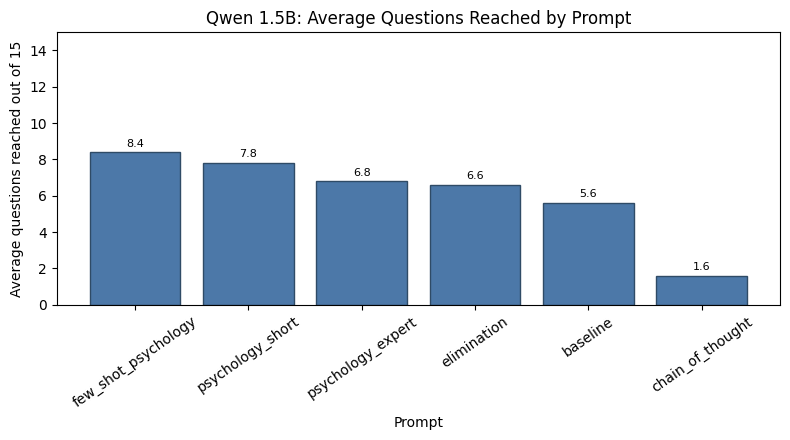

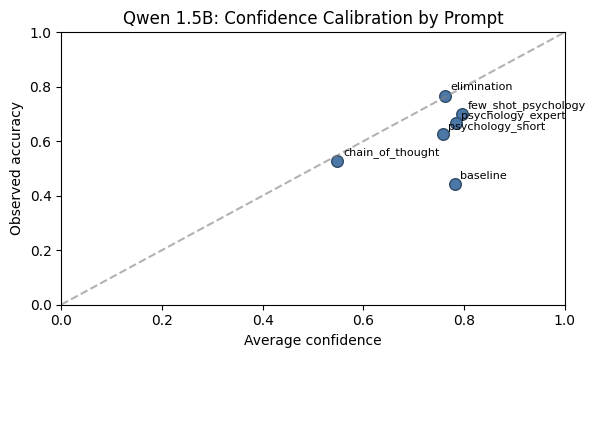

Qwen 1.5B: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
3,qwen_1_5b,qwen_1_5b_few_shot_psychology,few_shot_psychology,5,8.4,12,7.4,37,0.493333,0.733333,17660.0,64000,0.168136,0.238302,1.00,0.493333,non-thinking
5,qwen_1_5b,qwen_1_5b_psychology_short,psychology_short,5,7.8,12,6.8,34,0.453333,0.733333,17040.0,64000,0.144989,0.439383,1.00,0.453333,non-thinking
4,qwen_1_5b,qwen_1_5b_psychology_expert,psychology_expert,5,6.8,10,5.8,29,0.386667,0.600000,5800.0,16000,0.143029,0.298122,0.98,0.386667,non-thinking
2,qwen_1_5b,qwen_1_5b_elimination,elimination,5,6.6,13,5.6,28,0.373333,0.800000,28940.0,128000,0.162880,0.869967,1.00,0.373333,non-thinking
0,qwen_1_5b,qwen_1_5b_baseline,baseline,5,5.6,8,4.6,23,0.306667,0.466667,1420.0,4000,0.189082,0.510629,1.00,0.306667,non-thinking
1,qwen_1_5b,qwen_1_5b_chain_of_thought,chain_of_thought,5,1.6,3,0.6,3,0.040000,0.133333,60.0,200,3.610622,4.484965,1.00,0.040000,non-thinking


Qwen 1.5B: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
5,qwen_1_5b,baseline,Social psychology,3,3,0,1.000000,3.333333,2,0.100000
1,qwen_1_5b,baseline,Ethics & political philosophy,2,2,0,1.000000,2.500000,1,0.133333
0,qwen_1_5b,baseline,Cognitive psychology & memory,1,1,0,1.000000,2.000000,1,0.066667
2,qwen_1_5b,baseline,"Logic, knowledge & metaphysics",1,1,0,1.000000,1.000000,1,0.066667
4,qwen_1_5b,baseline,Philosophers & history of ideas,1,1,0,1.000000,5.000000,1,0.066667
3,qwen_1_5b,baseline,Other philosophy/psychology,20,15,5,0.750000,3.800000,5,0.200000
7,qwen_1_5b,chain_of_thought,Other philosophy/psychology,5,2,3,0.400000,1.600000,3,0.044444
6,qwen_1_5b,chain_of_thought,Ethics & political philosophy,3,1,2,0.333333,1.333333,2,0.033333
10,qwen_1_5b,elimination,Ethics & political philosophy,4,4,0,1.000000,5.000000,4,0.066667
9,qwen_1_5b,elimination,Cognitive psychology & memory,2,2,0,1.000000,2.000000,2,0.066667


,model_label,prompt_type,error_type,count
0,qwen_1_5b,baseline,Correct,23
1,qwen_1_5b,baseline,High-confidence wrong answer,3
2,qwen_1_5b,baseline,Plausible but incorrect answer,2
3,qwen_1_5b,chain_of_thought,Correct,3
4,qwen_1_5b,chain_of_thought,Plausible but incorrect answer,5
5,qwen_1_5b,elimination,Correct,28
6,qwen_1_5b,elimination,High-confidence wrong answer,4
7,qwen_1_5b,elimination,Plausible but incorrect answer,1
8,qwen_1_5b,few_shot_psychology,Correct,37
9,qwen_1_5b,few_shot_psychology,High-confidence wrong answer,4


Qwen 1.5B: confidence coverage


,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate
0,qwen_1_5b,baseline,28,28,1.0
1,qwen_1_5b,chain_of_thought,8,8,1.0
2,qwen_1_5b,elimination,33,33,1.0
3,qwen_1_5b,few_shot_psychology,42,42,1.0
4,qwen_1_5b,psychology_expert,34,34,1.0
5,qwen_1_5b,psychology_short,39,39,1.0


Qwen 1.5B: confidence and overconfidence


,model_label,prompt_type,confidence_bucket,questions,observed_accuracy,average_confidence,average_margin,overconfident_errors
0,qwen_1_5b,baseline,low (<= 0.40),0,NaN,NaN,NaN,0
1,qwen_1_5b,baseline,medium (0.40-0.70),2,0.000000,0.572123,0.156767,0
2,qwen_1_5b,baseline,high (>= 0.70),26,0.884615,0.990748,0.983087,3
3,qwen_1_5b,chain_of_thought,low (<= 0.40),3,0.333333,0.208942,-0.378527,0
4,qwen_1_5b,chain_of_thought,medium (0.40-0.70),4,0.250000,0.550376,0.201550,0
5,qwen_1_5b,chain_of_thought,high (>= 0.70),1,1.000000,0.886144,0.794173,0
6,qwen_1_5b,elimination,low (<= 0.40),0,NaN,NaN,NaN,0
7,qwen_1_5b,elimination,medium (0.40-0.70),3,0.666667,0.547072,0.193370,0
8,qwen_1_5b,elimination,high (>= 0.70),30,0.866667,0.977726,0.960064,4
9,qwen_1_5b,few_shot_psychology,low (<= 0.40),0,NaN,NaN,NaN,0


,model_label,prompt_type,system_name,run_id,level_before_answer,topic,question_text,selected_option_text,raw_response,confidence_score,confidence_margin,option_confidences,correct
94,qwen_1_5b,psychology_expert,qwen_1_5b_psychology_expert,4,9,Cognitive psychology & memory,Which of the following best explains the disti...,S-selection refers to the grammatical structur...,3,0.999988,0.999981,"{""0"": 0.0, ""1"": 4.351139068603516e-06, ""2"": 7....",False
153,qwen_1_5b,few_shot_psychology,qwen_1_5b_few_shot_psychology,2,12,Other philosophy/psychology,What is the primary reason for the devolution ...,To reduce the autonomy of the territories and ...,1,0.999942,0.999916,"{""0"": 6.973743438720703e-06, ""1"": 1.0, ""2"": 2....",False
75,qwen_1_5b,psychology_expert,qwen_1_5b_psychology_expert,2,8,Ethics & political philosophy,How does Mohist ethics evaluate the morality o...,Based on the intentions behind the action,2,0.999700,0.999531,"{""0"": 0.0, ""1"": 0.00016868114471435547, ""2"": 0...",False
175,qwen_1_5b,few_shot_psychology,qwen_1_5b_few_shot_psychology,5,4,Ethics & political philosophy,"In Confucian ethics, what concept emphasizes t...",Lǐ,0,0.999606,0.999420,"{""0"": 0.99951171875, ""1"": 0.000185132026672363...",False
171,qwen_1_5b,few_shot_psychology,qwen_1_5b_few_shot_psychology,4,10,Neuroscience & perception,"According to psychological studies, which brai...",Prefrontal cortex,0,0.999551,0.999194,"{""0"": 0.99951171875, ""1"": 4.26173210144043e-05...",False
129,qwen_1_5b,elimination,qwen_1_5b_elimination,4,13,"Logic, knowledge & metaphysics",Which of the following best represents the for...,◊P ↔ ¬◻¬P,0,0.999073,0.998538,"{""0"": 0.9990234375, ""1"": 0.0005354881286621094...",False
27,qwen_1_5b,baseline,qwen_1_5b_baseline,5,7,Other philosophy/psychology,How does the Hedgehog's Dilemma relate to huma...,It suggests that people should avoid close rel...,3,0.996904,0.993923,"{""0"": 2.7894973754882812e-05, ""1"": 0.002981185...",False
43,qwen_1_5b,psychology_short,qwen_1_5b_psychology_short,2,10,Philosophers & history of ideas,In Aristotle's classification of living things...,Animals with blood,0,0.987721,0.982538,"{""0"": 0.98779296875, ""1"": 0.004364013671875, ""...",False
141,qwen_1_5b,few_shot_psychology,qwen_1_5b_few_shot_psychology,1,8,Other philosophy/psychology,Daniel Dennett was a co-founder of which proje...,The Humanist Project,0,0.982786,0.966904,"{""0"": 0.98291015625, ""1"": 0.0158843994140625, ...",False
102,qwen_1_5b,elimination,qwen_1_5b_elimination,1,2,"Logic, knowledge & metaphysics",Which of the following best describes the core...,The world is composed of mental representations.,3,0.978964,0.960745,"{""0"": 6.777048110961914e-05, ""1"": 0.0182189941...",False


In [ ]:
qwen_1_5b_analysis = analyse_model_runs(
    df_all_prompts,
    model_tag="Qwen 1.5B",
    output_prefix="philosophy_psychology_qwen_1_5b",
    model_type="non-thinking",
)


### Qwen2.5-1.5B conclusion

Qwen2.5-1.5B gave a useful baseline for the Psychology and Philosophy task. The best prompt was `few_shot_psychology`, reaching **8.4 average questions**, a best run of **12**, and **37 / 75 = 0.493 game accuracy**. `psychology_short` was the next strongest setup with **7.8 average questions**.

The model followed the answer format well, but performance changed strongly by prompt. Chain-of-thought was the weakest and slowest setting, reaching only **1.6 average questions** with much longer response time.

By topic, Qwen 1.5B answered many **Other philosophy/psychology**, **logic**, and **ethics** questions correctly, but most errors also came from broad **Other philosophy/psychology** questions. The confidence analysis shows several high-confidence wrong answers, so Qwen 1.5B confidence should be treated cautiously.

## Cleanup before alternative model comparison

Before loading a different model family, the previous model is removed from memory. This reduces the chance of CUDA out-of-memory errors in Colab.


In [ ]:
import gc
import torch

for variable_name in ["model", "tokenizer", "generator"]:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Previous model cleared from memory.")

Previous model cleared from memory.


#Phi

## Model comparison with Phi and DeepSeek


In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_name = "microsoft/Phi-3.5-mini-instruct"

tokenizer = AutoTokenizer.from_pretrained(
    model_name,
    trust_remote_code=True
)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    device_map="auto",
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    trust_remote_code=True,
    attn_implementation="eager"
)

generator = make_text_generation_wrapper(model, tokenizer)

print("Loaded model:", model_name)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/306 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

...

model-00002-of-00002.safetensors:   0%|          | 0.00/2.67G [00:00<?, ?B/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/4.97G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/195 [00:00<?, ?B/s]

Loaded model: microsoft/Phi-3.5-mini-instruct


In [ ]:
#I used this part becuase my phi had a problem

import time
import torch
import re

def generate_answer_for_phi_bugfix(question, prompt_type="psychology_short"):
    # This function directly calls model.generate to explicitly set use_cache=False for Phi models.
    # This addresses the `AttributeError: 'DynamicCache' object has no attribute 'get_max_length'`
    # by bypassing the pipeline's potential internal caching logic.

    # Ensure model and tokenizer are defined from global scope
    if 'model' not in globals() or 'tokenizer' not in globals():
        raise NameError("Model or tokenizer not found. Please ensure they are loaded.")

    # Ensure build_prompt_from_type is defined (from cell vRiOijlXwVLe)
    if 'build_prompt_from_type' not in globals():
        raise NameError("build_prompt_from_type not found. Please ensure cell vRiOijlXwVLe is run.")

    # Ensure generation_token_budget is defined (from cell vRiOijlXwVLe)
    if 'generation_token_budget' not in globals():
        raise NameError("generation_token_budget not found. Please ensure cell vRiOijlXwVLe is run.")

    # Ensure parse_option_id is defined (from cell vRiOijlXwVLe)
    if 'parse_option_id' not in globals():
        raise NameError("parse_option_id not found. Please ensure cell vRiOijlXwVLe is run.")


    prompt = build_prompt_from_type(question, prompt_type)

    messages = [
        {
            "role": "system",
            "content": "You are a Philosophy and Psychology quiz assistant. Return only the numeric option ID. Do not write any explanation.",
        },
        {
            "role": "user",
            "content": prompt,
        },
    ]

    formatted_prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    start_time = time.time()

    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt",
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=generation_token_budget(prompt_type, 10),
            do_sample=False,
            use_cache=False, # The crucial fix for Phi models with DynamicCache issue
            repetition_penalty=1.2,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]
    raw_response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True,
    ).strip()

    response_time = time.time() - start_time
    valid_option_ids = [option.id for option in question.options]
    predicted_id = parse_option_id(raw_response, valid_option_ids)

    return {
        "prompt_type": prompt_type,
        "prompt": prompt,
        "raw_response": raw_response,
        "predicted_id": predicted_id,
        "response_time": response_time,
    }

df_phi_psychology_short = benchmark_prompt(
    prompt_type="psychology_short",
    n_runs=3,
    delay_seconds=1.5,
    model_label="phi_3_mini",
    answer_fn=generate_answer_for_phi_bugfix # Pass the temporary bugfix function
)

df_phi_psychology_short.to_csv(
    "philosophy_psychology_phi_3_mini_psychology_short.csv",
    index=False
)

summarise_results(df_phi_psychology_short)


Running model=phi_3_mini, prompt=psychology_short, run 1/3


Started game session: 239102
System: phi_3_mini_psychology_short

Level 1
Question: What is the fundamental principle of human bonding?
Raw response: 0
Submitted: 0
Correct: True
Response time: 0.54 seconds

Level 2
Question: Which of the following best describes the concept of 'theory of mind'?
Raw response: 1
Submitted: 1
Correct: True
Response time: 0.34 seconds

Level 3
Question: Which of the following best describes the concept of 'Übermensch' in Nietzsche's philosophy?
Raw response: 0
Submitted: 0
Correct: True
Response time: 0.38 seconds

Level 4
Question: According to the historian Louis Hartz, why did American politics develop around a tradition of liberalism?
Raw response: 3
Submitted: 3
Correct: True
Response time: 0.38 seconds

Level 5
Question: Which of the following is a fundamental human need that can be threatened by social rejection, according to Abraham Maslow?
Raw response: 1
Submitted: 1
Correct: True
Response time: 0.43 seconds

Level 6
Question: Which of the follo

,system_name,questions_attempted,correct_answers,valid_output_rate,average_response_time,max_response_time,under_30_seconds_rate,timeouts,average_earned_amount,best_earned_amount,runs,average_confidence,max_confidence,accuracy
0,phi_3_mini_psychology_short,35,32,1.0,0.406583,1.064981,1.0,0,26065.714286,256000,3,NaN,NaN,0.711111


In [ ]:
current_model_label = "phi_3_mini"

In [ ]:
model_prompt_results = []

# Temporarily override the global 'generate_answer' for Phi models
original_generate_answer = generate_answer
is_phi_model = "phi" in current_model_label.lower()

if is_phi_model:
    generate_answer = generate_answer_for_phi_bugfix

for prompt_type in PROMPT_TYPES:
    df_prompt_model = benchmark_prompt(
        prompt_type=prompt_type,
        n_runs=5,
        delay_seconds=1.5,
        model_label=current_model_label
        # answer_fn is not explicitly passed, so it will use the (potentially overridden) global `generate_answer`
    )

    model_prompt_results.append(df_prompt_model)

df_current_model_prompts = pd.concat(model_prompt_results, ignore_index=True)

df_current_model_prompts.to_csv(
    f"philosophy_psychology_{current_model_label}_all_prompts.csv",
    index=False
)

df_current_model_prompts

if is_phi_model:
    generate_answer = original_generate_answer


Running model=phi_3_mini, prompt=baseline, run 1/5
Started game session: 239125
System: phi_3_mini_baseline

Level 1
Question: Which of the following best describes Carl Rogers' contribution to psychology?
Raw response: 3
Submitted: 3
Correct: True
Response time: 0.35 seconds

Level 2
Question: Which philosopher famously divided perceptions into impressions and ideas, stating that impressions are more vivid?
Raw response: 0
Submitted: 0
Correct: True
Response time: 0.39 seconds

Level 3
Question: What concept introduced by Nassim Nicholas Taleb refers to the ability of a system to benefit from disorder and randomness?
Raw response: 1
Submitted: 1
Correct: True
Response time: 0.39 seconds

Level 4
Question: Which of the following best describes synesthesia?
Raw response: 0
Submitted: 0
Correct: True
Response time: 0.39 seconds

Level 5
Question: Which of the following best describes the phenomenon of synesthesia?
Raw response: 1
Submitted: 1
Correct: True
Response time: 0.39 seconds

L

In [ ]:
current_model_prompt_summary = summarise_results(df_current_model_prompts)
current_model_prompt_summary

,system_name,questions_attempted,correct_answers,valid_output_rate,average_response_time,max_response_time,under_30_seconds_rate,timeouts,average_earned_amount,best_earned_amount,runs,average_confidence,max_confidence,accuracy
0,phi_3_mini_baseline,63,60,1.000000,0.408007,0.893696,1.0,0,92500.000000,1024000,5,NaN,NaN,0.800000
1,phi_3_mini_chain_of_thought,5,0,1.000000,13.201392,14.776909,1.0,0,0.000000,0,5,NaN,NaN,0.000000
2,phi_3_mini_elimination,52,48,1.000000,0.419809,0.507190,1.0,0,61621.153846,1024000,5,NaN,NaN,0.640000
3,phi_3_mini_few_shot_psychology,37,33,0.945946,0.761346,1.727515,1.0,0,56213.513514,1024000,5,NaN,NaN,0.440000
4,phi_3_mini_psychology_expert,57,55,1.000000,0.501773,1.198305,1.0,0,108022.807018,1024000,5,NaN,NaN,0.733333
5,phi_3_mini_psychology_short,46,43,1.000000,0.419936,1.070090,1.0,0,89258.695652,1024000,5,NaN,NaN,0.573333


In [ ]:
run_summary_current_model = make_run_summary(df_current_model_prompts)
survival_summary_current_model = make_survival_summary(df_current_model_prompts)

survival_summary_current_model


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy
0,phi_3_mini,phi_3_mini_baseline,baseline,5,12.6,15,12.0,60,0.800000,1.0,525000.0,1024000,0.404949,0.893696,1.000000,0.800000
1,phi_3_mini,phi_3_mini_chain_of_thought,chain_of_thought,5,1.0,1,0.0,0,0.000000,0.0,0.0,0,13.201392,14.776909,1.000000,0.000000
2,phi_3_mini,phi_3_mini_elimination,elimination,5,10.4,15,9.6,48,0.640000,1.0,281860.0,1024000,0.416466,0.507190,1.000000,0.640000
3,phi_3_mini,phi_3_mini_few_shot_psychology,few_shot_psychology,5,7.4,15,6.6,33,0.440000,1.0,206900.0,1024000,0.741693,1.727515,0.964444,0.440000
4,phi_3_mini,phi_3_mini_psychology_expert,psychology_expert,5,11.4,15,11.0,55,0.733333,1.0,615260.0,1024000,0.487452,1.198305,1.000000,0.733333
5,phi_3_mini,phi_3_mini_psychology_short,psychology_short,5,9.2,15,8.6,43,0.573333,1.0,410240.0,1024000,0.439084,1.070090,1.000000,0.573333


In [ ]:
survival_summary_qwen_1_5b = survival_summary.copy()
survival_summary_qwen_1_5b["model_label"] = "qwen_1_5b"

In [ ]:
if "prompt_type" not in survival_summary_qwen_1_5b.columns:
    survival_summary_qwen_1_5b["prompt_type"] = (
        survival_summary_qwen_1_5b["system_name"]
        .str.replace("qwen_1_5b_", "", regex=False)
    )

In [ ]:
[name for name in globals() if "summary" in name or "survival" in name]

['make_run_summary',
 'make_survival_summary',
 'sort_survival_summary',
 'baseline_summary',
 'level_summary',
 'prompt_summary',
 'prompt_summary_5runs',
 'run_summary',
 'survival_summary',
 'current_model_prompt_summary',
 'run_summary_current_model',
 'survival_summary_current_model',
 'survival_summary_qwen_1_5b']

In [ ]:
combined_model_prompt_summary = pd.concat(
    [
        survival_summary_qwen_1_5b,
        survival_summary_current_model
    ],
    ignore_index=True
)

combined_model_prompt_summary

,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type
0,qwen_1_5b_baseline,5,5.6,8,4.6,23,0.306667,0.466667,1420.0,4000,0.189082,0.510629,1.000000,0.306667,qwen_1_5b,baseline
1,qwen_1_5b_chain_of_thought,5,1.6,3,0.6,3,0.040000,0.133333,60.0,200,3.610622,4.484965,1.000000,0.040000,qwen_1_5b,chain_of_thought
2,qwen_1_5b_elimination,5,6.6,13,5.6,28,0.373333,0.800000,28940.0,128000,0.162880,0.869967,1.000000,0.373333,qwen_1_5b,elimination
3,qwen_1_5b_few_shot_psychology,5,8.4,12,7.4,37,0.493333,0.733333,17660.0,64000,0.168136,0.238302,1.000000,0.493333,qwen_1_5b,few_shot_psychology
4,qwen_1_5b_psychology_expert,5,6.8,10,5.8,29,0.386667,0.600000,5800.0,16000,0.143029,0.298122,0.980000,0.386667,qwen_1_5b,psychology_expert
5,qwen_1_5b_psychology_short,5,7.8,12,6.8,34,0.453333,0.733333,17040.0,64000,0.144989,0.439383,1.000000,0.453333,qwen_1_5b,psychology_short
6,phi_3_mini_baseline,5,12.6,15,12.0,60,0.800000,1.000000,525000.0,1024000,0.404949,0.893696,1.000000,0.800000,phi_3_mini,baseline
7,phi_3_mini_chain_of_thought,5,1.0,1,0.0,0,0.000000,0.000000,0.0,0,13.201392,14.776909,1.000000,0.000000,phi_3_mini,chain_of_thought
8,phi_3_mini_elimination,5,10.4,15,9.6,48,0.640000,1.000000,281860.0,1024000,0.416466,0.507190,1.000000,0.640000,phi_3_mini,elimination
9,phi_3_mini_few_shot_psychology,5,7.4,15,6.6,33,0.440000,1.000000,206900.0,1024000,0.741693,1.727515,0.964444,0.440000,phi_3_mini,few_shot_psychology


In [ ]:
phi_errors = df_current_model_prompts[
    df_current_model_prompts["model_label"] == "phi_3_mini"
].copy()

phi_errors = phi_errors[phi_errors["correct"] == False]

phi_errors[
    [
        "prompt_type",
        "level_before_answer",
        "question_text",
        "options",
        "raw_response",
        "selected_option_id",
        "selected_option_text",
        "response_time"
    ]
]

,prompt_type,level_before_answer,question_text,options,raw_response,selected_option_id,selected_option_text,response_time
29,baseline,15,Which of the following best describes the impa...,"[{""id"": 0, ""text"": ""Absolute pitch can introdu...",2,2,Absolute pitch enhances the consistency of chr...,0.391949
56,baseline,12,"According to Mohist philosophy, what concept i...","[{""id"": 0, ""text"": ""The will of Heaven""}, {""id...",3,3,The Five Constants,0.343748
62,baseline,6,How does Vladimir Lenin's perspective on imper...,"[{""id"": 0, ""text"": ""Lenin emphasizes cultural ...",1,1,"Lenin focuses on economic exploitation, while ...",0.404836
99,psychology_short,7,"In Al-Farabi's cosmology, what is the relation...","[{""id"": 0, ""text"": ""Each intellect emanates fr...",0,0,Each intellect emanates from the celestial sph...,0.421146
105,psychology_short,6,How does shame relate to guilt according to cu...,"[{""id"": 0, ""text"": ""Shame arises from the nega...",2,2,"Shame arises from violating internal values, w...",0.402892
108,psychology_short,3,Which of the following best describes 'devolut...,"[{""id"": 0, ""text"": ""A process where subnationa...",3,3,The permanent transfer of power from the centr...,0.406805
157,psychology_expert,4,Which principle of Spanish succession did Carl...,"[{""id"": 0, ""text"": ""Absolute primogeniture""}, ...",2,2,Male-preference primogeniture,0.403081
165,psychology_expert,8,Which of the following best describes the appr...,"[{""id"": 0, ""text"": ""Abandonment of heavy punis...",1,1,Strict adherence to the harsh penal policies o...,0.491444
171,elimination,6,How does the concept of 'divine right' relate ...,"[{""id"": 0, ""text"": ""It reinforces the monarch'...",3,3,It supports the idea that monarchs are subject...,0.408407
175,elimination,4,Which philosopher proposed a basic income as a...,"[{""id"": 0, ""text"": ""Thomas More""}, {""id"": 1, ""...",3,3,Henry George,0.412675


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [ ]:
game = client.game.start(competition_id=comp_id, mode="text")
question = game.current_question

prediction = generate_answer_phi(question, prompt_type="psychology_short")

print("Question:", question.text)
print()

for option in question.options:
    print(f"{option.id}: {option.text}")

print()
print("Raw Phi response:", prediction["raw_response"])
print("Predicted ID:", prediction["predicted_id"])
print("Response time:", prediction["response_time"])

Question: Which theory did Abraham Maslow develop that categorizes human needs into a hierarchy?

0: Behavioral Theory
1: Attachment Theory
2: Maslow's Hierarchy of Needs
3: Cognitive Dissonance Theory

Raw Phi response: 2
Predicted ID: 2
Response time: 0.3440232276916504


In [ ]:
valid_model_prompt_summary = combined_model_prompt_summary[
    combined_model_prompt_summary["valid_output_rate"] > 0.5
].copy()

valid_model_prompt_summary_sorted = valid_model_prompt_summary.sort_values(
    by=[
        "average_questions_reached",
        "average_final_earned_amount",
        "average_response_time"
    ],
    ascending=[False, False, True]
)

valid_model_prompt_summary_sorted

,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type
6,phi_3_mini_baseline,5,12.6,15,12.0,60,0.800000,1.000000,525000.0,1024000,0.404949,0.893696,1.000000,0.800000,phi_3_mini,baseline
10,phi_3_mini_psychology_expert,5,11.4,15,11.0,55,0.733333,1.000000,615260.0,1024000,0.487452,1.198305,1.000000,0.733333,phi_3_mini,psychology_expert
8,phi_3_mini_elimination,5,10.4,15,9.6,48,0.640000,1.000000,281860.0,1024000,0.416466,0.507190,1.000000,0.640000,phi_3_mini,elimination
11,phi_3_mini_psychology_short,5,9.2,15,8.6,43,0.573333,1.000000,410240.0,1024000,0.439084,1.070090,1.000000,0.573333,phi_3_mini,psychology_short
3,qwen_1_5b_few_shot_psychology,5,8.4,12,7.4,37,0.493333,0.733333,17660.0,64000,0.168136,0.238302,1.000000,0.493333,qwen_1_5b,few_shot_psychology
5,qwen_1_5b_psychology_short,5,7.8,12,6.8,34,0.453333,0.733333,17040.0,64000,0.144989,0.439383,1.000000,0.453333,qwen_1_5b,psychology_short
9,phi_3_mini_few_shot_psychology,5,7.4,15,6.6,33,0.440000,1.000000,206900.0,1024000,0.741693,1.727515,0.964444,0.440000,phi_3_mini,few_shot_psychology
4,qwen_1_5b_psychology_expert,5,6.8,10,5.8,29,0.386667,0.600000,5800.0,16000,0.143029,0.298122,0.980000,0.386667,qwen_1_5b,psychology_expert
2,qwen_1_5b_elimination,5,6.6,13,5.6,28,0.373333,0.800000,28940.0,128000,0.162880,0.869967,1.000000,0.373333,qwen_1_5b,elimination
0,qwen_1_5b_baseline,5,5.6,8,4.6,23,0.306667,0.466667,1420.0,4000,0.189082,0.510629,1.000000,0.306667,qwen_1_5b,baseline


In [ ]:
phi_diagnostic_summary = combined_model_prompt_summary[
    combined_model_prompt_summary["model_label"] == "phi_3_mini"
].copy()

phi_diagnostic_summary

,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type
6,phi_3_mini_baseline,5,12.6,15,12.0,60,0.800000,1.0,525000.0,1024000,0.404949,0.893696,1.000000,0.800000,phi_3_mini,baseline
7,phi_3_mini_chain_of_thought,5,1.0,1,0.0,0,0.000000,0.0,0.0,0,13.201392,14.776909,1.000000,0.000000,phi_3_mini,chain_of_thought
8,phi_3_mini_elimination,5,10.4,15,9.6,48,0.640000,1.0,281860.0,1024000,0.416466,0.507190,1.000000,0.640000,phi_3_mini,elimination
9,phi_3_mini_few_shot_psychology,5,7.4,15,6.6,33,0.440000,1.0,206900.0,1024000,0.741693,1.727515,0.964444,0.440000,phi_3_mini,few_shot_psychology
10,phi_3_mini_psychology_expert,5,11.4,15,11.0,55,0.733333,1.0,615260.0,1024000,0.487452,1.198305,1.000000,0.733333,phi_3_mini,psychology_expert
11,phi_3_mini_psychology_short,5,9.2,15,8.6,43,0.573333,1.0,410240.0,1024000,0.439084,1.070090,1.000000,0.573333,phi_3_mini,psychology_short


In [ ]:
valid_model_prompt_summary_sorted.to_csv(
    "philosophy_psychology_valid_model_prompt_comparison.csv",
    index=False
)

phi_diagnostic_summary.to_csv(
    "philosophy_psychology_phi_diagnostic_summary.csv",
    index=False
)

## Phi diagnostic and corrected evaluation

The first Phi experiment showed that model integration can strongly affect performance. The earlier Phi setup sometimes produced repeated fragments or invalid strings, so the notebook adds two corrected approaches:

1. **Chat-template fixed generation**, where Phi uses its own instruction format and produces the final numeric answer.
2. **Forced-choice scoring**, where Phi scores all answer options directly and the highest-scoring option is selected.

This separates answer quality from output-format problems. Fixed generation is tested as the practical answering system, while forced-choice is useful for confidence and reliability analysis.

In [ ]:
import gc
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM


def clear_model_from_memory():
    for variable_name in ["model", "tokenizer", "generator"]:
        if variable_name in globals():
            del globals()[variable_name]

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def load_phi_model():
    global model, tokenizer, model_name, current_model_label

    clear_model_from_memory()

    model_name = "microsoft/Phi-3.5-mini-instruct"
    current_model_label = "phi_3_5_mini_fixed"

    tokenizer = AutoTokenizer.from_pretrained(
        model_name,
        trust_remote_code=True,
    )

    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        device_map="auto",
        torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
        trust_remote_code=True,
        attn_implementation="eager",
    )

    # Add this line to explicitly disable caching in the model's configuration
    if hasattr(model.config, 'use_cache'):
        model.config.use_cache = False

    model.eval()

    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token

    print("Loaded fixed Phi model:", model_name)


load_phi_model()

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded fixed Phi model: microsoft/Phi-3.5-mini-instruct


In [ ]:
def build_phi_chat_text(question, prompt_type="psychology_short"):
    prompt = build_prompt_from_type(question, prompt_type) if "build_prompt_from_type" in globals() else build_prompt_psychology_short(question)

    messages = [
        {
            "role": "user",
            "content": (
                prompt
                + "\n\nReturn exactly one option ID from the list. "
                + "Do not explain. Do not repeat words."
            ),
        }
    ]

    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    ), prompt


def generate_answer_phi_fixed(question, prompt_type="psychology_short"):
    formatted_prompt, prompt = build_phi_chat_text(question, prompt_type)
    start_time = time.time()

    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt",
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=generation_token_budget(prompt_type, 8),
            do_sample=False,
            repetition_penalty=1.05,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
            use_cache=False,
        )

    response_time = time.time() - start_time
    generated_tokens = outputs[0][inputs["input_ids"].shape[-1]:]
    raw_response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True,
    ).strip()

    valid_option_ids = [option.id for option in question.options]

    if "parse_option_id" in globals():
        predicted_id = parse_option_id(raw_response, valid_option_ids)
    else:
        numbers = re.findall(r"\d+", raw_response)
        predicted_id = next(
            (int(number) for number in numbers if int(number) in valid_option_ids),
            None,
        )

    return {
        "prompt_type": prompt_type,
        "prompt": prompt,
        "raw_response": raw_response,
        "predicted_id": predicted_id,
        "response_time": response_time,
    }

In [ ]:
# Backward-compatible name for the Phi section.
score_candidate_continuation = score_candidate_continuation_generic


def generate_answer_phi_scored(question, prompt_type="psychology_short"):
    formatted_prompt, prompt = build_phi_chat_text(question, prompt_type)
    base_text = formatted_prompt + "The correct answer is option"
    start_time = time.time()

    option_scores = {}

    for option in question.options:
        candidate_text = f" {option.id}: {option.text}"
        score, token_count = score_candidate_continuation_generic(
            base_text,
            candidate_text,
            return_token_count=True,
        )
        option_scores[int(option.id)] = {
            "score": score,
            "tokens": token_count,
            "text": option.text,
        }

    predicted_id = max(
        option_scores,
        key=lambda option_id: option_scores[option_id]["score"],
    )

    response_time = time.time() - start_time
    raw_response = json.dumps(option_scores, ensure_ascii=False)

    return {
        "prompt_type": prompt_type,
        "prompt": prompt,
        "raw_response": raw_response,
        "predicted_id": predicted_id,
        "response_time": response_time,
        "option_confidences": {
            option_id: values["score"]
            for option_id, values in option_scores.items()
        },
    }


In [ ]:
def benchmark_phi_answer_fn(
    answer_fn,
    model_label,
    prompt_type="psychology_short",
    n_runs=5,
    delay_seconds=1.5,
):
    return benchmark_answer_fn(
        answer_fn=answer_fn,
        model_label=model_label,
        prompt_type=prompt_type,
        n_runs=n_runs,
        delay_seconds=delay_seconds,
        model_type="non-thinking",
    )


make_phi_survival_summary = make_survival_summary


In [ ]:
game = client.game.start(competition_id=comp_id, mode="text")
question = game.current_question

phi_generated_prediction = generate_answer_phi_fixed(
    question,
    prompt_type="psychology_short",
)
phi_scored_prediction = generate_answer_phi_scored(
    question,
    prompt_type="psychology_short",
)

print("Question:", question.text)
print()

for option in question.options:
    print(f"{option.id}: {option.text}")

print()
print("Phi generated raw response:", phi_generated_prediction["raw_response"])
print("Phi generated predicted ID:", phi_generated_prediction["predicted_id"])
print("Phi scored predicted ID:", phi_scored_prediction["predicted_id"])
print("Phi scored option scores:", phi_scored_prediction["raw_response"])


Question: Which of the following best describes the central tenet of existentialism?

0: The concept that science can explain all aspects of human existence.
1: The belief that society determines the meaning of life.
2: The idea that personal freedom and individual responsibility are essential to finding life's meaning.
3: The notion that religious institutions hold the key to understanding life's purpose.

Phi generated raw response: 2
Phi generated predicted ID: 2
Phi scored predicted ID: 2
Phi scored option scores: {"0": {"score": -1.2661792039871216, "tokens": 15, "text": "The concept that science can explain all aspects of human existence."}, "1": {"score": -0.9105753302574158, "tokens": 14, "text": "The belief that society determines the meaning of life."}, "2": {"score": -0.28125667572021484, "tokens": 20, "text": "The idea that personal freedom and individual responsibility are essential to finding life's meaning."}, "3": {"score": -1.1066811084747314, "tokens": 18, "text": "Th

In [ ]:
df_phi_fixed_generation = benchmark_phi_answer_fn(
    answer_fn=generate_answer_phi_fixed,
    model_label="phi_3_5_mini_fixed_generation",
    prompt_type="psychology_short",
    n_runs=5,
    delay_seconds=1.5,
)

phi_fixed_generation_summary = make_phi_survival_summary(df_phi_fixed_generation)
phi_fixed_generation_summary



Running model=phi_3_5_mini_fixed_generation, prompt=psychology_short, run 1/5
Started game session: 239374
System: phi_3_5_mini_fixed_generation_psychology_short

Level 1
Question: Which of the following best describes Nietzsche's concept of 'perspectivism'?
Raw response: 1
Submitted: 1
Correct: True
Response time: 0.4 seconds

Level 2
Question: Which of the following themes is most prominent in Emil Cioran's philosophical work?
Raw response: 2
Submitted: 2
Correct: True
Response time: 0.34 seconds

Level 3
Question: Which of the following symptoms is most commonly associated with misophonia?
Raw response: 2
Submitted: 2
Correct: True
Response time: 0.35 seconds

Level 4
Question: Which principle is fundamental to anarcho-capitalism, advocating that individuals should be free from coercion by others?
Raw response: 1 Advanced philosophy and psych
Submitted: 1
Correct: True
Response time: 0.7 seconds

Level 5
Question: Which of the following best describes the concept of 'ontological re

,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,phi_3_5_mini_fixed_generation,phi_3_5_mini_fixed_generation_psychology_short,psychology_short,5,14.2,15,13.8,69,0.92,1.0,665600.0,1024000,0.435922,0.80928,1.0,0.92,non-thinking


In [ ]:
df_phi_forced_choice = benchmark_phi_answer_fn(
    answer_fn=generate_answer_phi_scored,
    model_label="phi_3_5_mini_forced_choice",
    prompt_type="psychology_short",
    n_runs=5,
    delay_seconds=1.5,
)

phi_forced_choice_summary = make_phi_survival_summary(df_phi_forced_choice)
phi_forced_choice_summary



Running model=phi_3_5_mini_forced_choice, prompt=psychology_short, run 1/5
Started game session: 239428
System: phi_3_5_mini_forced_choice_psychology_short

Level 1
Question: Which of the following best describes the concept of a social norm?
Raw response: {"0": {"score": -1.2777611017227173, "tokens": 12, "text": "A set of laws codified by a government"}, "1": {"score": -0.49381282925605774, "tokens": 13, "text": "A widely recognized standard of acceptable behavior within a group"}, "2": {"score": -3.6712465286254883, "tokens": 11, "text": "A private belief that guides personal behavior"}, "3": {"score": -1.3486449718475342, "tokens": 13, "text": "An individual's personal preference for certain behaviors"}}
Submitted: 1
Correct: True
Response time: 0.4 seconds

Level 2
Question: Which philosophical theory, developed by George Berkeley, denies the existence of material substance and argues that objects only exist as they are perceived?
Raw response: {"0": {"score": -0.9700470566749573

,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,phi_3_5_mini_forced_choice,phi_3_5_mini_forced_choice_psychology_short,psychology_short,5,5.4,10,4.4,22,0.293333,0.6,4120.0,16000,0.389205,0.514781,1.0,0.293333,non-thinking


In [ ]:
phi_fixed_comparison = pd.concat(
    [
        phi_diagnostic_summary,
        phi_fixed_generation_summary,
        phi_forced_choice_summary,
    ],
    ignore_index=True,
    sort=False,
)

phi_fixed_comparison = phi_fixed_comparison.sort_values(
    by=["average_questions_reached", "best_questions_reached", "average_final_earned_amount"],
    ascending=False,
)

df_phi_fixed_generation.to_csv("philosophy_psychology_phi_fixed_generation_results.csv", index=False)
df_phi_forced_choice.to_csv("philosophy_psychology_phi_forced_choice_results.csv", index=False)
phi_fixed_comparison.to_csv("philosophy_psychology_phi_fixed_comparison.csv", index=False)

phi_fixed_comparison


,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type,model_type
6,phi_3_5_mini_fixed_generation_psychology_short,5,14.2,15,13.8,69,0.920000,1.0,665600.0,1024000,0.435922,0.809280,1.000000,0.920000,phi_3_5_mini_fixed_generation,psychology_short,non-thinking
0,phi_3_mini_baseline,5,12.6,15,12.0,60,0.800000,1.0,525000.0,1024000,0.404949,0.893696,1.000000,0.800000,phi_3_mini,baseline,NaN
4,phi_3_mini_psychology_expert,5,11.4,15,11.0,55,0.733333,1.0,615260.0,1024000,0.487452,1.198305,1.000000,0.733333,phi_3_mini,psychology_expert,NaN
2,phi_3_mini_elimination,5,10.4,15,9.6,48,0.640000,1.0,281860.0,1024000,0.416466,0.507190,1.000000,0.640000,phi_3_mini,elimination,NaN
5,phi_3_mini_psychology_short,5,9.2,15,8.6,43,0.573333,1.0,410240.0,1024000,0.439084,1.070090,1.000000,0.573333,phi_3_mini,psychology_short,NaN
3,phi_3_mini_few_shot_psychology,5,7.4,15,6.6,33,0.440000,1.0,206900.0,1024000,0.741693,1.727515,0.964444,0.440000,phi_3_mini,few_shot_psychology,NaN
7,phi_3_5_mini_forced_choice_psychology_short,5,5.4,10,4.4,22,0.293333,0.6,4120.0,16000,0.389205,0.514781,1.000000,0.293333,phi_3_5_mini_forced_choice,psychology_short,non-thinking
1,phi_3_mini_chain_of_thought,5,1.0,1,0.0,0,0.000000,0.0,0.0,0,13.201392,14.776909,1.000000,0.000000,phi_3_mini,chain_of_thought,NaN


## Phi prompt, topic, error, and confidence analysis

This section analyses the corrected Phi runs before comparing against the later model families.

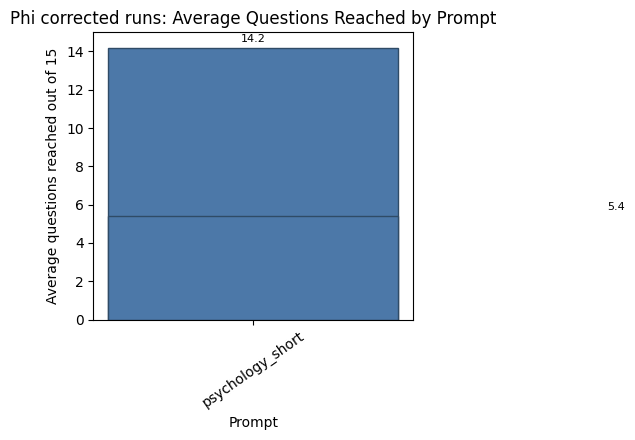

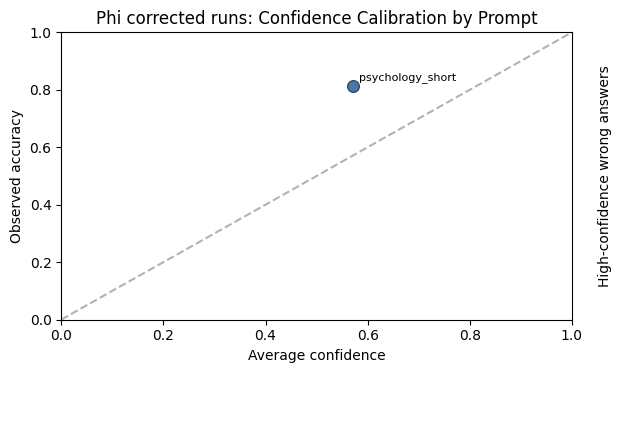

Phi corrected runs: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,phi_3_5_mini_fixed_generation,phi_3_5_mini_fixed_generation_psychology_short,psychology_short,5,14.2,15,13.8,69,0.920000,1.0,665600.0,1024000,0.435922,0.809280,1.0,0.920000,non-thinking
1,phi_3_5_mini_forced_choice,phi_3_5_mini_forced_choice_psychology_short,psychology_short,5,5.4,10,4.4,22,0.293333,0.6,4120.0,16000,0.389205,0.514781,1.0,0.293333,non-thinking


Phi corrected runs: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
0,phi_3_5_mini_fixed_generation,psychology_short,Cognitive psychology & memory,9,9,0,1.000000,6.777778,4,0.150000
6,phi_3_5_mini_fixed_generation,psychology_short,Philosophers & history of ideas,7,7,0,1.000000,10.000000,4,0.116667
2,phi_3_5_mini_fixed_generation,psychology_short,Ethics & political philosophy,5,5,0,1.000000,7.400000,4,0.083333
7,phi_3_5_mini_fixed_generation,psychology_short,Social psychology,5,5,0,1.000000,11.200000,3,0.111111
4,phi_3_5_mini_fixed_generation,psychology_short,"Logic, knowledge & metaphysics",4,4,0,1.000000,5.750000,3,0.088889
9,phi_3_5_mini_forced_choice,psychology_short,Learning & behavior,3,3,0,1.000000,2.666667,1,0.200000
1,phi_3_5_mini_fixed_generation,psychology_short,Developmental psychology,2,2,0,1.000000,10.000000,2,0.066667
3,phi_3_5_mini_fixed_generation,psychology_short,Learning & behavior,1,1,0,1.000000,12.000000,1,0.066667
8,phi_3_5_mini_forced_choice,psychology_short,Ethics & political philosophy,1,1,0,1.000000,6.000000,1,0.066667
11,phi_3_5_mini_forced_choice,psychology_short,Neuroscience & perception,1,1,0,1.000000,6.000000,1,0.066667


,model_label,prompt_type,error_type,count
0,phi_3_5_mini_fixed_generation,psychology_short,Correct,69
1,phi_3_5_mini_fixed_generation,psychology_short,Plausible but incorrect answer,2
2,phi_3_5_mini_forced_choice,psychology_short,Correct,22
3,phi_3_5_mini_forced_choice,psychology_short,Plausible but incorrect answer,5


Phi corrected runs: confidence coverage


,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate
0,phi_3_5_mini_fixed_generation,psychology_short,71,0,0.0
1,phi_3_5_mini_forced_choice,psychology_short,27,27,1.0


Phi corrected runs: confidence and overconfidence


,model_label,prompt_type,confidence_bucket,questions,observed_accuracy,average_confidence,average_margin,overconfident_errors
0,phi_3_5_mini_forced_choice,psychology_short,low (<= 0.40),8,0.500000,0.328930,0.055142,0
1,phi_3_5_mini_forced_choice,psychology_short,medium (0.40-0.70),18,0.944444,0.518011,0.300819,0
2,phi_3_5_mini_forced_choice,psychology_short,high (>= 0.70),1,1.000000,0.869951,0.799196,0


,model_label,prompt_type,system_name,run_id,level_before_answer,topic,question_text,selected_option_text,raw_response,confidence_score,confidence_margin,option_confidences,correct


In [ ]:
df_phi_corrected_runs = pd.concat(
    [
        df_phi_fixed_generation,
        df_phi_forced_choice,
    ],
    ignore_index=True,
    sort=False,
)

phi_corrected_analysis = analyse_model_runs(
    df_phi_corrected_runs,
    model_tag="Phi corrected runs",
    output_prefix="philosophy_psychology_phi_corrected",
    model_type="non-thinking",
)


### Phi corrected-generation interpretation

The corrected Phi run is the strongest result in the notebook. `phi_3_5_mini_fixed_generation_psychology_short` reached **14.2 average questions**, a best run of **15**, and **69 / 75 = 0.920 game accuracy**, with a valid-output rate of **1.0** and fast responses.

The forced-choice Phi version performed lower in survival performance, reaching **5.4 average questions** and **22 / 75 = 0.293 game accuracy**. However, it is still useful for confidence analysis. Its confidence buckets show no overconfident errors, and accuracy improves as confidence increases.

The remaining Phi errors were mainly **plausible but incorrect answers**, especially in broader **Other philosophy/psychology** questions. This suggests that after fixing generation, Phi's main limitation is not formatting but occasional conceptual confusion between close answer options.

# Qwen2.5-3B model comparison

In [ ]:
model_name = "Qwen/Qwen2.5-3B-Instruct"

In [ ]:
import gc
import torch

for variable_name in ["model", "tokenizer", "generator"]:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Previous model cleared.")

Previous model cleared.


In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_name = "Qwen/Qwen2.5-3B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    device_map="auto",
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32
)

generator = make_text_generation_wrapper(model, tokenizer)

print("Loaded model:", model_name)

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

...

model-00002-of-00002.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.97G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded model: Qwen/Qwen2.5-3B-Instruct


In [ ]:
current_model_label = "qwen_3b"

qwen3b_results = []

for prompt_type in PROMPT_TYPES:
    df_qwen3b_prompt = benchmark_prompt(
        prompt_type=prompt_type,
        n_runs=5,
        delay_seconds=1.5,
        model_label=current_model_label,
        answer_fn=generate_answer_chat_template_with_confidence,
        model_type="non-thinking",
    )

    qwen3b_results.append(df_qwen3b_prompt)

df_qwen3b_prompts = pd.concat(qwen3b_results, ignore_index=True)

df_qwen3b_prompts.to_csv(
    "philosophy_psychology_qwen_3b_prompts.csv",
    index=False,
)

df_qwen3b_prompts



Running model=qwen_3b, prompt=baseline, run 1/5
Started game session: 239622
System: qwen_3b_baseline


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1
Question: Which of the following best describes the fundamental principle of totalitarianism?
Raw response: 3
Submitted: 3
Correct: True
Response time: 0.4 seconds


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 2
Question: Which of the following best describes cognitive dissonance?
Raw response: 0
Submitted: 0
Correct: True
Response time: 0.17 seconds


...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 3
Question: Which of the following best describes the term 'imperialism'?
Raw response: Step 1: Analyze each option.
- Option 0 describes an equal distribution of power, which is not related to imperialism.
- Option 1 emphasizes individual freedom, which is unrelated to imperialism.
- Option 2 talks about maintaining and extending power over foreign nations, matching the definition of imperialism.
- Option 3 focuses on internal affairs, which contradicts the concept of imperialism.

Final answer: 2
Submitted: 2
Correct: True
Response time: 4.22 seconds


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 4
Question: What theory suggests that men and women have different sexual and romantic preferences due to biological wiring?
Raw response: Step 1: Identify the key terms in the question - "different sexual and romantic preferences", "biological wiring".
Step 2: Analyze each option:
   - Sexual scripting theory: Focuses on learned behaviors rather than biology.
   - Behavioral addiction theory: Also focuses on learned behaviors and external factors.
   - Sexual strategies theory: Suggests differences based on evolutionary biology and mating strategies.
   - Compulsive sexual behavior theory: Deals with compulsive behaviors rather than
Submitted: 1
Correct: False
Response time: 4.64 seconds
Game ended.


,system_name,session_id,level_before_answer,question_id,question_text,question_length,options,selected_option_id,selected_option_text,model_name,...,correct,timed_out,game_over,earned_amount,confidence_score,confidence_margin,option_confidences,run_id,model_label,model_type
0,qwen_3b_baseline,239622,1,7636,Which of the following best describes the fund...,11,"[{""id"": 0, ""text"": ""Promoting individual freed...",3,Total control over both public and private sph...,Qwen/Qwen2.5-3B-Instruct,...,True,False,False,100,1.000000,1.000000,"{""0"": 0.0, ""1"": 0.0, ""2"": 0.0, ""3"": 1.0}",1,qwen_3b,non-thinking
1,qwen_3b_baseline,239622,2,7412,Which of the following best describes cognitiv...,8,"[{""id"": 0, ""text"": ""The discomfort felt when h...",0,The discomfort felt when holding two conflicti...,Qwen/Qwen2.5-3B-Instruct,...,True,False,False,200,0.996727,0.993453,"{""0"": 0.99658203125, ""1"": 0.00327301025390625,...",1,qwen_3b,non-thinking
2,qwen_3b_baseline,239622,3,8067,Which of the following best describes the phil...,16,"[{""id"": 0, ""text"": ""A finite number used in ev...",1,A concept boundless and limitless,Qwen/Qwen2.5-3B-Instruct,...,True,False,False,300,0.999987,0.999974,"{""0"": 5.960464477539063e-08, ""1"": 1.0, ""2"": 1....",1,qwen_3b,non-thinking
3,qwen_3b_baseline,239622,4,8985,Which of the following best describes the conc...,14,"[{""id"": 0, ""text"": ""The feeling of being in cl...",0,"The feeling of being in close, personal associ...",Qwen/Qwen2.5-3B-Instruct,...,True,False,False,500,0.993709,0.987418,"{""0"": 0.99365234375, ""1"": 0.006290435791015625...",1,qwen_3b,non-thinking
4,qwen_3b_baseline,239622,5,9852,Which of the following best describes Kwame An...,14,"[{""id"": 0, ""text"": ""Theories of meaning""}, {""i...",1,Philosophical problems of race and racism,Qwen/Qwen2.5-3B-Instruct,...,True,False,False,1000,0.999762,0.999524,"{""0"": 1.1920928955078125e-07, ""1"": 1.0, ""2"": 0...",1,qwen_3b,non-thinking
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202,qwen_3b_chain_of_thought,239799,4,8682,Which document outlines the principles of the ...,10,"[{""id"": 0, ""text"": ""The Black Book""}, {""id"": 1...",0,The Black Book,Qwen/Qwen2.5-3B-Instruct,...,False,False,True,300,0.032166,-0.447822,"{""0"": 0.03216552734375, ""1"": 0.47998046875, ""2...",4,qwen_3b,non-thinking
203,qwen_3b_chain_of_thought,239806,1,7192,Which of the following concepts is central to ...,12,"[{""id"": 0, ""text"": ""Nuclear deterrence""}, {""id...",3,Turn the other cheek,Qwen/Qwen2.5-3B-Instruct,...,True,False,False,100,0.490583,0.183633,"{""0"": 0.032867431640625, ""1"": 0.306884765625, ...",5,qwen_3b,non-thinking
204,qwen_3b_chain_of_thought,239806,2,9697,Which of the following best describes dehumani...,7,"[{""id"": 0, ""text"": ""The process of giving huma...",2,The process of treating individuals or groups ...,Qwen/Qwen2.5-3B-Instruct,...,True,False,False,200,0.999601,0.999424,"{""0"": 0.0001766681671142578, ""1"": 0.0001584291...",5,qwen_3b,non-thinking
205,qwen_3b_chain_of_thought,239806,3,8040,Which of the following best describes the term...,9,"[{""id"": 0, ""text"": ""A form of government where...",2,The maintaining and extending of power over fo...,Qwen/Qwen2.5-3B-Instruct,...,True,False,False,300,0.989871,0.984595,"{""0"": 0.00458526611328125, ""1"": 0.005275726318...",5,qwen_3b,non-thinking


In [ ]:
run_summary_qwen3b = make_run_summary(df_qwen3b_prompts)
survival_summary_qwen3b = make_survival_summary(df_qwen3b_prompts)

survival_summary_qwen3b


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,qwen_3b,qwen_3b_baseline,baseline,5,10.0,15,9.2,46,0.613333,1.000000,216100.0,1024000,0.188246,0.402841,1.0,0.613333,non-thinking
1,qwen_3b,qwen_3b_chain_of_thought,chain_of_thought,5,4.0,7,3.0,15,0.200000,0.400000,580.0,2000,3.166162,5.563014,1.0,0.200000,non-thinking
2,qwen_3b,qwen_3b_elimination,elimination,5,4.6,8,3.6,18,0.240000,0.466667,1320.0,4000,0.185861,0.252995,1.0,0.240000,non-thinking
3,qwen_3b,qwen_3b_few_shot_psychology,few_shot_psychology,5,10.2,15,9.6,48,0.640000,1.000000,422560.0,1024000,0.274265,0.315287,1.0,0.640000,non-thinking
4,qwen_3b,qwen_3b_psychology_expert,psychology_expert,5,4.4,7,3.4,17,0.226667,0.400000,820.0,2000,0.200961,0.267609,1.0,0.226667,non-thinking
5,qwen_3b,qwen_3b_psychology_short,psychology_short,5,8.2,14,7.2,36,0.480000,0.866667,58160.0,256000,0.181930,0.278965,1.0,0.480000,non-thinking


In [ ]:
qwen_comparison_summary = pd.concat(
    [
        survival_summary_qwen_1_5b,
        survival_summary_qwen3b
    ],
    ignore_index=True
)

qwen_comparison_summary_sorted = qwen_comparison_summary.sort_values(
    by=[
        "average_questions_reached",
        "average_final_earned_amount",
        "average_response_time"
    ],
    ascending=[False, False, True]
)

qwen_comparison_summary_sorted

,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type,model_type
9,qwen_3b_few_shot_psychology,5,10.2,15,9.6,48,0.640000,1.000000,422560.0,1024000,0.274265,0.315287,1.00,0.640000,qwen_3b,few_shot_psychology,non-thinking
6,qwen_3b_baseline,5,10.0,15,9.2,46,0.613333,1.000000,216100.0,1024000,0.188246,0.402841,1.00,0.613333,qwen_3b,baseline,non-thinking
3,qwen_1_5b_few_shot_psychology,5,8.4,12,7.4,37,0.493333,0.733333,17660.0,64000,0.168136,0.238302,1.00,0.493333,qwen_1_5b,few_shot_psychology,NaN
11,qwen_3b_psychology_short,5,8.2,14,7.2,36,0.480000,0.866667,58160.0,256000,0.181930,0.278965,1.00,0.480000,qwen_3b,psychology_short,non-thinking
5,qwen_1_5b_psychology_short,5,7.8,12,6.8,34,0.453333,0.733333,17040.0,64000,0.144989,0.439383,1.00,0.453333,qwen_1_5b,psychology_short,NaN
4,qwen_1_5b_psychology_expert,5,6.8,10,5.8,29,0.386667,0.600000,5800.0,16000,0.143029,0.298122,0.98,0.386667,qwen_1_5b,psychology_expert,NaN
2,qwen_1_5b_elimination,5,6.6,13,5.6,28,0.373333,0.800000,28940.0,128000,0.162880,0.869967,1.00,0.373333,qwen_1_5b,elimination,NaN
0,qwen_1_5b_baseline,5,5.6,8,4.6,23,0.306667,0.466667,1420.0,4000,0.189082,0.510629,1.00,0.306667,qwen_1_5b,baseline,NaN
8,qwen_3b_elimination,5,4.6,8,3.6,18,0.240000,0.466667,1320.0,4000,0.185861,0.252995,1.00,0.240000,qwen_3b,elimination,non-thinking
10,qwen_3b_psychology_expert,5,4.4,7,3.4,17,0.226667,0.400000,820.0,2000,0.200961,0.267609,1.00,0.226667,qwen_3b,psychology_expert,non-thinking


In [ ]:
qwen_comparison_summary_sorted.to_csv(
    "philosophy_psychology_qwen_model_prompt_comparison.csv",
    index=False
)

print("Qwen model comparison saved.")

Qwen model comparison saved.


## Qwen 3B prompt, topic, error, and confidence analysis

This cell keeps the Qwen 3B analysis next to the Qwen 3B run, instead of waiting until the end of the notebook.


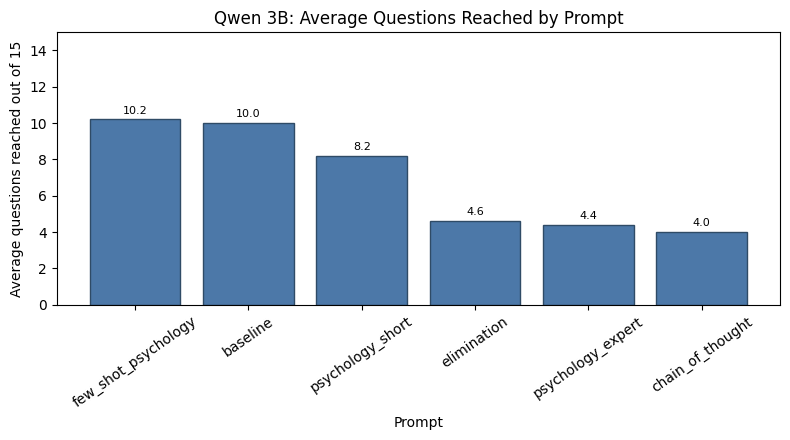

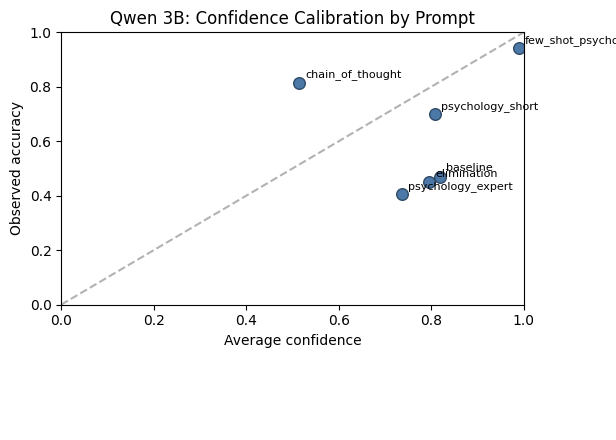

Qwen 3B: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
3,qwen_3b,qwen_3b_few_shot_psychology,few_shot_psychology,5,10.2,15,9.6,48,0.640000,1.000000,422560.0,1024000,0.274265,0.315287,1.0,0.640000,non-thinking
0,qwen_3b,qwen_3b_baseline,baseline,5,10.0,15,9.2,46,0.613333,1.000000,216100.0,1024000,0.188246,0.402841,1.0,0.613333,non-thinking
5,qwen_3b,qwen_3b_psychology_short,psychology_short,5,8.2,14,7.2,36,0.480000,0.866667,58160.0,256000,0.181930,0.278965,1.0,0.480000,non-thinking
2,qwen_3b,qwen_3b_elimination,elimination,5,4.6,8,3.6,18,0.240000,0.466667,1320.0,4000,0.185861,0.252995,1.0,0.240000,non-thinking
4,qwen_3b,qwen_3b_psychology_expert,psychology_expert,5,4.4,7,3.4,17,0.226667,0.400000,820.0,2000,0.200961,0.267609,1.0,0.226667,non-thinking
1,qwen_3b,qwen_3b_chain_of_thought,chain_of_thought,5,4.0,7,3.0,15,0.200000,0.400000,580.0,2000,3.166162,5.563014,1.0,0.200000,non-thinking


Qwen 3B: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
1,qwen_3b,baseline,Ethics & political philosophy,5,5,0,1.000000,6.000000,3,0.111111
2,qwen_3b,baseline,Learning & behavior,2,2,0,1.000000,8.000000,2,0.066667
4,qwen_3b,baseline,Neuroscience & perception,2,2,0,1.000000,5.500000,2,0.066667
0,qwen_3b,baseline,Cognitive psychology & memory,1,1,0,1.000000,2.000000,1,0.066667
5,qwen_3b,baseline,Other philosophy/psychology,21,20,1,0.952381,5.809524,5,0.266667
3,qwen_3b,baseline,"Logic, knowledge & metaphysics",11,10,1,0.909091,6.000000,4,0.166667
7,qwen_3b,baseline,Social psychology,7,6,1,0.857143,6.285714,4,0.100000
6,qwen_3b,baseline,Philosophers & history of ideas,1,0,1,0.000000,10.000000,1,0.000000
9,qwen_3b,chain_of_thought,Other philosophy/psychology,19,15,4,0.789474,2.894737,5,0.200000
8,qwen_3b,chain_of_thought,"Logic, knowledge & metaphysics",1,0,1,0.000000,4.000000,1,0.000000


,model_label,prompt_type,error_type,count
0,qwen_3b,baseline,Correct,46
1,qwen_3b,baseline,High-confidence wrong answer,3
2,qwen_3b,baseline,Plausible but incorrect answer,1
3,qwen_3b,chain_of_thought,Correct,15
4,qwen_3b,chain_of_thought,Plausible but incorrect answer,5
5,qwen_3b,elimination,Correct,18
6,qwen_3b,elimination,High-confidence wrong answer,2
7,qwen_3b,elimination,Plausible but incorrect answer,3
8,qwen_3b,few_shot_psychology,Correct,48
9,qwen_3b,few_shot_psychology,High-confidence wrong answer,3


Qwen 3B: confidence coverage


,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate
0,qwen_3b,baseline,50,50,1.0
1,qwen_3b,chain_of_thought,20,20,1.0
2,qwen_3b,elimination,23,23,1.0
3,qwen_3b,few_shot_psychology,51,51,1.0
4,qwen_3b,psychology_expert,22,22,1.0
5,qwen_3b,psychology_short,41,41,1.0


Qwen 3B: confidence and overconfidence


,model_label,prompt_type,confidence_bucket,questions,observed_accuracy,average_confidence,average_margin,overconfident_errors
0,qwen_3b,baseline,low (<= 0.40),0,NaN,NaN,NaN,0
1,qwen_3b,baseline,medium (0.40-0.70),1,0.000000,0.651367,0.302734,0
2,qwen_3b,baseline,high (>= 0.70),49,0.938776,0.988626,0.977315,3
3,qwen_3b,chain_of_thought,low (<= 0.40),9,0.444444,0.097896,-0.612569,0
4,qwen_3b,chain_of_thought,medium (0.40-0.70),2,1.000000,0.454016,0.104389,0
5,qwen_3b,chain_of_thought,high (>= 0.70),9,1.000000,0.992533,0.987275,0
6,qwen_3b,elimination,low (<= 0.40),0,NaN,NaN,NaN,0
7,qwen_3b,elimination,medium (0.40-0.70),3,0.000000,0.610336,0.264645,0
8,qwen_3b,elimination,high (>= 0.70),20,0.900000,0.981925,0.963997,2
9,qwen_3b,few_shot_psychology,low (<= 0.40),0,NaN,NaN,NaN,0


,model_label,prompt_type,system_name,run_id,level_before_answer,topic,question_text,selected_option_text,raw_response,confidence_score,confidence_margin,option_confidences,correct
147,qwen_3b,few_shot_psychology,qwen_3b_few_shot_psychology,1,12,Other philosophy/psychology,Which ideology combines elements of Christiani...,White American Resistance,3,0.999999,0.999997,"{""0"": 0.0, ""1"": 2.384185791015625e-07, ""2"": 1....",False
135,qwen_3b,elimination,qwen_3b_elimination,5,2,Other philosophy/psychology,What does the shopping cart theory primarily j...,Their shopping habits,3,0.999507,0.999019,"{""0"": 6.556510925292969e-07, ""1"": 4.4107437133...",False
76,qwen_3b,psychology_short,qwen_3b_psychology_short,4,5,Cognitive psychology & memory,Which philosopher is known for his critique of...,Immanuel Kant,1,0.991684,0.983368,"{""0"": 0.0083160400390625, ""1"": 0.99169921875, ...",False
98,qwen_3b,psychology_expert,qwen_3b_psychology_expert,2,6,Cognitive psychology & memory,"In the context of linguistics, how does pragma...","Pragmatics is the study of speech sounds, whil...",1,0.987574,0.975149,"{""0"": 0.01242828369140625, ""1"": 0.98779296875,...",False
152,qwen_3b,few_shot_psychology,qwen_3b_few_shot_psychology,2,5,Learning & behavior,Which term describes the phenomenon where peop...,Premovement buildup,3,0.984570,0.969140,"{""0"": 1.1920928955078125e-07, ""1"": 3.576278686...",False
29,qwen_3b,baseline,qwen_3b_baseline,3,11,Social psychology,What is the primary reason why moral panics ca...,Accurate and unbiased media reporting,1,0.975571,0.951142,"{""0"": 0.0244293212890625, ""1"": 0.9755859375, ""...",False
18,qwen_3b,baseline,qwen_3b_baseline,2,9,Other philosophy/psychology,Which of the following best describes the term...,A hypersensitivity to sound volume,1,0.971522,0.943100,"{""0"": 0.0284271240234375, ""1"": 0.9716796875, ""...",False
9,qwen_3b,baseline,qwen_3b_baseline,1,10,Philosophers & history of ideas,How did Averroes classify his commentaries on ...,"Into four categories: short, medium, long, and...",2,0.941606,0.883244,"{""0"": 1.7881393432617188e-07, ""1"": 3.176927566...",False
90,qwen_3b,psychology_short,qwen_3b_psychology_short,5,14,Philosophers & history of ideas,Which of the following is a key distinction in...,Gender is determined at birth and is immutable.,2,0.939911,0.879824,"{""0"": 2.980232238769531e-07, ""1"": 0.0600891113...",False
105,qwen_3b,psychology_expert,qwen_3b_psychology_expert,4,1,Ethics & political philosophy,What term describes the state of being aware o...,Perception,0,0.921400,0.843396,"{""0"": 0.92138671875, ""1"": 0.0780029296875, ""2""...",False


In [ ]:
qwen_3b_analysis = analyse_model_runs(
    df_qwen3b_prompts,
    model_tag="Qwen 3B",
    output_prefix="philosophy_psychology_qwen_3b",
    model_type="non-thinking",
)


### Qwen 3B comparison, error, and confidence interpretation

Qwen2.5-3B improved over Qwen2.5-1.5B, but it still did not beat the best Phi setup. The best Qwen 3B prompt was `few_shot_psychology`, reaching **10.2 average questions**, a best run of **15**, and **48 / 75 = 0.640 game accuracy**. The `baseline` prompt was close behind with **10.0 average questions** and **46 / 75 = 0.613 game accuracy**.

This shows that increasing model size helped Qwen, because the best Qwen 1.5B setup reached **8.4 average questions**. However, the improvement was smaller than the difference between model families. Qwen 3B was also fast enough for the game, while chain-of-thought was slower and weaker.

By topic, Qwen 3B answered many **Other philosophy/psychology**, **logic**, **ethics**, and **social psychology** questions correctly. Most errors came from **Other philosophy/psychology** and **Logic, knowledge & metaphysics**. The confidence analysis shows some overconfidence: several wrong answers were given with high confidence, so Qwen 3B confidence scores should be interpreted carefully.

In [ ]:
load_phi_model()

df_final_model = benchmark_phi_answer_fn(
    answer_fn=generate_answer_phi_scored,
    model_label="phi_3_5_mini_final_forced_choice",
    prompt_type="psychology_short",
    n_runs=10,
    delay_seconds=1.5,
)

df_final_model.to_csv(
    "philosophy_psychology_final_phi_3_5_mini_forced_choice_10runs.csv",
    index=False,
)

df_final_model


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded fixed Phi model: microsoft/Phi-3.5-mini-instruct

Running model=phi_3_5_mini_final_forced_choice, prompt=psychology_short, run 1/10
Started game session: 239836
System: phi_3_5_mini_final_forced_choice_psychology_short

Level 1
Question: What term describes the study of the nature of reality, knowledge, and existence?
Raw response: {"0": {"score": -4.333949089050293, "tokens": 5, "text": "Mathematics"}, "1": {"score": -6.083086967468262, "tokens": 5, "text": "Biology"}, "2": {"score": -6.503335952758789, "tokens": 4, "text": "Physics"}, "3": {"score": -1.4557844400405884, "tokens": 5, "text": "Philosophy"}}
Submitted: 3
Correct: True
Response time: 0.43 seconds

Level 2
Question: What did John Henry Newman famously say about the value of studying history?
Raw response: {"0": {"score": -0.43807175755500793, "tokens": 16, "text": "The past is a foreign country; they do things differently there."}, "1": {"score": -0.6407859325408936, "tokens": 13, "text": "History is just one damne

,system_name,session_id,level_before_answer,question_id,question_text,question_length,options,selected_option_id,selected_option_text,model_name,...,correct,timed_out,game_over,earned_amount,confidence_score,confidence_margin,option_confidences,run_id,model_label,model_type
0,phi_3_5_mini_final_forced_choice_psychology_short,239836,1,7035,What term describes the study of the nature of...,13,"[{""id"": 0, ""text"": ""Mathematics""}, {""id"": 1, ""...",3,Philosophy,microsoft/Phi-3.5-mini-instruct,...,True,False,False,100,None,None,"{""0"": -4.333949089050293, ""1"": -6.083086967468...",1,phi_3_5_mini_final_forced_choice,non-thinking
1,phi_3_5_mini_final_forced_choice_psychology_short,239836,2,8210,What did John Henry Newman famously say about ...,13,"[{""id"": 0, ""text"": ""The past is a foreign coun...",3,To be deep in history is to cease to be a Prot...,microsoft/Phi-3.5-mini-instruct,...,True,False,False,200,None,None,"{""0"": -0.43807175755500793, ""1"": -0.6407859325...",1,phi_3_5_mini_final_forced_choice,non-thinking
2,phi_3_5_mini_final_forced_choice_psychology_short,239836,3,10263,Which of the following best describes the conc...,12,"[{""id"": 0, ""text"": ""A subjective feeling about...",3,A moral requirement to perform or refrain from...,microsoft/Phi-3.5-mini-instruct,...,True,False,False,300,None,None,"{""0"": -1.1829501390457153, ""1"": -1.47014641761...",1,phi_3_5_mini_final_forced_choice,non-thinking
3,phi_3_5_mini_final_forced_choice_psychology_short,239836,4,7916,What is the fundamental principle of utilitari...,7,"[{""id"": 0, ""text"": ""Maximizing individual righ...",2,Maximizing overall happiness,microsoft/Phi-3.5-mini-instruct,...,True,False,False,500,None,None,"{""0"": -4.223485469818115, ""1"": -3.909963130950...",1,phi_3_5_mini_final_forced_choice,non-thinking
4,phi_3_5_mini_final_forced_choice_psychology_short,239836,5,7655,What term describes the political ideology tha...,20,"[{""id"": 0, ""text"": ""Toryism""}, {""id"": 1, ""text...",3,Jacobitism,microsoft/Phi-3.5-mini-instruct,...,True,False,False,1000,None,None,"{""0"": -3.581003427505493, ""1"": -6.680523872375...",1,phi_3_5_mini_final_forced_choice,non-thinking
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98,phi_3_5_mini_final_forced_choice_psychology_short,239934,12,9801,Which of the following best describes the crit...,19,"[{""id"": 0, ""text"": ""Bro culture is praised for...",3,Bro culture is seen as a misogynistic culture ...,microsoft/Phi-3.5-mini-instruct,...,True,False,False,128000,None,None,"{""0"": -1.3020344972610474, ""1"": -1.09310925006...",9,phi_3_5_mini_final_forced_choice,non-thinking
99,phi_3_5_mini_final_forced_choice_psychology_short,239934,13,9151,What is the main argument in favor of embodied...,14,"[{""id"": 0, ""text"": ""Cognition and emotion deve...",0,Cognition and emotion development are initiate...,microsoft/Phi-3.5-mini-instruct,...,True,False,False,256000,None,None,"{""0"": -0.24876944720745087, ""1"": -0.5532493591...",9,phi_3_5_mini_final_forced_choice,non-thinking
100,phi_3_5_mini_final_forced_choice_psychology_short,239934,14,7315,What is the primary reason Descartes invokes t...,19,"[{""id"": 0, ""text"": ""To demonstrate that the ma...",1,To argue that only a perfect being can be the ...,microsoft/Phi-3.5-mini-instruct,...,True,False,False,512000,None,None,"{""0"": -0.9371361136436462, ""1"": -0.25043445825...",9,phi_3_5_mini_final_forced_choice,non-thinking
101,phi_3_5_mini_final_forced_choice_psychology_short,239934,15,8770,"According to Sun Yat-sen, what is the role of ...",16,"[{""id"": 0, ""text"": ""To establish a military di...",1,"To exert control through suffrage, recall, ini...",microsoft/Phi-3.5-mini-instruct,...,True,False,True,1024000,None,None,"{""0"": -1.3008759021759033, ""1"": -0.24115361273...",9,phi_3_5_mini_final_forced_choice,non-thinking


In [ ]:
final_run_summary = make_run_summary(df_final_model)
final_survival_summary = make_survival_summary(df_final_model)

final_survival_summary


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,phi_3_5_mini_final_forced_choice,phi_3_5_mini_final_forced_choice_psychology_short,psychology_short,10,10.3,15,9.6,96,0.64,1.0,368930.0,1024000,0.393419,0.527117,1.0,0.64,non-thinking


## Final Phi run topic, error, and confidence analysis

This cell analyses the repeated final Phi forced-choice run immediately after it finishes, using the same tables as the other model sections.


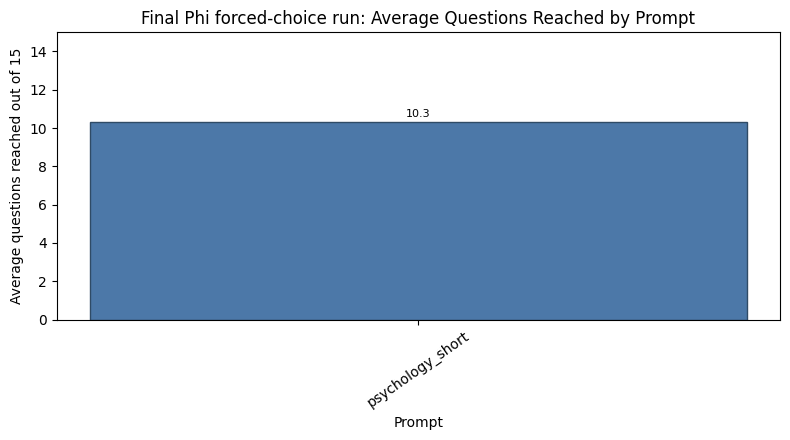

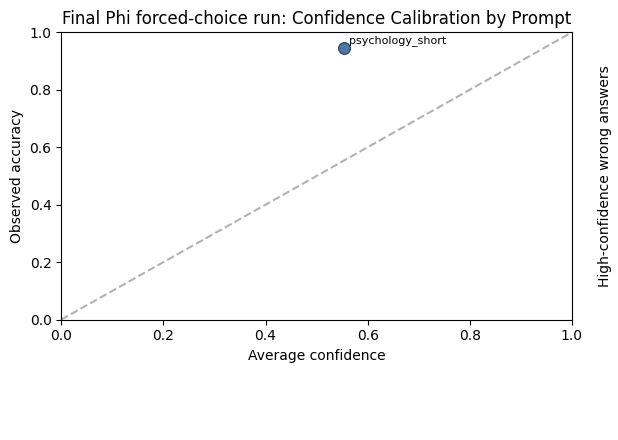

Final Phi forced-choice run: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,phi_3_5_mini_final_forced_choice,phi_3_5_mini_final_forced_choice_psychology_short,psychology_short,10,10.3,15,9.6,96,0.64,1.0,368930.0,1024000,0.393419,0.527117,1.0,0.64,non-thinking


Final Phi forced-choice run: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
5,phi_3_5_mini_final_forced_choice,psychology_short,"Logic, knowledge & metaphysics",12,12,0,1.000000,7.666667,6,0.133333
1,phi_3_5_mini_final_forced_choice,psychology_short,Cognitive psychology & memory,8,8,0,1.000000,7.000000,6,0.088889
4,phi_3_5_mini_final_forced_choice,psychology_short,Learning & behavior,4,4,0,1.000000,3.750000,4,0.066667
0,phi_3_5_mini_final_forced_choice,psychology_short,Clinical psychology & mental health,1,1,0,1.000000,7.000000,1,0.066667
2,phi_3_5_mini_final_forced_choice,psychology_short,Developmental psychology,1,1,0,1.000000,1.000000,1,0.066667
6,phi_3_5_mini_final_forced_choice,psychology_short,Other philosophy/psychology,52,48,4,0.923077,7.192308,9,0.355556
3,phi_3_5_mini_final_forced_choice,psychology_short,Ethics & political philosophy,12,11,1,0.916667,5.416667,7,0.104762
8,phi_3_5_mini_final_forced_choice,psychology_short,Social psychology,8,7,1,0.875000,8.250000,5,0.093333
7,phi_3_5_mini_final_forced_choice,psychology_short,Philosophers & history of ideas,5,4,1,0.800000,5.000000,5,0.053333


,model_label,prompt_type,error_type,count
0,phi_3_5_mini_final_forced_choice,psychology_short,Correct,96
1,phi_3_5_mini_final_forced_choice,psychology_short,Plausible but incorrect answer,7


Final Phi forced-choice run: confidence coverage


,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate
0,phi_3_5_mini_final_forced_choice,psychology_short,103,103,1.0


Final Phi forced-choice run: confidence and overconfidence


,model_label,prompt_type,confidence_bucket,questions,observed_accuracy,average_confidence,average_margin,overconfident_errors
0,phi_3_5_mini_final_forced_choice,psychology_short,low (<= 0.40),39,0.871795,0.346952,0.095408,0
1,phi_3_5_mini_final_forced_choice,psychology_short,medium (0.40-0.70),51,0.960784,0.490120,0.264883,0
2,phi_3_5_mini_final_forced_choice,psychology_short,high (>= 0.70),13,1.000000,0.823071,0.724166,0


,model_label,prompt_type,system_name,run_id,level_before_answer,topic,question_text,selected_option_text,raw_response,confidence_score,confidence_margin,option_confidences,correct


In [ ]:
final_phi_analysis = analyse_model_runs(
    df_final_model,
    model_tag="Final Phi forced-choice run",
    output_prefix="philosophy_psychology_final_phi_3_5_mini_forced_choice",
    model_type="non-thinking",
)


In [ ]:
selected_final_parts = [
    summary
    for summary in [
        globals().get("qwen_comparison_summary_sorted"),
        globals().get("phi_fixed_comparison"),
        globals().get("phi_ensemble_summary_sorted"),
        globals().get("final_survival_summary"),
    ]
    if isinstance(summary, pd.DataFrame)
]

selected_final_comparison = pd.concat(selected_final_parts, ignore_index=True, sort=False)
selected_final_comparison_sorted = sort_survival_summary(selected_final_comparison)

selected_final_comparison_sorted.to_csv(
    "philosophy_psychology_selected_final_comparison.csv",
    index=False,
)

selected_final_comparison_sorted


,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type,model_type
12,phi_3_5_mini_fixed_generation_psychology_short,5,14.2,15,13.8,69,0.920000,1.000000,665600.0,1024000,0.435922,0.809280,1.000000,0.920000,phi_3_5_mini_fixed_generation,psychology_short,non-thinking
13,phi_3_mini_baseline,5,12.6,15,12.0,60,0.800000,1.000000,525000.0,1024000,0.404949,0.893696,1.000000,0.800000,phi_3_mini,baseline,NaN
14,phi_3_mini_psychology_expert,5,11.4,15,11.0,55,0.733333,1.000000,615260.0,1024000,0.487452,1.198305,1.000000,0.733333,phi_3_mini,psychology_expert,NaN
15,phi_3_mini_elimination,5,10.4,15,9.6,48,0.640000,1.000000,281860.0,1024000,0.416466,0.507190,1.000000,0.640000,phi_3_mini,elimination,NaN
20,phi_3_5_mini_final_forced_choice_psychology_short,10,10.3,15,9.6,96,0.640000,1.000000,368930.0,1024000,0.393419,0.527117,1.000000,0.640000,phi_3_5_mini_final_forced_choice,psychology_short,non-thinking
0,qwen_3b_few_shot_psychology,5,10.2,15,9.6,48,0.640000,1.000000,422560.0,1024000,0.274265,0.315287,1.000000,0.640000,qwen_3b,few_shot_psychology,non-thinking
1,qwen_3b_baseline,5,10.0,15,9.2,46,0.613333,1.000000,216100.0,1024000,0.188246,0.402841,1.000000,0.613333,qwen_3b,baseline,non-thinking
16,phi_3_mini_psychology_short,5,9.2,15,8.6,43,0.573333,1.000000,410240.0,1024000,0.439084,1.070090,1.000000,0.573333,phi_3_mini,psychology_short,NaN
2,qwen_1_5b_few_shot_psychology,5,8.4,12,7.4,37,0.493333,0.733333,17660.0,64000,0.168136,0.238302,1.000000,0.493333,qwen_1_5b,few_shot_psychology,NaN
3,qwen_3b_psychology_short,5,8.2,14,7.2,36,0.480000,0.866667,58160.0,256000,0.181930,0.278965,1.000000,0.480000,qwen_3b,psychology_short,non-thinking


In [ ]:
df_final_errors = df_final_model[
    df_final_model["correct"] == False
].copy()

df_final_errors["error_type"] = "Plausible but incorrect answer"

if "valid_output" in df_final_errors.columns:
    invalid_mask = df_final_errors["valid_output"] == False
    df_final_errors.loc[invalid_mask, "error_type"] = "Invalid or unparseable output"

if "timed_out" in df_final_errors.columns:
    timeout_mask = df_final_errors["timed_out"] == True
    df_final_errors.loc[timeout_mask, "error_type"] = "Timeout or too slow"

df_final_errors[
    [
        "run_id",
        "level_before_answer",
        "question_text",
        "options",
        "raw_response",
        "selected_option_id",
        "selected_option_text",
        "response_time",
        "error_type",
    ]
]


,run_id,level_before_answer,question_text,options,raw_response,selected_option_id,selected_option_text,response_time,error_type
14,1,15,What is the primary reason the Stanford Prison...,"[{""id"": 0, ""text"": ""The experiment was not rep...","{""0"": {""score"": -0.6157249212265015, ""tokens"":...",2,The participants were not randomly selected.,0.399669,Plausible but incorrect answer
38,3,9,What is the primary role of the gut granules i...,"[{""id"": 0, ""text"": ""They convert damaging UV l...","{""0"": {""score"": -0.41999682784080505, ""tokens""...",2,They regulate the nematode's circadian rhythm,0.399367,Plausible but incorrect answer
49,4,11,How does racial segregation relate to the conc...,"[{""id"": 0, ""text"": ""Apartheid is a specific fo...","{""0"": {""score"": -0.3571065068244934, ""tokens"":...",1,Apartheid refers to the voluntary separation o...,0.411895,Plausible but incorrect answer
53,5,4,What philosophical work by Leo Tolstoy outline...,"[{""id"": 0, ""text"": ""Confession""}, {""id"": 1, ""t...","{""0"": {""score"": -1.961072564125061, ""tokens"": ...",3,The Kingdom of God Is Within You,0.334849,Plausible but incorrect answer
59,6,6,Which of the following scenarios would most li...,"[{""id"": 0, ""text"": ""A hunter-gatherer society ...","{""0"": {""score"": -0.5900378227233887, ""tokens"":...",2,A modern city with high mobility and diverse s...,0.405066,Plausible but incorrect answer
86,8,12,How does the Double Halfer position address th...,"[{""id"": 0, ""text"": ""It assigns a 1/3 probabili...","{""0"": {""score"": -0.30017372965812683, ""tokens""...",0,It assigns a 1/3 probability to heads on Monday.,0.408263,Plausible but incorrect answer
102,10,1,Which ancient philosopher is often credited wi...,"[{""id"": 0, ""text"": ""Socrates""}, {""id"": 1, ""tex...","{""0"": {""score"": -2.158825397491455, ""tokens"": ...",2,Aristotle,0.343810,Plausible but incorrect answer


### Error analysis of the final Phi model

The final repeated Phi check uses the forced-choice Phi setup over **10 runs**. It reached **10.3 average questions**, a best run of **15**, and **96 / 150 = 0.640 game accuracy**, with a valid-output rate of **1.0**.

This run is useful as a controlled reliability check. It is weaker than the best fixed-generation Phi result, but it provides confidence scores for every answer option and makes it easier to inspect calibration.

In [ ]:
error_type_summary = df_final_errors["error_type"].value_counts().reset_index()
error_type_summary.columns = ["error_type", "count"]

error_type_summary


,error_type,count
0,Plausible but incorrect answer,7


In [ ]:
error_type_summary


,error_type,count
0,Plausible but incorrect answer,7


### Final Phi error and confidence interpretation

The final Phi forced-choice run had only **plausible but incorrect** errors, with no invalid-output failures. This means the remaining mistakes were answer-choice errors rather than formatting problems.

The confidence results are positive. There were **no overconfident errors**, and accuracy increased with confidence: low-confidence answers were mostly correct, medium-confidence answers were more accurate, and high-confidence answers were all correct in this run. This suggests that Phi forced-choice confidence is a useful reliability signal, even though fixed generation remains the best survival system.

In [ ]:
df_final_errors.to_csv("philosophy_psychology_final_phi_model_errors.csv", index=False)
error_type_summary.to_csv("philosophy_psychology_final_phi_error_type_summary.csv", index=False)

print("Final Phi error analysis saved.")


Final Phi error analysis saved.


## Thinking vs non-thinking models

This section tests whether a reasoning-oriented model improves the timed Philosophy & Psychology quiz. The comparison is based on the same survival metrics used throughout the notebook: average questions reached, game accuracy out of 15, valid-output rate, response time, and confidence behaviour.

The important point is that longer reasoning is not automatically better. In this game, the model must answer quickly, follow the numeric answer format, and avoid overconfident mistakes.

# DeepSeek thinking mode

In [ ]:
import gc
import torch

for variable_name in ["model", "tokenizer", "generator"]:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Previous model cleared.")

Previous model cleared.


In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_name = "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    device_map="auto",
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32
)

generator = make_text_generation_wrapper(model, tokenizer)

if hasattr(model, "generation_config"):
    model.generation_config.max_length = None

print("Loaded thinking model:", model_name)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/679 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.55G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

Loaded thinking model: deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B


In [ ]:
# Thinking models may include reasoning text, but the answer parser is shared.
extract_option_id_from_response = parse_option_id


In [ ]:
def generate_answer_thinking(question, prompt_type="psychology_expert"):
    prompt = build_prompt_from_type(question, prompt_type)
    thinking_prompt = f"""
{prompt}

You may reason internally, but the final output must contain only the numeric option ID.
Final answer:
""".strip()

    valid_option_ids = [option.id for option in question.options]
    start_time = time.time()

    option_confidences = estimate_option_confidences(
        formatted_prompt=thinking_prompt,
        valid_option_ids=valid_option_ids,
    )

    output = generator(
        thinking_prompt,
        max_new_tokens=80,
        do_sample=False,
        return_full_text=False,
    )

    response_time = time.time() - start_time
    raw_response = output[0]["generated_text"].strip()
    predicted_id = parse_option_id(raw_response, valid_option_ids)
    confidence_score, confidence_margin = confidence_margin_from_scores(
        option_confidences,
        predicted_id,
    )

    return {
        "prompt_type": prompt_type,
        "prompt": thinking_prompt,
        "raw_response": raw_response,
        "predicted_id": predicted_id,
        "response_time": response_time,
        "option_confidences": option_confidences,
        "confidence_score": confidence_score,
        "confidence_margin": confidence_margin,
    }


In [ ]:
def play_thinking_game(comp_id, prompt_type="psychology_expert", system_name="thinking_model", delay_seconds=1.5):
    return run_game_with_answer_fn(
        comp_id=comp_id,
        answer_fn=generate_answer_thinking,
        prompt_type=prompt_type,
        system_name=system_name,
        delay_seconds=delay_seconds,
    )


In [ ]:
deepseek_prompt_types = PROMPT_TYPES

In [ ]:
def benchmark_thinking_prompt(prompt_type, n_runs=3, delay_seconds=1.5, model_label="deepseek_r1_1_5b"):
    return benchmark_prompt(
        prompt_type=prompt_type,
        n_runs=n_runs,
        delay_seconds=delay_seconds,
        model_label=model_label,
        answer_fn=generate_answer_thinking,
        model_type="thinking",
    )


In [ ]:
experiment_log = []

df_deepseek_test_fixed = benchmark_thinking_prompt(
    prompt_type="psychology_short",
    n_runs=3,
    delay_seconds=1.5,
    model_label="deepseek_r1_1_5b_fixed",
)

df_deepseek_test_fixed



Running model=deepseek_r1_1_5b_fixed, prompt=psychology_short, run 1/3


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Started game session: 240326
System: deepseek_r1_1_5b_fixed_psychology_short

Level 1
Question: Which of the following best describes the stages of moral development proposed by Lawrence Kohlberg?
Raw response: __________
</think>

The correct answer is **3. Six stages divided into three levels of morality**. This aligns with Kohlberg's theory of moral development, which outlines six stages across three levels of morality.
Submitted: 3
Correct: True
Response time: 1.92 seconds


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 2
Question: What was Avicenna's most famous medical work that became a standard text at medieval European universities?
Raw response: __________
</think>

The most famous medical work by Avicenna that became a standard text at medieval European universities is the **Canon of Medicine**.

**Answer:** 0
Submitted: 0
Correct: True
Response time: 1.46 seconds


...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 4
Question: Which of the following best describes the concept of 'logos' in Western philosophy?
Raw response: __________
</think>

The concept of 'logos' in Western philosophy refers to a rational form of discourse. This is best described by option 0.

**Answer:** 0
Submitted: 0
Correct: True
Response time: 1.66 seconds


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 5
Question: Which of the following best describes the concept of Social Darwinism?
Raw response: 0
0
The practice of improving human genetic traits through selective breeding.

Wait, I'm confused. I thought that selective breeding is more about improving traits, but I'm not sure if that's related to Social Darwinism. Maybe I should think about the other options.

1. The idea that societies should be organized based on genetic inheritance. Hmm, that sounds a bit like the idea behind
Submitted: 0
Correct: False
Response time: 3.43 seconds
Game ended.


,system_name,session_id,level_before_answer,question_id,question_text,question_length,options,selected_option_id,selected_option_text,model_name,...,correct,timed_out,game_over,earned_amount,confidence_score,confidence_margin,option_confidences,run_id,model_label,model_type
0,deepseek_r1_1_5b_fixed_psychology_short,240326,1,9428,Which of the following best describes the stag...,15,"[{""id"": 0, ""text"": ""Five stages divided into t...",3,Six stages divided into three levels of morality,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,True,False,False,100,0.045986,-0.355833,"{""0"": 0.353271484375, ""1"": 0.198974609375, ""2""...",1,deepseek_r1_1_5b_fixed,thinking
1,deepseek_r1_1_5b_fixed_psychology_short,240326,2,7622,What was Avicenna's most famous medical work t...,16,"[{""id"": 0, ""text"": ""The Canon of Medicine""}, {...",0,The Canon of Medicine,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,True,False,False,200,0.413368,0.003174,"{""0"": 0.413330078125, ""1"": 0.1329345703125, ""2...",1,deepseek_r1_1_5b_fixed,thinking
2,deepseek_r1_1_5b_fixed_psychology_short,240326,3,8478,Which of the following best describes the conc...,11,"[{""id"": 0, ""text"": ""The practice of improving ...",0,The practice of improving human genetic traits...,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,200,0.699760,0.532267,"{""0"": 0.69970703125, ""1"": 0.10357666015625, ""2...",1,deepseek_r1_1_5b_fixed,thinking
3,deepseek_r1_1_5b_fixed_psychology_short,240330,1,9564,What term describes the behavior of abruptly e...,17,"[{""id"": 0, ""text"": ""Bullying""}, {""id"": 1, ""tex...",1,Ghosting,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,True,False,False,100,0.177146,-0.268221,"{""0"": 0.32080078125, ""1"": 0.1771240234375, ""2""...",2,deepseek_r1_1_5b_fixed,thinking
4,deepseek_r1_1_5b_fixed_psychology_short,240330,2,7955,Which of the following best describes the prim...,12,"[{""id"": 0, ""text"": ""The development of informa...",3,The assessment of logical truths using abstrac...,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,True,False,False,200,0.040567,-0.466378,"{""0"": 0.5068359375, ""1"": 0.127685546875, ""2"": ...",2,deepseek_r1_1_5b_fixed,thinking
5,deepseek_r1_1_5b_fixed_psychology_short,240330,3,7733,Which neurological condition is associated wit...,8,"[{""id"": 0, ""text"": ""Parkinson's disease""}, {""i...",0,Parkinson's disease,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,200,NaN,NaN,"{""0"": 0.30615234375, ""1"": 0.1468505859375, ""2""...",2,deepseek_r1_1_5b_fixed,thinking
6,deepseek_r1_1_5b_fixed_psychology_short,240339,1,7769,Which philosophical branch deals with the natu...,11,"[{""id"": 0, ""text"": ""Aesthetics""}, {""id"": 1, ""t...",1,Ontology,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,True,False,False,100,0.167587,-0.247170,"{""0"": 0.3603515625, ""1"": 0.1676025390625, ""2"":...",3,deepseek_r1_1_5b_fixed,thinking
7,deepseek_r1_1_5b_fixed_psychology_short,240339,2,8256,Which field of philosophy did Daniel Dennett s...,18,"[{""id"": 0, ""text"": ""Philosophy of Mind""}, {""id...",0,Philosophy of Mind,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,True,False,False,200,0.261254,-0.221212,"{""0"": 0.26123046875, ""1"": 0.1988525390625, ""2""...",3,deepseek_r1_1_5b_fixed,thinking
8,deepseek_r1_1_5b_fixed_psychology_short,240339,3,9250,Which of the following best describes the fund...,14,"[{""id"": 0, ""text"": ""Promoting harmony through ...",2,Advocating for the rule of law and strict puni...,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,True,False,False,300,0.429648,0.084221,"{""0"": 0.345458984375, ""1"": 0.1737060546875, ""2...",3,deepseek_r1_1_5b_fixed,thinking
9,deepseek_r1_1_5b_fixed_psychology_short,240339,4,8234,Which of the following best describes the conc...,13,"[{""id"": 0, ""text"": ""A rational form of discour...",0,A rational form of discourse,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,True,False,False,500,0.392994,0.015134,"{""0"": 0.39306640625, ""1"": 0.1778564453125, ""2""...

In [ ]:
deepseek_prompt_results = []

for prompt_type in deepseek_prompt_types:
    df_deepseek_prompt = benchmark_thinking_prompt(
        prompt_type=prompt_type,
        n_runs=5,
        delay_seconds=1.5,
        model_label="deepseek_r1_1_5b"
    )

    deepseek_prompt_results.append(df_deepseek_prompt)

df_deepseek_all_prompts = pd.concat(deepseek_prompt_results, ignore_index=True)

df_deepseek_all_prompts.to_csv(
    "philosophy_psychology_deepseek_r1_1_5b_all_prompts.csv",
    index=False
)

df_deepseek_all_prompts


Running model=deepseek_r1_1_5b, prompt=baseline, run 1/5
Started game session: 240347
System: deepseek_r1_1_5b_baseline


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1
Question: Which of the following best describes the main moral purpose of one's life according to Objectivism?
Raw response: 0
</think>

The main moral purpose of one's life according to Objectivism is to serve the community. This is because Objectivism emphasizes the importance of community and collective well-being, and serving the community is a fundamental moral principle.

**Answer:** 0
Submitted: 0
Correct: False
Response time: 2.12 seconds
Game ended.

Running model=deepseek_r1_1_5b, prompt=baseline, run 2/5
Started game session: 240349
System: deepseek_r1_1_5b_baseline


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1
Question: What term describes the belief that justification is holistic and that beliefs must align and support each other to amount to knowledge?
Raw response: A
</think>

The term that describes the belief that justification is holistic and that beliefs must align and support each other to amount to knowledge is **Coherentism**.

**Answer:** 2
Submitted: 2
Correct: True
Response time: 1.59 seconds


...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 2
Question: Which of the following best describes the fundamental principle of distributism?
Raw response: <option ID>

The options are:

0. Centralization of economic power: This refers to a situation where the government or central authority has complete control over the economy, including the allocation of resources and economic decision-making.

1. Unrestricted laissez-faire capitalism: This is a market economy where the government does not interfere with the market, allowing private businesses to operate freely.

2. State ownership
Submitted: 0
Correct: False
Response time: 3.89 seconds
Game ended.

Running model=deepseek_r1_1_5b, prompt=chain_of_thought, run 5/5
Started game session: 240485
System: deepseek_r1_1_5b_chain_of_thought


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1
Question: Which of the following best describes synesthesia?
Raw response: <...>

Okay, so I need to figure out which option best describes synesthesia. Let me start by recalling what I know about synesthesia. From what I remember, synesthesia is a phenomenon where two different senses interact simultaneously. For example, when you touch a red pen, it feels like a red light. That's a classic example.

Looking at the options:

Option 0: A
Submitted: 0
Correct: False
Response time: 3.51 seconds
Game ended.


,system_name,session_id,level_before_answer,question_id,question_text,question_length,options,selected_option_id,selected_option_text,model_name,...,correct,timed_out,game_over,earned_amount,confidence_score,confidence_margin,option_confidences,run_id,model_label,model_type
0,deepseek_r1_1_5b_baseline,240347,1,7855,Which of the following best describes the main...,16,"[{""id"": 0, ""text"": ""To serve the community""}, ...",0,To serve the community,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,0,0.615648,0.412669,"{""0"": 0.61572265625, ""1"": 0.134765625, ""2"": 0....",1,deepseek_r1_1_5b,thinking
1,deepseek_r1_1_5b_baseline,240349,1,7261,What term describes the belief that justificat...,22,"[{""id"": 0, ""text"": ""Internalism""}, {""id"": 1, ""...",2,Coherentism,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,True,False,False,100,0.461210,0.115730,"{""0"": 0.345458984375, ""1"": 0.11871337890625, ""...",2,deepseek_r1_1_5b,thinking
2,deepseek_r1_1_5b_baseline,240349,2,8430,What was Thales's prediction that significantl...,15,"[{""id"": 0, ""text"": ""An earthquake""}, {""id"": 1,...",3,A tsunami,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,100,0.082830,-0.368370,"{""0"": 0.451171875, ""1"": 0.1397705078125, ""2"": ...",2,deepseek_r1_1_5b,thinking
3,deepseek_r1_1_5b_baseline,240354,1,7622,What was Avicenna's most famous medical work t...,16,"[{""id"": 0, ""text"": ""Summary of the Almagest""},...",0,Summary of the Almagest,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,0,0.258009,-0.258498,"{""0"": 0.258056640625, ""1"": 0.1417236328125, ""2...",3,deepseek_r1_1_5b,thinking
4,deepseek_r1_1_5b_baseline,240355,1,9896,Which of the following best describes the Domi...,9,"[{""id"": 0, ""text"": ""A theory suggesting that e...",0,A theory suggesting that economic growth in on...,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,0,0.538184,0.308040,"{""0"": 0.5380859375, ""1"": 0.1514892578125, ""2"":...",4,deepseek_r1_1_5b,thinking
5,deepseek_r1_1_5b_baseline,240357,1,7320,What term describes the philosophical concept ...,16,"[{""id"": 0, ""text"": ""Utilitarianism""}, {""id"": 1...",0,Utilitarianism,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,0,0.434326,0.101318,"{""0"": 0.434326171875, ""1"": 0.1363525390625, ""2...",5,deepseek_r1_1_5b,thinking
6,deepseek_r1_1_5b_psychology_short,240358,1,9869,What term describes the heightened emotional r...,21,"[{""id"": 0, ""text"": ""Rejection Sensitivity""}, {...",3,Social Phobia,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,0,0.050810,-0.445757,"{""0"": 0.3046875, ""1"": 0.14794921875, ""2"": 0.49...",1,deepseek_r1_1_5b,thinking
7,deepseek_r1_1_5b_psychology_short,240361,1,9485,Which of the following best describes 'devolut...,13,"[{""id"": 0, ""text"": ""The temporary delegation o...",0,The temporary delegation of powers from the ce...,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,True,False,False,100,0.460778,0.134058,"{""0"": 0.460693359375, ""1"": 0.1649169921875, ""2...",2,deepseek_r1_1_5b,thinking
8,deepseek_r1_1_5b_psychology_short,240361,2,9770,Which of the following best describes the main...,12,"[{""id"": 0, ""text"": ""The study of how cultural ...",3,The study of how individuals influence each ot...,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,True,False,False,200,0.045800,-0.496110,"{""0"": 0.5419921875, ""1"": 0.145263671875, ""2"": ...",2,deepseek_r1_1_5b,thinking
9,deepseek_r1_1_5b_psychology_short,240361,3,8871,Which of the following best describes George B...,13,"[{""id"": 0, ""text"": ""Material objects exist ind...",0,Material objects exist independently of percep...,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,200,0.436115,0.064465,"{""0"": 0.43603515625, ""1"": 0.14892578125, ""2"": ...",2,deepseek_r1_1_5b,thinking


In [ ]:
run_summary_deepseek_all_prompts = make_run_summary(df_deepseek_all_prompts)
survival_summary_deepseek_all_prompts = make_survival_summary(
    df_deepseek_all_prompts,
    model_type="thinking",
)

survival_summary_deepseek_all_prompts


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,deepseek_r1_1_5b,deepseek_r1_1_5b_baseline,baseline,5,1.2,2,0.2,1,0.013333,0.066667,20.0,100,1.847679,2.574734,1.000000,0.013333,thinking
1,deepseek_r1_1_5b,deepseek_r1_1_5b_chain_of_thought,chain_of_thought,5,1.4,2,0.4,2,0.026667,0.066667,40.0,100,3.646443,3.928315,0.800000,0.026667,thinking
2,deepseek_r1_1_5b,deepseek_r1_1_5b_elimination,elimination,5,2.0,3,1.0,5,0.066667,0.133333,100.0,200,3.376011,3.918231,0.366667,0.066667,thinking
3,deepseek_r1_1_5b,deepseek_r1_1_5b_few_shot_psychology,few_shot_psychology,5,2.4,4,1.4,7,0.093333,0.200000,140.0,300,3.330119,5.405875,1.000000,0.093333,thinking
4,deepseek_r1_1_5b,deepseek_r1_1_5b_psychology_expert,psychology_expert,5,2.2,5,1.2,6,0.080000,0.266667,140.0,500,2.227961,3.617269,0.960000,0.080000,thinking
5,deepseek_r1_1_5b,deepseek_r1_1_5b_psychology_short,psychology_short,5,1.8,3,0.8,4,0.053333,0.133333,80.0,200,2.358695,3.927296,1.000000,0.053333,thinking


In [ ]:
survival_summary_deepseek_sorted = survival_summary_deepseek_all_prompts.sort_values(
    by=[
        "average_questions_reached",
        "average_final_earned_amount",
        "average_response_time"
    ],
    ascending=[False, False, True]
)

survival_summary_deepseek_sorted

,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
3,deepseek_r1_1_5b,deepseek_r1_1_5b_few_shot_psychology,few_shot_psychology,5,2.4,4,1.4,7,0.093333,0.200000,140.0,300,3.330119,5.405875,1.000000,0.093333,thinking
4,deepseek_r1_1_5b,deepseek_r1_1_5b_psychology_expert,psychology_expert,5,2.2,5,1.2,6,0.080000,0.266667,140.0,500,2.227961,3.617269,0.960000,0.080000,thinking
2,deepseek_r1_1_5b,deepseek_r1_1_5b_elimination,elimination,5,2.0,3,1.0,5,0.066667,0.133333,100.0,200,3.376011,3.918231,0.366667,0.066667,thinking
5,deepseek_r1_1_5b,deepseek_r1_1_5b_psychology_short,psychology_short,5,1.8,3,0.8,4,0.053333,0.133333,80.0,200,2.358695,3.927296,1.000000,0.053333,thinking
1,deepseek_r1_1_5b,deepseek_r1_1_5b_chain_of_thought,chain_of_thought,5,1.4,2,0.4,2,0.026667,0.066667,40.0,100,3.646443,3.928315,0.800000,0.026667,thinking
0,deepseek_r1_1_5b,deepseek_r1_1_5b_baseline,baseline,5,1.2,2,0.2,1,0.013333,0.066667,20.0,100,1.847679,2.574734,1.000000,0.013333,thinking


In [ ]:
nonthinking_summary_parts = [
    summary
    for summary in [
        globals().get("qwen_comparison_summary_sorted"),
        globals().get("phi_fixed_comparison"),
        globals().get("phi_ensemble_summary_sorted"),
    ]
    if isinstance(summary, pd.DataFrame)
]

nonthinking_summary = pd.concat(nonthinking_summary_parts, ignore_index=True, sort=False)
nonthinking_summary["model_type"] = "non-thinking"

thinking_vs_nonthinking_all_prompts = pd.concat(
    [
        nonthinking_summary,
        survival_summary_deepseek_all_prompts,
    ],
    ignore_index=True,
    sort=False,
)

thinking_vs_nonthinking_all_prompts_sorted = sort_survival_summary(thinking_vs_nonthinking_all_prompts)

thinking_vs_nonthinking_all_prompts_sorted


,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type,model_type
12,phi_3_5_mini_fixed_generation_psychology_short,5,14.2,15,13.8,69,0.920000,1.000000,665600.0,1024000,0.435922,0.809280,1.000000,0.920000,phi_3_5_mini_fixed_generation,psychology_short,non-thinking
13,phi_3_mini_baseline,5,12.6,15,12.0,60,0.800000,1.000000,525000.0,1024000,0.404949,0.893696,1.000000,0.800000,phi_3_mini,baseline,non-thinking
14,phi_3_mini_psychology_expert,5,11.4,15,11.0,55,0.733333,1.000000,615260.0,1024000,0.487452,1.198305,1.000000,0.733333,phi_3_mini,psychology_expert,non-thinking
15,phi_3_mini_elimination,5,10.4,15,9.6,48,0.640000,1.000000,281860.0,1024000,0.416466,0.507190,1.000000,0.640000,phi_3_mini,elimination,non-thinking
0,qwen_3b_few_shot_psychology,5,10.2,15,9.6,48,0.640000,1.000000,422560.0,1024000,0.274265,0.315287,1.000000,0.640000,qwen_3b,few_shot_psychology,non-thinking
1,qwen_3b_baseline,5,10.0,15,9.2,46,0.613333,1.000000,216100.0,1024000,0.188246,0.402841,1.000000,0.613333,qwen_3b,baseline,non-thinking
16,phi_3_mini_psychology_short,5,9.2,15,8.6,43,0.573333,1.000000,410240.0,1024000,0.439084,1.070090,1.000000,0.573333,phi_3_mini,psychology_short,non-thinking
2,qwen_1_5b_few_shot_psychology,5,8.4,12,7.4,37,0.493333,0.733333,17660.0,64000,0.168136,0.238302,1.000000,0.493333,qwen_1_5b,few_shot_psychology,non-thinking
3,qwen_3b_psychology_short,5,8.2,14,7.2,36,0.480000,0.866667,58160.0,256000,0.181930,0.278965,1.000000,0.480000,qwen_3b,psychology_short,non-thinking
4,qwen_1_5b_psychology_short,5,7.8,12,6.8,34,0.453333,0.733333,17040.0,64000,0.144989,0.439383,1.000000,0.453333,qwen_1_5b,psychology_short,non-thinking


In [ ]:
thinking_vs_nonthinking_all_prompts_sorted.to_csv(
    "philosophy_psychology_thinking_vs_nonthinking_all_prompts.csv",
    index=False
)

print("Thinking vs non-thinking all-prompt comparison saved.")

Thinking vs non-thinking all-prompt comparison saved.


In [ ]:
survival_summary_deepseek_sorted.to_csv(
    "philosophy_psychology_deepseek_thinking_summary.csv",
    index=False
)

df_deepseek_all_prompts.to_csv(
    "philosophy_psychology_deepseek_all_prompts_raw_results.csv",
    index=False
)
print("DeepSeek thinking model results saved.")

DeepSeek thinking model results saved.


## DeepSeek prompt, topic, error, and confidence analysis

This analysis is placed directly after the DeepSeek runs so the thinking-model results can be interpreted before moving to Gemma.


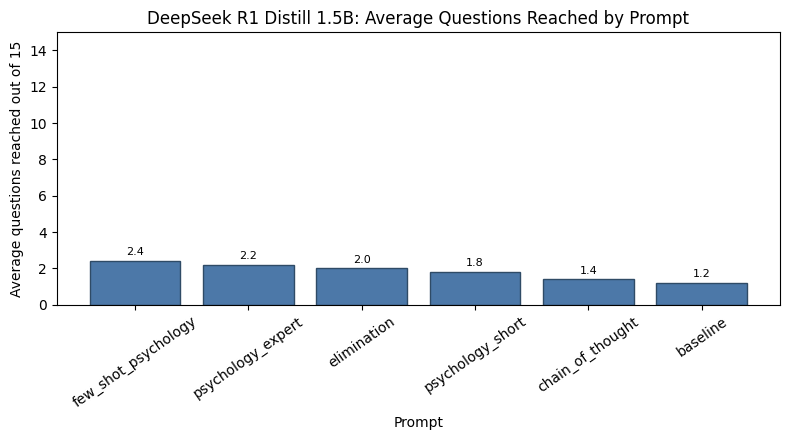

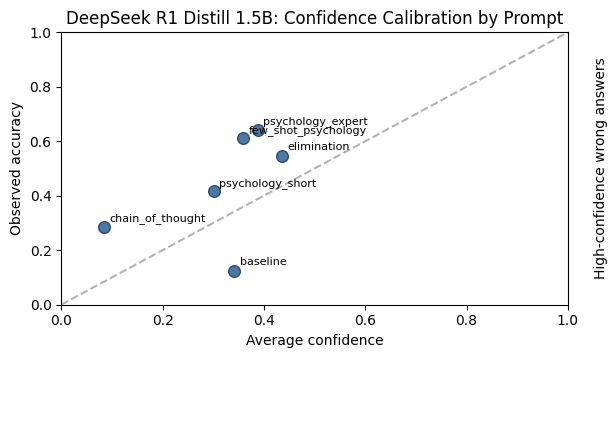

DeepSeek R1 Distill 1.5B: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
3,deepseek_r1_1_5b,deepseek_r1_1_5b_few_shot_psychology,few_shot_psychology,5,2.4,4,1.4,7,0.093333,0.200000,140.0,300,3.330119,5.405875,1.000000,0.093333,thinking
4,deepseek_r1_1_5b,deepseek_r1_1_5b_psychology_expert,psychology_expert,5,2.2,5,1.2,6,0.080000,0.266667,140.0,500,2.227961,3.617269,0.960000,0.080000,thinking
2,deepseek_r1_1_5b,deepseek_r1_1_5b_elimination,elimination,5,2.0,3,1.0,5,0.066667,0.133333,100.0,200,3.376011,3.918231,0.366667,0.066667,thinking
5,deepseek_r1_1_5b,deepseek_r1_1_5b_psychology_short,psychology_short,5,1.8,3,0.8,4,0.053333,0.133333,80.0,200,2.358695,3.927296,1.000000,0.053333,thinking
1,deepseek_r1_1_5b,deepseek_r1_1_5b_chain_of_thought,chain_of_thought,5,1.4,2,0.4,2,0.026667,0.066667,40.0,100,3.646443,3.928315,0.800000,0.026667,thinking
0,deepseek_r1_1_5b,deepseek_r1_1_5b_baseline,baseline,5,1.2,2,0.2,1,0.013333,0.066667,20.0,100,1.847679,2.574734,1.000000,0.013333,thinking


DeepSeek R1 Distill 1.5B: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
1,deepseek_r1_1_5b,baseline,"Logic, knowledge & metaphysics",1,1,0,1.000000,1.000000,1,0.066667
2,deepseek_r1_1_5b,baseline,Other philosophy/psychology,4,0,4,0.000000,1.250000,4,0.000000
0,deepseek_r1_1_5b,baseline,Ethics & political philosophy,1,0,1,0.000000,1.000000,1,0.000000
6,deepseek_r1_1_5b,chain_of_thought,Social psychology,2,2,0,1.000000,1.000000,2,0.066667
5,deepseek_r1_1_5b,chain_of_thought,Other philosophy/psychology,3,0,3,0.000000,1.333333,3,0.000000
3,deepseek_r1_1_5b,chain_of_thought,Cognitive psychology & memory,1,0,1,0.000000,1.000000,1,0.000000
4,deepseek_r1_1_5b,chain_of_thought,"Logic, knowledge & metaphysics",1,0,1,0.000000,2.000000,1,0.000000
7,deepseek_r1_1_5b,elimination,Ethics & political philosophy,1,1,0,1.000000,2.000000,1,0.066667
8,deepseek_r1_1_5b,elimination,Learning & behavior,1,1,0,1.000000,1.000000,1,0.066667
12,deepseek_r1_1_5b,elimination,Social psychology,1,1,0,1.000000,1.000000,1,0.066667


,model_label,prompt_type,error_type,count
0,deepseek_r1_1_5b,baseline,Correct,1
1,deepseek_r1_1_5b,baseline,Plausible but incorrect answer,5
2,deepseek_r1_1_5b,chain_of_thought,Correct,2
3,deepseek_r1_1_5b,chain_of_thought,Invalid or unparseable output,1
4,deepseek_r1_1_5b,chain_of_thought,Plausible but incorrect answer,4
5,deepseek_r1_1_5b,elimination,Correct,5
6,deepseek_r1_1_5b,elimination,Invalid or unparseable output,3
7,deepseek_r1_1_5b,elimination,Plausible but incorrect answer,2
8,deepseek_r1_1_5b,few_shot_psychology,Correct,7
9,deepseek_r1_1_5b,few_shot_psychology,Plausible but incorrect answer,5


DeepSeek R1 Distill 1.5B: confidence coverage


,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate
0,deepseek_r1_1_5b,baseline,6,6,1.0
1,deepseek_r1_1_5b,chain_of_thought,7,7,1.0
2,deepseek_r1_1_5b,elimination,10,10,1.0
3,deepseek_r1_1_5b,few_shot_psychology,12,12,1.0
4,deepseek_r1_1_5b,psychology_expert,11,11,1.0
5,deepseek_r1_1_5b,psychology_short,9,9,1.0


DeepSeek R1 Distill 1.5B: confidence and overconfidence


,model_label,prompt_type,confidence_bucket,questions,observed_accuracy,average_confidence,average_margin,overconfident_errors
0,deepseek_r1_1_5b,baseline,low (<= 0.40),2,0.000000,0.170420,-0.313434,0
1,deepseek_r1_1_5b,baseline,medium (0.40-0.70),4,0.250000,0.512342,0.234439,0
2,deepseek_r1_1_5b,baseline,high (>= 0.70),0,NaN,NaN,NaN,0
3,deepseek_r1_1_5b,chain_of_thought,low (<= 0.40),7,0.285714,0.084892,-0.519949,0
4,deepseek_r1_1_5b,chain_of_thought,medium (0.40-0.70),0,NaN,NaN,NaN,0
5,deepseek_r1_1_5b,chain_of_thought,high (>= 0.70),0,NaN,NaN,NaN,0
6,deepseek_r1_1_5b,elimination,low (<= 0.40),3,0.666667,0.338709,-0.000491,0
7,deepseek_r1_1_5b,elimination,medium (0.40-0.70),7,0.428571,0.533225,0.314289,0
8,deepseek_r1_1_5b,elimination,high (>= 0.70),0,NaN,NaN,NaN,0
9,deepseek_r1_1_5b,few_shot_psychology,low (<= 0.40),3,0.666667,0.136148,-0.406003,0


,model_label,prompt_type,system_name,run_id,level_before_answer,topic,question_text,selected_option_text,raw_response,confidence_score,confidence_margin,option_confidences,correct


In [ ]:
deepseek_analysis = analyse_model_runs(
    df_deepseek_all_prompts,
    model_tag="DeepSeek R1 Distill 1.5B",
    output_prefix="philosophy_psychology_deepseek_r1_1_5b",
    model_type="thinking",
)


### DeepSeek error and confidence conclusion

DeepSeek-R1-Distill-Qwen-1.5B performed weakly in this timed game. Its best prompt was `few_shot_psychology`, with only **2.4 average questions** and **7 / 75 = 0.093 game accuracy**. The reasoning-style outputs were slower than the other small models and did not improve survival.

Most errors were either **plausible but incorrect answers** or invalid/unparseable outputs. Errors appeared across several Psychology and Philosophy areas, especially broad **Other philosophy/psychology** questions, so the weakness was not limited to one topic.

Confidence was available, but it did not make the model practically useful because the overall accuracy was very low. DeepSeek therefore supports the conclusion that thinking-style generation was not suitable for this fast multiple-choice setting.

In [ ]:
nonthinking_summary_parts = [
    summary
    for summary in [
        globals().get("qwen_comparison_summary_sorted"),
        globals().get("phi_fixed_comparison"),
        globals().get("phi_ensemble_summary_sorted"),
    ]
    if isinstance(summary, pd.DataFrame)
]

qwen_phi_summary_for_thinking = pd.concat(nonthinking_summary_parts, ignore_index=True, sort=False)
qwen_phi_summary_for_thinking["model_type"] = "non-thinking"

thinking_vs_nonthinking_summary = pd.concat(
    [
        qwen_phi_summary_for_thinking,
        survival_summary_deepseek_sorted,
    ],
    ignore_index=True,
    sort=False,
)

thinking_vs_nonthinking_summary_sorted = sort_survival_summary(thinking_vs_nonthinking_summary)

thinking_vs_nonthinking_summary_sorted


,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type,model_type
12,phi_3_5_mini_fixed_generation_psychology_short,5,14.2,15,13.8,69,0.920000,1.000000,665600.0,1024000,0.435922,0.809280,1.000000,0.920000,phi_3_5_mini_fixed_generation,psychology_short,non-thinking
13,phi_3_mini_baseline,5,12.6,15,12.0,60,0.800000,1.000000,525000.0,1024000,0.404949,0.893696,1.000000,0.800000,phi_3_mini,baseline,non-thinking
14,phi_3_mini_psychology_expert,5,11.4,15,11.0,55,0.733333,1.000000,615260.0,1024000,0.487452,1.198305,1.000000,0.733333,phi_3_mini,psychology_expert,non-thinking
15,phi_3_mini_elimination,5,10.4,15,9.6,48,0.640000,1.000000,281860.0,1024000,0.416466,0.507190,1.000000,0.640000,phi_3_mini,elimination,non-thinking
0,qwen_3b_few_shot_psychology,5,10.2,15,9.6,48,0.640000,1.000000,422560.0,1024000,0.274265,0.315287,1.000000,0.640000,qwen_3b,few_shot_psychology,non-thinking
1,qwen_3b_baseline,5,10.0,15,9.2,46,0.613333,1.000000,216100.0,1024000,0.188246,0.402841,1.000000,0.613333,qwen_3b,baseline,non-thinking
16,phi_3_mini_psychology_short,5,9.2,15,8.6,43,0.573333,1.000000,410240.0,1024000,0.439084,1.070090,1.000000,0.573333,phi_3_mini,psychology_short,non-thinking
2,qwen_1_5b_few_shot_psychology,5,8.4,12,7.4,37,0.493333,0.733333,17660.0,64000,0.168136,0.238302,1.000000,0.493333,qwen_1_5b,few_shot_psychology,non-thinking
3,qwen_3b_psychology_short,5,8.2,14,7.2,36,0.480000,0.866667,58160.0,256000,0.181930,0.278965,1.000000,0.480000,qwen_3b,psychology_short,non-thinking
4,qwen_1_5b_psychology_short,5,7.8,12,6.8,34,0.453333,0.733333,17040.0,64000,0.144989,0.439383,1.000000,0.453333,qwen_1_5b,psychology_short,non-thinking


In [ ]:
thinking_vs_nonthinking_summary_sorted.to_csv(
    "philosophy_psychology_thinking_vs_nonthinking_summary.csv",
    index=False
)

print("Thinking vs non-thinking comparison saved.")

Thinking vs non-thinking comparison saved.


# Gemma model comparison

Gemma 2 2B Instruct is included as an additional model-family comparison. It is useful because it has a different instruction-tuning style from Qwen, Phi, DeepSeek, and Llama, while still being small enough to run in the notebook environment.

The goal is to test whether another compact instruction model can improve the Philosophy & Psychology game without increasing response time too much.

In [ ]:
import os
import subprocess
import sys

try:
    from huggingface_hub import login
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "huggingface_hub"])
    from huggingface_hub import login

hf_token = os.environ.get("HF_TOKEN")

try:
    from google.colab import userdata
    hf_token = userdata.get("HF_TOKEN") or hf_token
except Exception:
    pass

if not hf_token:
    raise ValueError(
        "HF_TOKEN was not found. Add it in Colab Secrets, then rerun this cell."
    )

login(token=hf_token, add_to_git_credential=False)
print("Hugging Face login complete.")


Hugging Face login complete.


In [ ]:
import gc
import subprocess
import sys
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM


def clear_loaded_model():
    global model, tokenizer, generator

    for variable_name in ["model", "tokenizer", "generator"]:
        if variable_name in globals():
            del globals()[variable_name]

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def choose_model_dtype():
    if torch.cuda.is_available():
        major, _ = torch.cuda.get_device_capability()
        return torch.bfloat16 if major >= 8 else torch.float16

    return torch.float32


def load_chat_model(model_id, model_label=None, use_4bit=False):
    global model, tokenizer, model_name, current_model_label

    clear_loaded_model()

    model_name = model_id
    current_model_label = model_label or model_id.split("/")[-1].replace("-", "_")
    dtype = choose_model_dtype()

    auth_kwargs = {"token": hf_token} if hf_token else {}
    load_kwargs = {
        "device_map": "auto",
        "torch_dtype": dtype,
        **auth_kwargs,
    }


    if "gemma-2" in model_id.lower():
        load_kwargs["attn_implementation"] = "eager"

    if use_4bit:
        try:
            from transformers import BitsAndBytesConfig
        except ImportError:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "bitsandbytes", "accelerate"])
            from transformers import BitsAndBytesConfig

        load_kwargs["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_compute_dtype=dtype,
        )

    tokenizer = AutoTokenizer.from_pretrained(model_id, **auth_kwargs)
    model = AutoModelForCausalLM.from_pretrained(model_id, **load_kwargs)
    model.eval()

    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token

    print("Loaded model:", model_name)
    print("Model label:", current_model_label)
    print("4-bit loading:", use_4bit)
    print("dtype:", dtype)


In [ ]:
def generate_answer_scored_options(question, prompt_type="psychology_short"):
    prompt = build_prompt_from_type(question, prompt_type)
    formatted_prompt = format_model_prompt(prompt)
    base_text = formatted_prompt + "\nThe correct answer is option"
    start_time = time.time()

    option_scores = {}

    for option in question.options:
        candidate_text = f" {option.id}: {option.text}"
        option_scores[int(option.id)] = score_candidate_continuation_generic(
            base_text,
            candidate_text,
        )

    predicted_id = max(option_scores, key=option_scores.get)
    response_time = time.time() - start_time
    confidence_score, confidence_margin = confidence_margin_from_scores(
        option_scores,
        predicted_id,
    )

    return {
        "prompt_type": prompt_type,
        "prompt": prompt,
        "raw_response": json.dumps(option_scores, ensure_ascii=False),
        "predicted_id": predicted_id,
        "response_time": response_time,
        "option_confidences": option_scores,
        "confidence_score": confidence_score,
        "confidence_margin": confidence_margin,
    }


In [ ]:
def play_prompt_game_with_answer_fn(
    comp_id,
    answer_fn,
    prompt_type="psychology_short",
    system_name="system",
    delay_seconds=1.5,
):
    return run_game_with_answer_fn(
        comp_id=comp_id,
        answer_fn=answer_fn,
        prompt_type=prompt_type,
        system_name=system_name,
        delay_seconds=delay_seconds,
    )





In [ ]:


gemma_model_id = "google/gemma-2-2b-it"
gemma_model_label = "gemma_2_2b_it"

try:
    load_chat_model(
        model_id=gemma_model_id,
        model_label=gemma_model_label,
        use_4bit=False,
    )

    model.eval()

    if hasattr(model.config, "use_cache"):
        model.config.use_cache = False

    if hasattr(model, "generation_config"):
        model.generation_config.use_cache = False

    GEMMA_AVAILABLE = True
    print("Gemma loaded successfully without transformers.pipeline.")

except Exception as gemma_error:
    GEMMA_AVAILABLE = False
    RUN_GEMMA = False
    df_gemma_prompts = pd.DataFrame()
    gemma_survival_summary = pd.DataFrame()
    gemma_survival_summary_sorted = pd.DataFrame()

    print("Gemma could not be loaded in this runtime.")
    print("This is usually a Colab package/runtime problem, not a notebook logic problem.")
    print("Error type:", type(gemma_error).__name__)
    print("Error message:", gemma_error)
    print("Recommended fix: restart runtime, make sure the notebook has no `pipeline` import, then rerun from the top.")


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/4.24M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.5M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/838 [00:00<?, ?B/s]

...

model-00002-of-00002.safetensors:   0%|          | 0.00/241M [00:00<?, ?B/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/4.99G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/187 [00:00<?, ?B/s]

Loaded model: google/gemma-2-2b-it
Model label: gemma_2_2b_it
4-bit loading: False
dtype: torch.float16
Gemma loaded successfully without transformers.pipeline.


In [ ]:
if globals().get("GEMMA_AVAILABLE", False):
    gemma_prompt_results = []

    for prompt_type in PROMPT_TYPES:
        df_gemma_prompt = benchmark_answer_fn(
            answer_fn=generate_answer_chat_template_with_confidence,
            model_label=gemma_model_label,
            prompt_type=prompt_type,
            n_runs=5,
            delay_seconds=1.5,
        )
        gemma_prompt_results.append(df_gemma_prompt)

    df_gemma_prompts = pd.concat(gemma_prompt_results, ignore_index=True)

    gemma_survival_summary = make_survival_summary(df_gemma_prompts)
    gemma_survival_summary_sorted = gemma_survival_summary.sort_values(
        by=["average_questions_reached", "best_questions_reached", "average_final_earned_amount"],
        ascending=False,
    )
else:
    df_gemma_prompts = pd.DataFrame()
    gemma_survival_summary = pd.DataFrame()
    gemma_survival_summary_sorted = pd.DataFrame()

gemma_survival_summary_sorted



Running model=gemma_2_2b_it, prompt=baseline, run 1/5
Started game session: 240625
System: gemma_2_2b_it_baseline


The following generation flags are not valid and may be ignored: ['cache_implementation']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1
Question: Which of the following best describes a social norm?
Raw response: 1
Submitted: 1
Correct: True
Response time: 0.67 seconds


The following generation flags are not valid and may be ignored: ['cache_implementation']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 2
Question: What term describes the principle of treating others the way you would want to be treated?
Raw response: 2
Submitted: 2
Correct: True
Response time: 0.35 seconds


...

The following generation flags are not valid and may be ignored: ['cache_implementation']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 14
Question: How did the Milgram experiment demonstrate the concept of 'agentic state' in participants?
Raw response: Reasoning: The agentic state is about feeling like an agent of another person or authority. The Milgram experiment showed participants were led to believe they were carrying out orders from an authority figure, making them feel like they were acting on the authority's behalf.

Final answer: 3
Submitted: 3
Correct: True
Response time: 4.7 seconds


The following generation flags are not valid and may be ignored: ['cache_implementation']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 15
Question: What does mathematical empiricism suggest about the nature of mathematical knowledge?
Raw response: Reasoning:  Empiricism emphasizes observation and experience. Option 3 aligns with this, as it states mathematical knowledge is derived from empirical research.

Final answer: 3
Submitted: 3
Correct: True
Response time: 3.0 seconds
Game ended.


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,gemma_2_2b_it,gemma_2_2b_it_baseline,baseline,5,8.2,12,7.2,36,0.480000,0.733333,16460.0,64000,0.357408,0.670946,1.0,0.480000,non-thinking
5,gemma_2_2b_it,gemma_2_2b_it_psychology_short,psychology_short,5,7.6,13,6.6,33,0.440000,0.800000,32600.0,128000,0.363590,0.508573,1.0,0.440000,non-thinking
4,gemma_2_2b_it,gemma_2_2b_it_psychology_expert,psychology_expert,5,7.4,15,6.6,33,0.440000,1.000000,256100.0,1024000,0.354536,0.482786,1.0,0.440000,non-thinking
1,gemma_2_2b_it,gemma_2_2b_it_chain_of_thought,chain_of_thought,5,7.2,15,6.4,32,0.426667,1.000000,205920.0,1024000,2.949706,6.198447,1.0,0.426667,non-thinking
2,gemma_2_2b_it,gemma_2_2b_it_elimination,elimination,5,7.0,14,6.0,30,0.400000,0.866667,51920.0,256000,0.362256,0.489347,1.0,0.400000,non-thinking
3,gemma_2_2b_it,gemma_2_2b_it_few_shot_psychology,few_shot_psychology,5,6.6,10,5.6,28,0.373333,0.600000,8040.0,16000,0.498649,0.581598,1.0,0.373333,non-thinking


In [ ]:
if globals().get("GEMMA_AVAILABLE", False) and not gemma_survival_summary_sorted.empty:
    gemma_survival_summary_sorted.to_csv(
        "philosophy_psychology_gemma_prompt_summary.csv",
        index=False,
    )
    df_gemma_prompts.to_csv(
        "philosophy_psychology_gemma_question_level_results.csv",
        index=False,
    )
else:
    print("No Gemma result files were saved because Gemma was skipped.")

available_gemma_parts = []

if "thinking_vs_nonthinking_summary_sorted" in globals() and isinstance(thinking_vs_nonthinking_summary_sorted, pd.DataFrame):
    available_gemma_parts.append(thinking_vs_nonthinking_summary_sorted)

if globals().get("GEMMA_AVAILABLE", False) and not gemma_survival_summary_sorted.empty:
    available_gemma_parts.append(gemma_survival_summary_sorted)

final_with_gemma = pd.concat(
    available_gemma_parts,
    ignore_index=True,
    sort=False,
) if available_gemma_parts else pd.DataFrame()

if not final_with_gemma.empty:
    final_with_gemma = final_with_gemma.sort_values(
        by=["average_questions_reached", "best_questions_reached", "average_final_earned_amount"],
        ascending=False,
    )

final_with_gemma.to_csv(
    "philosophy_psychology_final_summary_with_optional_gemma.csv",
    index=False,
)

final_with_gemma


,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type,model_type
0,phi_3_5_mini_fixed_generation_psychology_short,5,14.2,15,13.8,69,0.920000,1.000000,665600.0,1024000,0.435922,0.809280,1.000000,0.920000,phi_3_5_mini_fixed_generation,psychology_short,non-thinking
1,phi_3_mini_baseline,5,12.6,15,12.0,60,0.800000,1.000000,525000.0,1024000,0.404949,0.893696,1.000000,0.800000,phi_3_mini,baseline,non-thinking
2,phi_3_mini_psychology_expert,5,11.4,15,11.0,55,0.733333,1.000000,615260.0,1024000,0.487452,1.198305,1.000000,0.733333,phi_3_mini,psychology_expert,non-thinking
3,phi_3_mini_elimination,5,10.4,15,9.6,48,0.640000,1.000000,281860.0,1024000,0.416466,0.507190,1.000000,0.640000,phi_3_mini,elimination,non-thinking
4,qwen_3b_few_shot_psychology,5,10.2,15,9.6,48,0.640000,1.000000,422560.0,1024000,0.274265,0.315287,1.000000,0.640000,qwen_3b,few_shot_psychology,non-thinking
5,qwen_3b_baseline,5,10.0,15,9.2,46,0.613333,1.000000,216100.0,1024000,0.188246,0.402841,1.000000,0.613333,qwen_3b,baseline,non-thinking
6,phi_3_mini_psychology_short,5,9.2,15,8.6,43,0.573333,1.000000,410240.0,1024000,0.439084,1.070090,1.000000,0.573333,phi_3_mini,psychology_short,non-thinking
7,qwen_1_5b_few_shot_psychology,5,8.4,12,7.4,37,0.493333,0.733333,17660.0,64000,0.168136,0.238302,1.000000,0.493333,qwen_1_5b,few_shot_psychology,non-thinking
8,qwen_3b_psychology_short,5,8.2,14,7.2,36,0.480000,0.866667,58160.0,256000,0.181930,0.278965,1.000000,0.480000,qwen_3b,psychology_short,non-thinking
26,gemma_2_2b_it_baseline,5,8.2,12,7.2,36,0.480000,0.733333,16460.0,64000,0.357408,0.670946,1.000000,0.480000,gemma_2_2b_it,baseline,non-thinking


## Gemma prompt, topic, error, and confidence analysis

This cell analyses Gemma immediately after its prompt benchmark and before moving to Llama.


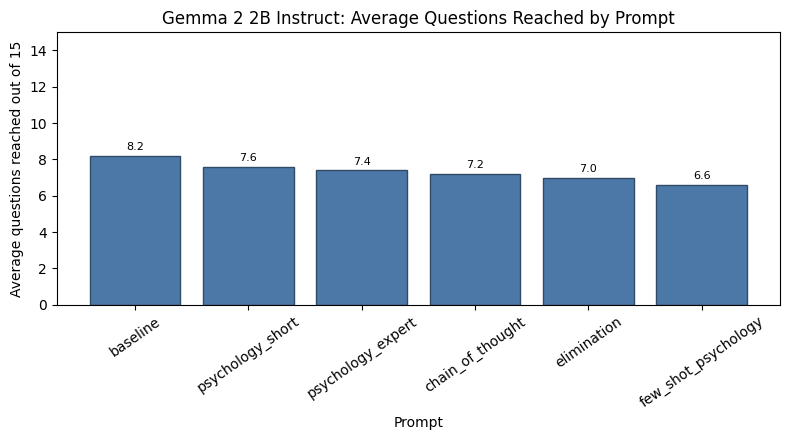

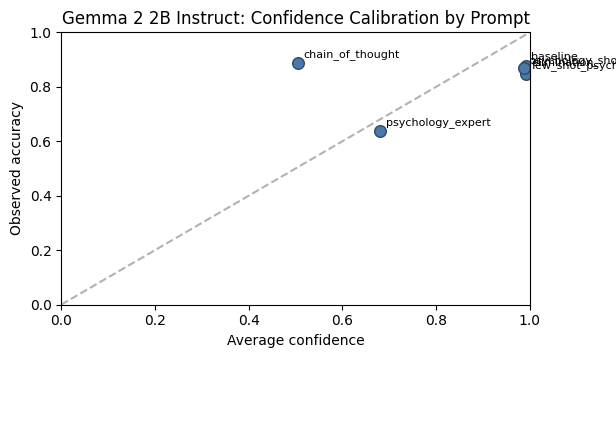

Gemma 2 2B Instruct: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,gemma_2_2b_it,gemma_2_2b_it_baseline,baseline,5,8.2,12,7.2,36,0.480000,0.733333,16460.0,64000,0.357408,0.670946,1.0,0.480000,non-thinking
5,gemma_2_2b_it,gemma_2_2b_it_psychology_short,psychology_short,5,7.6,13,6.6,33,0.440000,0.800000,32600.0,128000,0.363590,0.508573,1.0,0.440000,non-thinking
4,gemma_2_2b_it,gemma_2_2b_it_psychology_expert,psychology_expert,5,7.4,15,6.6,33,0.440000,1.000000,256100.0,1024000,0.354536,0.482786,1.0,0.440000,non-thinking
1,gemma_2_2b_it,gemma_2_2b_it_chain_of_thought,chain_of_thought,5,7.2,15,6.4,32,0.426667,1.000000,205920.0,1024000,2.949706,6.198447,1.0,0.426667,non-thinking
2,gemma_2_2b_it,gemma_2_2b_it_elimination,elimination,5,7.0,14,6.0,30,0.400000,0.866667,51920.0,256000,0.362256,0.489347,1.0,0.400000,non-thinking
3,gemma_2_2b_it,gemma_2_2b_it_few_shot_psychology,few_shot_psychology,5,6.6,10,5.6,28,0.373333,0.600000,8040.0,16000,0.498649,0.581598,1.0,0.373333,non-thinking


Gemma 2 2B Instruct: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
6,gemma_2_2b_it,baseline,Philosophers & history of ideas,4,4,0,1.000000,6.250000,3,0.088889
1,gemma_2_2b_it,baseline,Developmental psychology,1,1,0,1.000000,5.000000,1,0.066667
4,gemma_2_2b_it,baseline,Neuroscience & perception,1,1,0,1.000000,8.000000,1,0.066667
5,gemma_2_2b_it,baseline,Other philosophy/psychology,19,18,1,0.947368,4.894737,5,0.240000
7,gemma_2_2b_it,baseline,Social psychology,6,5,1,0.833333,4.000000,3,0.111111
3,gemma_2_2b_it,baseline,"Logic, knowledge & metaphysics",4,3,1,0.750000,4.500000,3,0.066667
0,gemma_2_2b_it,baseline,Cognitive psychology & memory,3,2,1,0.666667,5.000000,3,0.044444
2,gemma_2_2b_it,baseline,Ethics & political philosophy,3,2,1,0.666667,6.000000,2,0.066667
8,gemma_2_2b_it,chain_of_thought,Cognitive psychology & memory,4,4,0,1.000000,5.750000,4,0.066667
12,gemma_2_2b_it,chain_of_thought,Philosophers & history of ideas,1,1,0,1.000000,6.000000,1,0.066667


,model_label,prompt_type,error_type,count
0,gemma_2_2b_it,baseline,Correct,36
1,gemma_2_2b_it,baseline,High-confidence wrong answer,5
2,gemma_2_2b_it,chain_of_thought,Correct,32
3,gemma_2_2b_it,chain_of_thought,High-confidence wrong answer,1
4,gemma_2_2b_it,chain_of_thought,Plausible but incorrect answer,3
5,gemma_2_2b_it,elimination,Correct,30
6,gemma_2_2b_it,elimination,High-confidence wrong answer,5
7,gemma_2_2b_it,few_shot_psychology,Correct,28
8,gemma_2_2b_it,few_shot_psychology,High-confidence wrong answer,5
9,gemma_2_2b_it,psychology_expert,Correct,33


Gemma 2 2B Instruct: confidence coverage


,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate
0,gemma_2_2b_it,baseline,41,41,1.0
1,gemma_2_2b_it,chain_of_thought,36,36,1.0
2,gemma_2_2b_it,elimination,35,35,1.0
3,gemma_2_2b_it,few_shot_psychology,33,33,1.0
4,gemma_2_2b_it,psychology_expert,37,37,1.0
5,gemma_2_2b_it,psychology_short,38,38,1.0


Gemma 2 2B Instruct: confidence and overconfidence


,model_label,prompt_type,confidence_bucket,questions,observed_accuracy,average_confidence,average_margin,overconfident_errors
0,gemma_2_2b_it,baseline,low (<= 0.40),0,NaN,NaN,NaN,0
1,gemma_2_2b_it,baseline,medium (0.40-0.70),0,NaN,NaN,NaN,0
2,gemma_2_2b_it,baseline,high (>= 0.70),41,0.878049,0.991055,0.985272,5
3,gemma_2_2b_it,chain_of_thought,low (<= 0.40),27,0.888889,0.070540,-0.794334,0
4,gemma_2_2b_it,chain_of_thought,medium (0.40-0.70),0,NaN,NaN,NaN,0
5,gemma_2_2b_it,chain_of_thought,high (>= 0.70),9,0.888889,0.940643,0.902962,1
6,gemma_2_2b_it,elimination,low (<= 0.40),0,NaN,NaN,NaN,0
7,gemma_2_2b_it,elimination,medium (0.40-0.70),0,NaN,NaN,NaN,0
8,gemma_2_2b_it,elimination,high (>= 0.70),35,0.857143,0.991578,0.985399,5
9,gemma_2_2b_it,few_shot_psychology,low (<= 0.40),0,NaN,NaN,NaN,0


,model_label,prompt_type,system_name,run_id,level_before_answer,topic,question_text,selected_option_text,raw_response,confidence_score,confidence_margin,option_confidences,correct
173,gemma_2_2b_it,few_shot_psychology,gemma_2_2b_it_few_shot_psychology,3,3,"Logic, knowledge & metaphysics","In modal logic, what does the symbol ◻ (Box) t...",Possibility,2,0.999937,0.999896,"{""0"": 6.139278411865234e-06, ""1"": 1.6033649444...",False
46,gemma_2_2b_it,psychology_short,gemma_2_2b_it_psychology_short,1,6,Ethics & political philosophy,Which of the following statements accurately d...,Free software is a subset of open-source software,2,0.999845,0.999717,"{""0"": 1.2218952178955078e-05, ""1"": 0.000127315...",False
183,gemma_2_2b_it,few_shot_psychology,gemma_2_2b_it_few_shot_psychology,5,9,Other philosophy/psychology,How does veganism differ from vegetarianism in...,Vegetarianism excludes all animal products,2,0.999829,0.999697,"{""0"": 2.9087066650390625e-05, ""1"": 0.000131368...",False
174,gemma_2_2b_it,few_shot_psychology,gemma_2_2b_it_few_shot_psychology,4,1,Ethics & political philosophy,What term describes a formal system in which e...,Transitive system,1,0.999338,0.998880,"{""0"": 0.0004582405090332031, ""1"": 0.9995117187...",False
150,gemma_2_2b_it,elimination,gemma_2_2b_it_elimination,5,4,Other philosophy/psychology,Which of the following best describes the conc...,The theory that economic structures determine ...,3,0.999297,0.998778,"{""0"": 2.4080276489257812e-05, ""1"": 0.000159621...",False
6,gemma_2_2b_it,baseline,gemma_2_2b_it_baseline,1,7,Other philosophy/psychology,What role does the concept of 'looming' play i...,It refers to a stimulus that is slowly approac...,1,0.999204,0.998771,"{""0"": 0.0004336833953857422, ""1"": 0.9990234375...",False
28,gemma_2_2b_it,baseline,gemma_2_2b_it_baseline,4,9,Social psychology,"According to Bernard Weiner, which dimension w...",Controllability-uncontrollability dimension,3,0.999095,0.998647,"{""0"": 7.480382919311523e-05, ""1"": 0.0004475116...",False
142,gemma_2_2b_it,elimination,gemma_2_2b_it_elimination,3,14,Ethics & political philosophy,What term is used to describe the public promo...,Hypocrisy signalling,3,0.999061,0.998627,"{""0"": 0.0001430511474609375, ""1"": 0.0003623962...",False
100,gemma_2_2b_it,psychology_expert,gemma_2_2b_it_psychology_expert,4,3,Other philosophy/psychology,What is the term used to describe the high pro...,Resistance,1,0.995549,0.991605,"{""0"": 0.0003638267517089844, ""1"": 0.9956054687...",False
97,gemma_2_2b_it,psychology_expert,gemma_2_2b_it_psychology_expert,3,4,Other philosophy/psychology,Which of the following best describes Huntingt...,Conflicts will decrease due to globalization.,2,0.994115,0.989789,"{""0"": 9.936094284057617e-05, ""1"": 0.0043258666...",False


In [ ]:
if globals().get("GEMMA_AVAILABLE", False) and not df_gemma_prompts.empty:
    gemma_analysis = analyse_model_runs(
        df_gemma_prompts,
        model_tag="Gemma 2 2B Instruct",
        output_prefix="philosophy_psychology_gemma_2_2b_it",
        model_type="non-thinking",
    )
else:
    gemma_analysis = {}
    print("Gemma analysis skipped because Gemma did not run.")


### Gemma comparison, error, and confidence interpretation

Gemma produced a useful middle-range result but did not beat Phi or the best Qwen 3B configuration. The best Gemma setup was `baseline`, reaching **8.2 average questions**, a best run of **12**, and **36 / 75 = 0.480 game accuracy**. `psychology_short` and `psychology_expert` were close behind.

Gemma followed the answer format well, with a valid-output rate of **1.0** for all prompts. It performed well on **Other philosophy/psychology**, **cognitive psychology**, **ethics**, and **logic** questions, but made more errors in broader **Other philosophy/psychology**, **Ethics & political philosophy**, and **Logic, knowledge & metaphysics** topics.

The main weakness is confidence. Gemma had many **high-confidence wrong answers**, so its confidence scores are not always reliable. It can give a clean numeric answer and still be very certain about a wrong option.

# Llama model comparison

The group now has access to `meta-llama/Meta-Llama-3-8B`, so we add Llama as a third major model family alongside Qwen and Gemma.

Because the accepted repository is the **base** Llama 3 8B checkpoint, the fairer first test is forced-choice scoring rather than free-form generation. The base model is not instruction-tuned, so asking it to emit only `0`, `1`, `2`, or `3` can be unreliable. Forced-choice scoring asks: "which answer option is most likely under the model?"



In [ ]:
llama_model_id = "meta-llama/Meta-Llama-3-8B"
llama_model_label = "llama_3_8b_forced_choice"


load_chat_model(
    model_id=llama_model_id,
    model_label=llama_model_label,
    use_4bit=True,
)


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/73.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/654 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

...

model-00002-of-00004.safetensors:   0%|          | 0.00/5.00G [00:00<?, ?B/s]

model-00004-of-00004.safetensors:   0%|          | 0.00/1.17G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/177 [00:00<?, ?B/s]

Loaded model: meta-llama/Meta-Llama-3-8B
Model label: llama_3_8b_forced_choice
4-bit loading: True
dtype: torch.float16


In [ ]:
llama_prompt_results = []

for prompt_type in LLAMA_PROMPT_TYPES:
    df_llama_prompt = benchmark_answer_fn(
        answer_fn=generate_answer_scored_options,
        model_label=llama_model_label,
        prompt_type=prompt_type,
        n_runs=5,
        delay_seconds=1.5,
    )
    llama_prompt_results.append(df_llama_prompt)

df_llama_prompts = pd.concat(llama_prompt_results, ignore_index=True)

llama_survival_summary = make_survival_summary(df_llama_prompts)
llama_survival_summary_sorted = llama_survival_summary.sort_values(
    by=["average_questions_reached", "best_questions_reached", "average_final_earned_amount"],
    ascending=False,
)

llama_survival_summary_sorted



Running model=llama_3_8b_forced_choice, prompt=psychology_short, run 1/5
Started game session: 241199
System: llama_3_8b_forced_choice_psychology_short

Level 1
Question: Which of the following best describes the primary difference between traditional anarchism and anarcho-capitalism?
Raw response: {"0": -0.519442081451416, "1": -0.4657195210456848, "2": -0.31266626715660095, "3": -0.4159989356994629}
Submitted: 2
Correct: True
Response time: 1.58 seconds

Level 2
Question: Which neurological condition is associated with déjà vu?
Raw response: {"0": -1.183733344078064, "1": -0.36196058988571167, "2": -2.719957113265991, "3": -1.244339942932129}
Submitted: 1
Correct: True
Response time: 0.95 seconds

Level 3
Question: Which of the following best describes John Locke's view on animals' cognitive faculties?
Raw response: {"0": -0.36231565475463867, "1": -0.39482560753822327, "2": -0.5827372670173645, "3": -0.5369970202445984}
Submitted: 0
Correct: True
Response time: 0.93 seconds

Level 

,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
4,llama_3_8b_forced_choice,llama_3_8b_forced_choice_psychology_short,psychology_short,5,10.0,15,9.2,46,0.613333,1.000000,231240.0,1024000,1.108579,2.883907,1.0,0.613333,non-thinking
2,llama_3_8b_forced_choice,llama_3_8b_forced_choice_few_shot_psychology,few_shot_psychology,5,8.6,15,8.0,40,0.533333,1.000000,416000.0,1024000,1.573792,1.915610,1.0,0.533333,non-thinking
1,llama_3_8b_forced_choice,llama_3_8b_forced_choice_elimination,elimination,5,4.6,15,3.8,19,0.253333,1.000000,204900.0,1024000,1.028347,3.350105,1.0,0.253333,non-thinking
0,llama_3_8b_forced_choice,llama_3_8b_forced_choice_chain_of_thought,chain_of_thought,5,3.6,7,2.6,13,0.173333,0.400000,540.0,2000,1.225909,2.236228,1.0,0.173333,non-thinking
3,llama_3_8b_forced_choice,llama_3_8b_forced_choice_psychology_expert,psychology_expert,5,2.8,6,1.8,9,0.120000,0.333333,280.0,1000,1.069467,2.716981,1.0,0.120000,non-thinking


In [ ]:
llama_survival_summary_sorted.to_csv(
    "philosophy_psychology_llama_prompt_summary.csv",
    index=False,
)
df_llama_prompts.to_csv(
    "philosophy_psychology_llama_question_level_results.csv",
    index=False,
)

available_family_summaries = []

for summary_name in [
    "qwen_comparison_summary_sorted",
    "gemma_survival_summary_sorted",
    "llama_survival_summary_sorted",
]:
    if summary_name in globals():
        summary = globals()[summary_name].copy()
        summary["summary_source"] = summary_name
        available_family_summaries.append(summary)

model_family_comparison = pd.concat(
    available_family_summaries,
    ignore_index=True,
    sort=False,
).sort_values(
    by=["average_questions_reached", "best_questions_reached", "average_final_earned_amount"],
    ascending=False,
)

model_family_comparison.to_csv(
    "philosophy_psychology_model_family_comparison.csv",
    index=False,
)

model_family_comparison


,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type,model_type,summary_source
0,qwen_3b_few_shot_psychology,5,10.2,15,9.6,48,0.640000,1.000000,422560.0,1024000,0.274265,0.315287,1.00,0.640000,qwen_3b,few_shot_psychology,non-thinking,qwen_comparison_summary_sorted
18,llama_3_8b_forced_choice_psychology_short,5,10.0,15,9.2,46,0.613333,1.000000,231240.0,1024000,1.108579,2.883907,1.00,0.613333,llama_3_8b_forced_choice,psychology_short,non-thinking,llama_survival_summary_sorted
1,qwen_3b_baseline,5,10.0,15,9.2,46,0.613333,1.000000,216100.0,1024000,0.188246,0.402841,1.00,0.613333,qwen_3b,baseline,non-thinking,qwen_comparison_summary_sorted
19,llama_3_8b_forced_choice_few_shot_psychology,5,8.6,15,8.0,40,0.533333,1.000000,416000.0,1024000,1.573792,1.915610,1.00,0.533333,llama_3_8b_forced_choice,few_shot_psychology,non-thinking,llama_survival_summary_sorted
2,qwen_1_5b_few_shot_psychology,5,8.4,12,7.4,37,0.493333,0.733333,17660.0,64000,0.168136,0.238302,1.00,0.493333,qwen_1_5b,few_shot_psychology,NaN,qwen_comparison_summary_sorted
3,qwen_3b_psychology_short,5,8.2,14,7.2,36,0.480000,0.866667,58160.0,256000,0.181930,0.278965,1.00,0.480000,qwen_3b,psychology_short,non-thinking,qwen_comparison_summary_sorted
12,gemma_2_2b_it_baseline,5,8.2,12,7.2,36,0.480000,0.733333,16460.0,64000,0.357408,0.670946,1.00,0.480000,gemma_2_2b_it,baseline,non-thinking,gemma_survival_summary_sorted
4,qwen_1_5b_psychology_short,5,7.8,12,6.8,34,0.453333,0.733333,17040.0,64000,0.144989,0.439383,1.00,0.453333,qwen_1_5b,psychology_short,NaN,qwen_comparison_summary_sorted
13,gemma_2_2b_it_psychology_short,5,7.6,13,6.6,33,0.440000,0.800000,32600.0,128000,0.363590,0.508573,1.00,0.440000,gemma_2_2b_it,psychology_short,non-thinking,gemma_survival_summary_sorted
14,gemma_2_2b_it_psychology_expert,5,7.4,15,6.6,33,0.440000,1.000000,256100.0,1024000,0.354536,0.482786,1.00,0.440000,gemma_2_2b_it,psychology_expert,non-thinking,gemma_survival_summary_sorted


## Llama prompt, topic, error, and confidence analysis

This cell analyses Llama immediately after its forced-choice prompt benchmark.


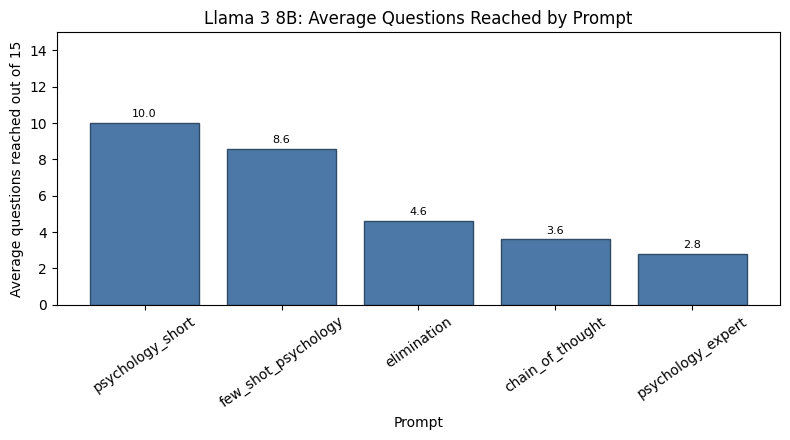

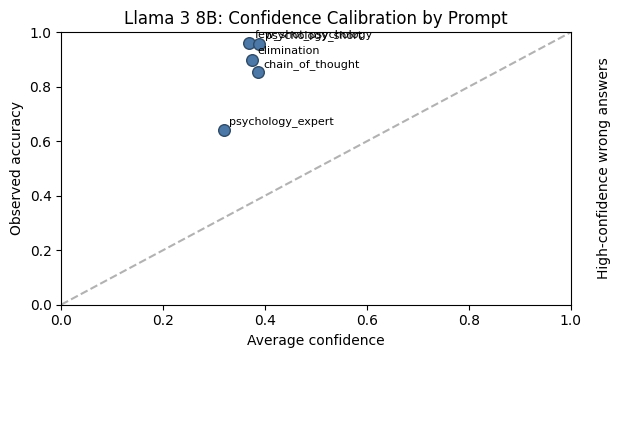

Llama 3 8B: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
4,llama_3_8b_forced_choice,llama_3_8b_forced_choice_psychology_short,psychology_short,5,10.0,15,9.2,46,0.613333,1.000000,231240.0,1024000,1.108579,2.883907,1.0,0.613333,non-thinking
2,llama_3_8b_forced_choice,llama_3_8b_forced_choice_few_shot_psychology,few_shot_psychology,5,8.6,15,8.0,40,0.533333,1.000000,416000.0,1024000,1.573792,1.915610,1.0,0.533333,non-thinking
1,llama_3_8b_forced_choice,llama_3_8b_forced_choice_elimination,elimination,5,4.6,15,3.8,19,0.253333,1.000000,204900.0,1024000,1.028347,3.350105,1.0,0.253333,non-thinking
0,llama_3_8b_forced_choice,llama_3_8b_forced_choice_chain_of_thought,chain_of_thought,5,3.6,7,2.6,13,0.173333,0.400000,540.0,2000,1.225909,2.236228,1.0,0.173333,non-thinking
3,llama_3_8b_forced_choice,llama_3_8b_forced_choice_psychology_expert,psychology_expert,5,2.8,6,1.8,9,0.120000,0.333333,280.0,1000,1.069467,2.716981,1.0,0.120000,non-thinking


Llama 3 8B: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
2,llama_3_8b_forced_choice,chain_of_thought,"Logic, knowledge & metaphysics",2,2,0,1.000000,3.500000,1,0.133333
0,llama_3_8b_forced_choice,chain_of_thought,Cognitive psychology & memory,1,1,0,1.000000,2.000000,1,0.066667
1,llama_3_8b_forced_choice,chain_of_thought,Ethics & political philosophy,1,1,0,1.000000,1.000000,1,0.066667
4,llama_3_8b_forced_choice,chain_of_thought,Philosophers & history of ideas,1,1,0,1.000000,6.000000,1,0.066667
3,llama_3_8b_forced_choice,chain_of_thought,Other philosophy/psychology,12,8,4,0.666667,2.583333,5,0.106667
5,llama_3_8b_forced_choice,chain_of_thought,Social psychology,1,0,1,0.000000,3.000000,1,0.000000
7,llama_3_8b_forced_choice,elimination,Ethics & political philosophy,5,5,0,1.000000,7.200000,2,0.166667
6,llama_3_8b_forced_choice,elimination,Developmental psychology,2,2,0,1.000000,11.000000,1,0.133333
9,llama_3_8b_forced_choice,elimination,"Logic, knowledge & metaphysics",2,2,0,1.000000,5.500000,1,0.133333
8,llama_3_8b_forced_choice,elimination,Learning & behavior,1,1,0,1.000000,9.000000,1,0.066667


,model_label,prompt_type,error_type,count
0,llama_3_8b_forced_choice,chain_of_thought,Correct,13
1,llama_3_8b_forced_choice,chain_of_thought,Plausible but incorrect answer,5
2,llama_3_8b_forced_choice,elimination,Correct,19
3,llama_3_8b_forced_choice,elimination,Plausible but incorrect answer,4
4,llama_3_8b_forced_choice,few_shot_psychology,Correct,40
5,llama_3_8b_forced_choice,few_shot_psychology,Plausible but incorrect answer,3
6,llama_3_8b_forced_choice,psychology_expert,Correct,9
7,llama_3_8b_forced_choice,psychology_expert,Plausible but incorrect answer,5
8,llama_3_8b_forced_choice,psychology_short,Correct,46
9,llama_3_8b_forced_choice,psychology_short,Plausible but incorrect answer,4


Llama 3 8B: confidence coverage


,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate
0,llama_3_8b_forced_choice,chain_of_thought,18,18,1.0
1,llama_3_8b_forced_choice,elimination,23,23,1.0
2,llama_3_8b_forced_choice,few_shot_psychology,43,43,1.0
3,llama_3_8b_forced_choice,psychology_expert,14,14,1.0
4,llama_3_8b_forced_choice,psychology_short,50,50,1.0


Llama 3 8B: confidence and overconfidence


,model_label,prompt_type,confidence_bucket,questions,observed_accuracy,average_confidence,average_margin,overconfident_errors
0,llama_3_8b_forced_choice,chain_of_thought,low (<= 0.40),17,0.705882,0.329246,0.068009,0
1,llama_3_8b_forced_choice,chain_of_thought,medium (0.40-0.70),1,1.000000,0.441992,0.156773,0
2,llama_3_8b_forced_choice,chain_of_thought,high (>= 0.70),0,NaN,NaN,NaN,0
3,llama_3_8b_forced_choice,elimination,low (<= 0.40),20,0.800000,0.310482,0.040307,0
4,llama_3_8b_forced_choice,elimination,medium (0.40-0.70),3,1.000000,0.439352,0.184124,0
5,llama_3_8b_forced_choice,elimination,high (>= 0.70),0,NaN,NaN,NaN,0
6,llama_3_8b_forced_choice,few_shot_psychology,low (<= 0.40),38,0.921053,0.326076,0.066571,0
7,llama_3_8b_forced_choice,few_shot_psychology,medium (0.40-0.70),5,1.000000,0.411998,0.148775,0
8,llama_3_8b_forced_choice,few_shot_psychology,high (>= 0.70),0,NaN,NaN,NaN,0
9,llama_3_8b_forced_choice,psychology_expert,low (<= 0.40),14,0.642857,0.318643,0.042233,0


,model_label,prompt_type,system_name,run_id,level_before_answer,topic,question_text,selected_option_text,raw_response,confidence_score,confidence_margin,option_confidences,correct


In [ ]:
llama_analysis = analyse_model_runs(
    df_llama_prompts,
    model_tag="Llama 3 8B",
    output_prefix="philosophy_psychology_llama_3_8b",
    model_type="non-thinking",
)


### Llama comparison, error, and confidence interpretation

Llama 3 8B forced-choice performed well, but still did not beat the best Phi system. Its best setup was `psychology_short`, reaching **10.0 average questions**, a best run of **15**, and **46 / 75 = 0.613 game accuracy**. `few_shot_psychology` was also competitive with **8.6 average questions**.

All Llama prompts had a valid-output rate of **1.0**. The errors were all **plausible but incorrect answers**, with no invalid outputs and no high-confidence wrong answers. This suggests that Llama's main limitation was choosing between close options, not following the format.

The confidence pattern is more conservative than Qwen or Gemma. Most answers were low or medium confidence, and there were **no overconfident errors**. Therefore, Llama was not the strongest model, but its confidence behaviour was relatively safe.

## Phi forced-choice ensemble after model-family comparison

After Qwen, Phi, DeepSeek, Gemma, and Llama have been compared, the strongest single-model story can be checked. If Phi remains the best observed model, this ensemble tests whether combining Phi's prompt styles improves the game result.


In [ ]:
from collections import Counter


def generate_answer_phi_ensemble(question, prompt_type="phi_ensemble_5prompts", prompt_types=None):
    if prompt_types is None:
        prompt_types = ["psychology_short", "psychology_expert", "elimination", "few_shot_psychology", "chain_of_thought"]

    predictions = []
    total_response_time = 0.0
    combined_option_scores = {}

    for single_prompt_type in prompt_types:
        prediction = generate_answer_phi_scored(question, prompt_type=single_prompt_type)
        predictions.append(prediction)
        total_response_time += prediction["response_time"]

        try:
            option_scores = json.loads(prediction["raw_response"])
        except Exception:
            option_scores = {}

        for option_id, values in option_scores.items():
            option_id = int(option_id)
            score = values["score"] if isinstance(values, dict) else float(values)
            combined_option_scores[option_id] = combined_option_scores.get(option_id, 0.0) + float(score)

    if combined_option_scores:
        final_prediction = max(combined_option_scores, key=combined_option_scores.get)
    else:
        valid_predictions = [
            prediction["predicted_id"]
            for prediction in predictions
            if prediction["predicted_id"] is not None
        ]
        final_prediction = Counter(valid_predictions).most_common(1)[0][0] if valid_predictions else None

    confidence_score, confidence_margin = confidence_margin_from_scores(
        combined_option_scores,
        final_prediction,
    )

    raw_response = json.dumps(
        {
            "prompt_predictions": [
                {
                    "prompt_type": prediction["prompt_type"],
                    "predicted_id": prediction["predicted_id"],
                    "raw_response": prediction["raw_response"],
                }
                for prediction in predictions
            ],
            "combined_option_scores": combined_option_scores,
        },
        ensure_ascii=False,
    )

    return {
        "prompt_type": prompt_type,
        "prompt": "Phi forced-choice ensemble over psychology_short, psychology_expert, elimination, few_shot_psychology, and chain_of_thought prompts",
        "raw_response": raw_response,
        "predicted_id": final_prediction,
        "response_time": total_response_time,
        "individual_predictions": predictions,
        "option_confidences": combined_option_scores,
        "confidence_score": confidence_score,
        "confidence_margin": confidence_margin,
    }


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded fixed Phi model: microsoft/Phi-3.5-mini-instruct

Running model=phi_3_5_mini_prompt_ensemble, prompt=phi_ensemble_5prompts, run 1/5
Started game session: 241347
System: phi_3_5_mini_prompt_ensemble_phi_ensemble_5prompts

Level 1
Question: Which of the following best describes the concept of interpersonal relations?
Raw response: {"prompt_predictions": [{"prompt_type": "psychology_short", "predicted_id": 0, "raw_response": "{\"0\": {\"score\": -0.6533034443855286, \"tokens\": 13, \"text\": \"The social association or connection between two or more people\"}, \"1\": {\"score\": -1.3717927932739258, \"tokens\": 9, \"text\": \"A type of professional networking event\"}, \"2\": {\"score\": -1.8132277727127075, \"tokens\": 8, \"text\": \"A legal contract between individuals\"}, \"3\": {\"score\": -2.1775894165039062, \"tokens\": 9, \"text\": \"A formal agreement between two companies\"}}"}, {"prompt_type": "psychology_expert", "predicted_id": 0, "raw_response": "{\"0\": {\"score\": -0

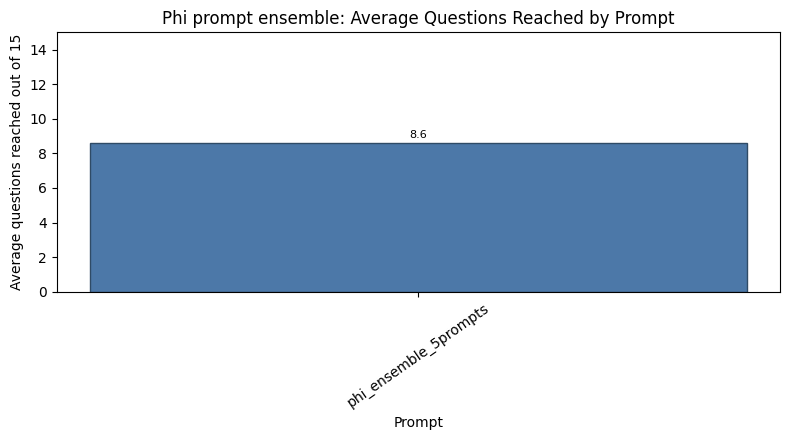

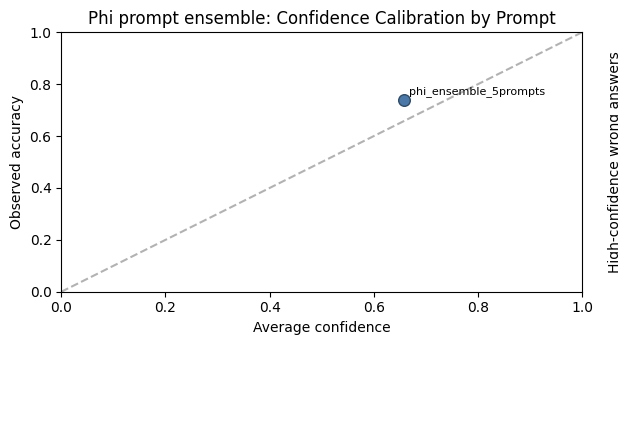

Phi prompt ensemble: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,phi_3_5_mini_prompt_ensemble,phi_3_5_mini_prompt_ensemble_phi_ensemble_5pro...,phi_ensemble_5prompts,5,8.6,11,7.6,38,0.506667,0.666667,19200.0,32000,2.501335,2.852247,1.0,0.506667,non-thinking


Phi prompt ensemble: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
2,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,Ethics & political philosophy,4,4,0,1.000000,4.250000,2,0.133333
0,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,Clinical psychology & mental health,2,2,0,1.000000,6.000000,1,0.133333
5,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,Philosophers & history of ideas,1,1,0,1.000000,1.000000,1,0.066667
4,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,Other philosophy/psychology,24,23,1,0.958333,5.708333,4,0.383333
1,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,Cognitive psychology & memory,4,3,1,0.750000,5.750000,3,0.066667
3,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,"Logic, knowledge & metaphysics",4,3,1,0.750000,6.250000,3,0.066667
6,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,Social psychology,4,2,2,0.500000,7.000000,3,0.044444


,model_label,prompt_type,error_type,count
0,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,Correct,38
1,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,High-confidence wrong answer,3
2,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,Plausible but incorrect answer,2


...

,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate
0,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,43,43,1.0


Phi prompt ensemble: confidence and overconfidence


,model_label,prompt_type,confidence_bucket,questions,observed_accuracy,average_confidence,average_margin,overconfident_errors
0,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,low (<= 0.40),2,0.500000,0.380848,0.022657,0
1,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,medium (0.40-0.70),5,0.800000,0.660095,0.473674,0
2,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,high (>= 0.70),36,0.916667,0.931519,0.886565,3


,model_label,prompt_type,system_name,run_id,level_before_answer,topic,question_text,selected_option_text,raw_response,confidence_score,confidence_margin,option_confidences,correct
42,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,phi_3_5_mini_prompt_ensemble_phi_ensemble_5pro...,5,10,"Logic, knowledge & metaphysics",Which concept refers to Marvin Minsky's theory...,The Society of Mind,"{""prompt_predictions"": [{""prompt_type"": ""psych...",0.998397,0.997405,"{""0"": -10.994423508644104, ""1"": -3.55283406376...",False
9,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,phi_3_5_mini_prompt_ensemble_phi_ensemble_5pro...,1,10,Other philosophy/psychology,"In Stoic philosophy, which concept is the 'bre...",Logos,"{""prompt_predictions"": [{""prompt_type"": ""psych...",0.997418,0.996137,"{""0"": -9.972371339797974, ""1"": -9.808968782424...",False
32,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,phi_3_5_mini_prompt_ensemble_phi_ensemble_5pro...,4,1,Social psychology,Which term best describes a lack of motivation...,Social Anhedonia,"{""prompt_predictions"": [{""prompt_type"": ""psych...",0.888618,0.820341,"{""0"": -6.028374671936035, ""1"": -2.978698939085...",False


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,phi_3_5_mini_prompt_ensemble,phi_3_5_mini_prompt_ensemble_phi_ensemble_5pro...,phi_ensemble_5prompts,5,8.6,11,7.6,38,0.506667,0.666667,19200.0,32000,2.501335,2.852247,1.0,0.506667,non-thinking


In [ ]:
load_phi_model()

df_phi_ensemble = benchmark_answer_fn(
    answer_fn=generate_answer_phi_ensemble,
    model_label="phi_3_5_mini_prompt_ensemble",
    prompt_type="phi_ensemble_5prompts",
    n_runs=5,
    delay_seconds=1.5,
)

phi_ensemble_summary = make_survival_summary(df_phi_ensemble)
phi_ensemble_summary_sorted = sort_survival_summary(phi_ensemble_summary)

df_phi_ensemble.to_csv("philosophy_psychology_phi_3_5_mini_prompt_ensemble.csv", index=False)
phi_ensemble_summary_sorted.to_csv("philosophy_psychology_phi_3_5_mini_prompt_ensemble_summary.csv", index=False)

phi_ensemble_analysis = analyse_model_runs(
    df_phi_ensemble,
    model_tag="Phi prompt ensemble",
    output_prefix="philosophy_psychology_phi_3_5_mini_prompt_ensemble",
    model_type="non-thinking",
)

phi_ensemble_summary_sorted


In [ ]:
best_phi_parts = [
    summary
    for summary in [
        globals().get("phi_fixed_generation_summary"),
        globals().get("phi_forced_choice_summary"),
        globals().get("phi_ensemble_summary_sorted"),
        globals().get("final_survival_summary"),
    ]
    if isinstance(summary, pd.DataFrame)
]

best_phi_summary = sort_survival_summary(
    pd.concat(best_phi_parts, ignore_index=True, sort=False)
) if best_phi_parts else pd.DataFrame()

family_summary_parts = [
    summary
    for summary in [
        globals().get("qwen_comparison_summary_sorted"),
        globals().get("best_phi_summary"),
        globals().get("survival_summary_deepseek_sorted"),
        globals().get("gemma_survival_summary_sorted"),
        globals().get("llama_survival_summary_sorted"),
    ]
    if isinstance(summary, pd.DataFrame)
]

model_family_comparison_after_phi_ensemble = sort_survival_summary(
    pd.concat(family_summary_parts, ignore_index=True, sort=False)
) if family_summary_parts else pd.DataFrame()

best_phi_summary.to_csv("philosophy_psychology_best_phi_summary_after_ensemble.csv", index=False)
model_family_comparison_after_phi_ensemble.to_csv(
    "philosophy_psychology_model_family_comparison_after_phi_ensemble.csv",
    index=False,
)

display(best_phi_summary)
display(model_family_comparison_after_phi_ensemble)


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,phi_3_5_mini_fixed_generation,phi_3_5_mini_fixed_generation_psychology_short,psychology_short,5,14.2,15,13.8,69,0.920000,1.000000,665600.0,1024000,0.435922,0.809280,1.0,0.920000,non-thinking
3,phi_3_5_mini_final_forced_choice,phi_3_5_mini_final_forced_choice_psychology_short,psychology_short,10,10.3,15,9.6,96,0.640000,1.000000,368930.0,1024000,0.393419,0.527117,1.0,0.640000,non-thinking
2,phi_3_5_mini_prompt_ensemble,phi_3_5_mini_prompt_ensemble_phi_ensemble_5pro...,phi_ensemble_5prompts,5,8.6,11,7.6,38,0.506667,0.666667,19200.0,32000,2.501335,2.852247,1.0,0.506667,non-thinking
1,phi_3_5_mini_forced_choice,phi_3_5_mini_forced_choice_psychology_short,psychology_short,5,5.4,10,4.4,22,0.293333,0.600000,4120.0,16000,0.389205,0.514781,1.0,0.293333,non-thinking


,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type,model_type
12,phi_3_5_mini_fixed_generation_psychology_short,5,14.2,15,13.8,69,0.920000,1.000000,665600.0,1024000,0.435922,0.809280,1.000000,0.920000,phi_3_5_mini_fixed_generation,psychology_short,non-thinking
13,phi_3_5_mini_final_forced_choice_psychology_short,10,10.3,15,9.6,96,0.640000,1.000000,368930.0,1024000,0.393419,0.527117,1.000000,0.640000,phi_3_5_mini_final_forced_choice,psychology_short,non-thinking
0,qwen_3b_few_shot_psychology,5,10.2,15,9.6,48,0.640000,1.000000,422560.0,1024000,0.274265,0.315287,1.000000,0.640000,qwen_3b,few_shot_psychology,non-thinking
28,llama_3_8b_forced_choice_psychology_short,5,10.0,15,9.2,46,0.613333,1.000000,231240.0,1024000,1.108579,2.883907,1.000000,0.613333,llama_3_8b_forced_choice,psychology_short,non-thinking
1,qwen_3b_baseline,5,10.0,15,9.2,46,0.613333,1.000000,216100.0,1024000,0.188246,0.402841,1.000000,0.613333,qwen_3b,baseline,non-thinking
29,llama_3_8b_forced_choice_few_shot_psychology,5,8.6,15,8.0,40,0.533333,1.000000,416000.0,1024000,1.573792,1.915610,1.000000,0.533333,llama_3_8b_forced_choice,few_shot_psychology,non-thinking
14,phi_3_5_mini_prompt_ensemble_phi_ensemble_5pro...,5,8.6,11,7.6,38,0.506667,0.666667,19200.0,32000,2.501335,2.852247,1.000000,0.506667,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,non-thinking
2,qwen_1_5b_few_shot_psychology,5,8.4,12,7.4,37,0.493333,0.733333,17660.0,64000,0.168136,0.238302,1.000000,0.493333,qwen_1_5b,few_shot_psychology,NaN
3,qwen_3b_psychology_short,5,8.2,14,7.2,36,0.480000,0.866667,58160.0,256000,0.181930,0.278965,1.000000,0.480000,qwen_3b,psychology_short,non-thinking
22,gemma_2_2b_it_baseline,5,8.2,12,7.2,36,0.480000,0.733333,16460.0,64000,0.357408,0.670946,1.000000,0.480000,gemma_2_2b_it,baseline,non-thinking


### Phi ensemble interpretation

The Phi prompt ensemble did not improve on the best single Phi model. It reached **8.6 average questions**, a best run of **11**, and **38 / 75 = 0.507 game accuracy**, which is clearly below the fixed-generation Phi result.

The ensemble had a valid-output rate of **1.0**, but it was slower and introduced some high-confidence wrong answers. This suggests that prompt diversity alone did not help enough in this task. The best result still comes from a single well-configured Phi prompt rather than a prompt ensemble.

## RAG experiment with the best observed model

This section runs RAG **after** the model-family experiments, so the retrieval experiment uses the strongest base model configuration observed so far instead of assuming that Phi is always best.

Two retrieval styles are available:

- `psych_static`: reproducible RAG using a curated in-notebook psychology/philosophy corpus. This does **not** change between runs, so it is the best option for the report.
- `web_live`: live website RAG using Wikipedia search and page summaries. This can change over time because websites change, so it is useful as an extra experiment but less reproducible.
- `hybrid`: combines the static corpus and live web context.

The code below keeps the same game API and prompt list. It only changes the context placed before the model answers. The static retriever includes topic-aware hints so the passages are usually closer to the Philosophy and Psychology game question.


In [ ]:
import json
import re
import time
from functools import lru_cache
from urllib.parse import quote

import pandas as pd
import requests


PSYCHOLOGY_RAG_TOP_K = 5
RAG_CONTEXT_MAX_CHARS = 560

RAG_RETRIEVAL_MODE = "psych_static"  # Options: "psych_static", "web_live", "hybrid"
RUN_LIVE_WEB_RAG = False  # Set True to include changing live website

PSYCHOLOGY_RAG_STOPWORDS = {
    "the", "and", "or", "of", "to", "in", "a", "an", "is", "are", "was", "were",
    "which", "what", "who", "when", "where", "why", "how", "following", "best",
    "describes", "describe", "option", "answer", "question", "philosophy", "psychology",
    "does", "do", "did", "from", "with", "that", "this", "these", "those", "for",
    "into", "about", "most", "least", "called", "known", "used", "using",
}

TRUSTED_RAG_SOURCE_TABLE = pd.DataFrame(
    [
        {
            "mode": "psych_static",
            "source": "Curated psychology/philosophy static corpus inside this notebook",
            "changes_between_runs": "No",
            "best_use": "Main project comparison because it is reproducible.",
        },
        {
            "mode": "web_live",
            "source": "Wikipedia search and summaries",
            "changes_between_runs": "Yes",
            "best_use": "Optional extension showing live website retrieval.",
        },
        {
            "mode": "hybrid",
            "source": "Static corpus + Wikipedia summaries",
            "changes_between_runs": "Partly",
            "best_use": "Exploratory comparison when you want both stable and live context.",
        },
    ]
)

display(TRUSTED_RAG_SOURCE_TABLE)


PHILOSOPHY_PSYCHOLOGY_RAG_DOCUMENTS = [
    {
        "title": "Classical conditioning",
        "support": "Classical conditioning is associative learning in which a neutral stimulus becomes linked with an unconditioned stimulus and eventually produces a conditioned response. Ivan Pavlov's dog experiments are the standard example.",
        "url": "https://en.wikipedia.org/wiki/Classical_conditioning",
    },
    {
        "title": "Operant conditioning",
        "support": "Operant conditioning explains learning through consequences. Reinforcement increases the probability of a behavior, while punishment decreases it. B. F. Skinner is strongly associated with this approach.",
        "url": "https://en.wikipedia.org/wiki/Operant_conditioning",
    },
    {
        "title": "Memory systems",
        "support": "Working memory temporarily holds and manipulates information, while long-term memory stores information over longer periods. Episodic memory concerns personal events, semantic memory concerns facts, and procedural memory concerns skills.",
        "url": "https://en.wikipedia.org/wiki/Memory",
    },
    {
        "title": "Cognitive biases",
        "support": "Cognitive biases are systematic patterns in judgment. Confirmation bias favors evidence that supports existing beliefs, availability bias relies on easily recalled examples, and anchoring is excessive influence from an initial value.",
        "url": "https://en.wikipedia.org/wiki/Cognitive_bias",
    },
    {
        "title": "Developmental psychology",
        "support": "Jean Piaget proposed stages of cognitive development, including sensorimotor, preoperational, concrete operational, and formal operational stages. Developmental psychology studies change across the lifespan.",
        "url": "https://en.wikipedia.org/wiki/Developmental_psychology",
    },
    {
        "title": "Attachment theory",
        "support": "Attachment theory studies emotional bonds between children and caregivers. John Bowlby and Mary Ainsworth are central figures, and Ainsworth's Strange Situation helped identify attachment patterns.",
        "url": "https://en.wikipedia.org/wiki/Attachment_theory",
    },
    {
        "title": "Social influence",
        "support": "Social psychology studies how people are influenced by others. Conformity is changing behavior to match a group, obedience is following authority, and groupthink is poor decision-making caused by pressure for consensus.",
        "url": "https://en.wikipedia.org/wiki/Social_psychology",
    },
    {
        "title": "Milgram experiment",
        "support": "Stanley Milgram's obedience experiments examined willingness to follow authority even when actions appeared to harm another person. They are often discussed in social psychology and research ethics.",
        "url": "https://en.wikipedia.org/wiki/Milgram_experiment",
    },
    {
        "title": "Freud and psychoanalysis",
        "support": "Sigmund Freud founded psychoanalysis and emphasized unconscious conflict, defense mechanisms, dream interpretation, and early experience. The id, ego, and superego are Freudian structural concepts.",
        "url": "https://en.wikipedia.org/wiki/Psychoanalysis",
    },
    {
        "title": "Humanistic psychology",
        "support": "Humanistic psychology emphasizes personal growth, free will, meaning, and self-actualization. Abraham Maslow and Carl Rogers are major figures; Rogers is associated with client-centered therapy.",
        "url": "https://en.wikipedia.org/wiki/Humanistic_psychology",
    },
    {
        "title": "Clinical psychology and disorders",
        "support": "Clinical psychology assesses and treats mental disorders. Anxiety disorders involve excessive fear or worry, mood disorders involve disturbances in mood, and cognitive behavioral therapy connects thoughts, emotions, and behavior.",
        "url": "https://en.wikipedia.org/wiki/Clinical_psychology",
    },
    {
        "title": "Perception and Gestalt principles",
        "support": "Gestalt psychology emphasizes organized perception. Principles such as proximity, similarity, closure, continuity, and figure-ground help explain how people perceive patterns and wholes.",
        "url": "https://en.wikipedia.org/wiki/Gestalt_psychology",
    },
    {
        "title": "Neurons and neurotransmitters",
        "support": "Neurons communicate through electrical and chemical signals. Neurotransmitters such as dopamine, serotonin, acetylcholine, and GABA are often linked to reward, mood, movement, memory, and inhibition.",
        "url": "https://en.wikipedia.org/wiki/Neurotransmitter",
    },
    {
        "title": "Epistemology",
        "support": "Epistemology is the branch of philosophy concerned with knowledge, justification, belief, evidence, and skepticism. It asks what knowledge is and how knowledge is possible.",
        "url": "https://en.wikipedia.org/wiki/Epistemology",
    },
    {
        "title": "Metaphysics",
        "support": "Metaphysics studies the basic nature of reality, including being, identity, causation, time, free will, possibility, and the relation between mind and body.",
        "url": "https://en.wikipedia.org/wiki/Metaphysics",
    },
    {
        "title": "Logic",
        "support": "Logic studies valid reasoning and argument forms. Deductive arguments aim for necessary truth if the premises are true; inductive arguments support probable conclusions.",
        "url": "https://en.wikipedia.org/wiki/Logic",
    },
    {
        "title": "Utilitarianism",
        "support": "Utilitarianism is a consequentialist ethical theory that judges actions by their outcomes, especially their tendency to maximize overall happiness, welfare, or utility. Jeremy Bentham and John Stuart Mill are key figures.",
        "url": "https://en.wikipedia.org/wiki/Utilitarianism",
    },
    {
        "title": "Kantian ethics",
        "support": "Kantian ethics is deontological and emphasizes duty, rational moral law, and the categorical imperative. It judges actions by principles rather than only by consequences.",
        "url": "https://en.wikipedia.org/wiki/Kantian_ethics",
    },
    {
        "title": "Virtue ethics",
        "support": "Virtue ethics focuses on character traits and human flourishing rather than only rules or consequences. Aristotle is the central historical figure, and virtues such as courage and temperance are important examples.",
        "url": "https://en.wikipedia.org/wiki/Virtue_ethics",
    },
    {
        "title": "Plato and forms",
        "support": "Plato's theory of Forms distinguishes changing sensible things from abstract, intelligible Forms. The Republic discusses justice, the philosopher-king, and the allegory of the cave.",
        "url": "https://en.wikipedia.org/wiki/Plato",
    },
    {
        "title": "Aristotle",
        "support": "Aristotle wrote on logic, ethics, metaphysics, politics, biology, and rhetoric. His ethics emphasizes virtue, practical wisdom, habit, and eudaimonia or flourishing.",
        "url": "https://en.wikipedia.org/wiki/Aristotle",
    },
    {
        "title": "Descartes and rationalism",
        "support": "Rene Descartes is associated with rationalism, methodic doubt, mind-body dualism, and the phrase cogito ergo sum. Rationalists emphasize reason as a source of knowledge.",
        "url": "https://en.wikipedia.org/wiki/Ren%C3%A9_Descartes",
    },
    {
        "title": "Empiricism",
        "support": "Empiricism emphasizes experience and sensory observation as sources of knowledge. John Locke, George Berkeley, and David Hume are major empiricist philosophers.",
        "url": "https://en.wikipedia.org/wiki/Empiricism",
    },
    {
        "title": "Existentialism",
        "support": "Existentialism emphasizes freedom, responsibility, anxiety, authenticity, and meaning in human life. Soren Kierkegaard, Friedrich Nietzsche, Jean-Paul Sartre, and Simone de Beauvoir are often associated with it.",
        "url": "https://en.wikipedia.org/wiki/Existentialism",
    },
    {
        "title": "Political philosophy",
        "support": "Political philosophy studies justice, rights, authority, liberty, equality, democracy, and the state. Social contract theories are associated with Hobbes, Locke, Rousseau, and later Rawls.",
        "url": "https://en.wikipedia.org/wiki/Political_philosophy",
    },
]


def rag_terms(text):
    """Return useful retrieval terms from a question, answer option, or support passage."""
    return {
        token
        for token in re.findall(r"[a-zA-Z][a-zA-Z0-9\-]+", str(text).lower())
        if len(token) > 2 and token not in PSYCHOLOGY_RAG_STOPWORDS
    }


def shorten_for_prompt(text, max_chars=650):
    """Keep retrieved passages short enough for fast local generation."""
    text = re.sub(r"\s+", " ", str(text)).strip()
    if len(text) <= max_chars:
        return text
    return text[: max_chars - 3].rstrip() + "..."


RAG_TOPIC_HINTS = {
    "Cognitive psychology & memory": "cognition memory attention working episodic semantic reasoning bias decision perception",
    "Learning & behavior": "learning conditioning reinforcement punishment behavior stimulus response skinner pavlov",
    "Social psychology": "social conformity obedience group influence attitude attribution milgram zimbardo prejudice",
    "Developmental psychology": "development child piaget attachment bowlby ainsworth adolescence lifespan",
    "Clinical psychology & mental health": "clinical disorder therapy anxiety depression diagnosis psychoanalysis cognitive behavioral",
    "Neuroscience & perception": "brain neuron neurotransmitter perception sensation dopamine serotonin nervous gestalt",
    "Ethics & political philosophy": "ethics moral duty virtue utility justice rights liberty social contract political",
    "Logic, knowledge & metaphysics": "logic argument validity knowledge belief justification reality metaphysics causation skepticism",
    "Philosophers & history of ideas": "plato aristotle socrates kant descartes hume nietzsche freud rogers piaget history",
}


def rag_query_text(question):
    """Build a retrieval query from question, options, and the psychology/philosophy-topic hint."""
    options_text = " ".join(option.text for option in question.options)
    topic = classify_psychology_question(f"{question.text} {options_text}") if "classify_psychology_question" in globals() else ""
    topic_hint = RAG_TOPIC_HINTS.get(topic, "")
    return f"{question.text} {options_text} {topic_hint}".strip(), topic


@lru_cache(maxsize=1)
def load_psychology_rag_corpus():
    """Load the static psychology/philosophy corpus once into a lexical retrieval format."""
    documents = []

    for row_id, row in enumerate(PHILOSOPHY_PSYCHOLOGY_RAG_DOCUMENTS):
        title = str(row.get("title", "")).strip()
        support = str(row.get("support", "")).strip()
        if not support:
            continue

        retrieval_text = " ".join([title, support])
        documents.append(
            {
                "source": f"Static psychology/philosophy corpus row {row_id}",
                "source_type": "psych_static",
                "title": title,
                "support": support,
                "url": row.get("url", ""),
                "terms": rag_terms(retrieval_text),
            }
        )

    print(f"Loaded {len(documents)} static psychology/philosophy passages for RAG retrieval.")
    return documents


def retrieve_static_psychology_context(question, top_k=PSYCHOLOGY_RAG_TOP_K):
    """Retrieve stable psychology/philosophy passages related to the current game question."""
    query_text, topic = rag_query_text(question)
    option_texts = [str(option.text).lower() for option in question.options]
    query_terms = rag_terms(query_text)

    if not query_terms:
        return []

    scored_docs = []
    for document in load_psychology_rag_corpus():
        overlap = query_terms & document["terms"]
        if not overlap:
            continue

        query_coverage = len(overlap) / max(1, len(query_terms))
        document_focus = len(overlap) / max(1, len(document["terms"]))
        support_lower = f"{document['title']} {document['support']}".lower()
        option_phrase_bonus = 0.22 if any(option_text and option_text in support_lower for option_text in option_texts) else 0.0
        title_overlap_bonus = 0.14 * len(rag_terms(document["title"]) & query_terms)
        score = query_coverage + 0.35 * document_focus + option_phrase_bonus + title_overlap_bonus

        scored_docs.append(
            {
                "source": document["source"],
                "source_type": document["source_type"],
                "title": document["title"],
                "support": document["support"],
                "url": document["url"],
                "score": score,
                "matched_terms": sorted(overlap),
                "topic_hint": topic,
            }
        )

    return sorted(scored_docs, key=lambda item: item["score"], reverse=True)[:top_k]


@lru_cache(maxsize=256)
def fetch_wikipedia_summary(title):
    """Fetch a live Wikipedia summary. This can change over time."""
    url = f"https://en.wikipedia.org/api/rest_v1/page/summary/{quote(title, safe='')}"
    headers = {"User-Agent": "philosophy-psychology-quiz-rag-notebook/1.0 student project"}
    response = requests.get(url, headers=headers, timeout=10)
    response.raise_for_status()
    payload = response.json()
    return {
        "title": payload.get("title", title),
        "support": payload.get("extract", ""),
        "url": payload.get("content_urls", {}).get("desktop", {}).get("page", url),
    }


@lru_cache(maxsize=256)
def search_wikipedia_titles(query, limit=5):
    """Search Wikipedia for live page titles related to the question."""
    search_url = "https://en.wikipedia.org/w/api.php"
    headers = {"User-Agent": "philosophy-psychology-quiz-rag-notebook/1.0 student project"}
    params = {
        "action": "query",
        "list": "search",
        "srsearch": query,
        "srlimit": limit,
        "format": "json",
        "origin": "*",
    }
    response = requests.get(search_url, headers=headers, params=params, timeout=10)
    response.raise_for_status()
    results = response.json().get("query", {}).get("search", [])
    return tuple(result.get("title", "") for result in results if result.get("title"))


def retrieve_live_web_context(question, top_k=PSYCHOLOGY_RAG_TOP_K):
    """Retrieve live website context from Wikipedia summaries."""
    query_text, topic = rag_query_text(question)
    query_terms = sorted(rag_terms(query_text))
    compact_query = " ".join(query_terms[:10]) or question.text

    retrieved_docs = []
    try:
        titles = search_wikipedia_titles(compact_query, limit=max(5, top_k))
    except Exception as error:
        print("Live web RAG search failed:", repr(error))
        return []

    for title in titles:
        try:
            summary = fetch_wikipedia_summary(title)
        except Exception:
            continue

        support = summary.get("support", "")
        if not support:
            continue

        overlap = rag_terms(f"{summary.get('title', '')} {support}") & set(query_terms)
        score = len(overlap) / max(1, len(query_terms))
        retrieved_docs.append(
            {
                "source": "Wikipedia live summary",
                "source_type": "web_live",
                "title": summary.get("title", title),
                "support": support,
                "url": summary.get("url"),
                "score": score,
                "matched_terms": sorted(overlap),
                "topic_hint": topic,
            }
        )

    return sorted(retrieved_docs, key=lambda item: item["score"], reverse=True)[:top_k]


def retrieve_rag_context(question, mode=RAG_RETRIEVAL_MODE, top_k=PSYCHOLOGY_RAG_TOP_K):
    """Retrieve RAG context from the selected source mode."""
    if mode == "psych_static":
        return retrieve_static_psychology_context(question, top_k=top_k)
    if mode == "web_live":
        return retrieve_live_web_context(question, top_k=top_k)
    if mode == "hybrid":
        docs = retrieve_static_psychology_context(question, top_k=top_k) + retrieve_live_web_context(question, top_k=top_k)
        return sorted(docs, key=lambda item: item["score"], reverse=True)[:top_k]
    raise ValueError(f"Unknown RAG retrieval mode: {mode}")


def build_rag_prompt(question, prompt_type="psychology_short", rag_mode=RAG_RETRIEVAL_MODE, top_k=PSYCHOLOGY_RAG_TOP_K):
    """Build a prompt that adds retrieved context before the normal game prompt."""
    base_prompt = build_prompt_from_type(question, prompt_type)
    retrieved_docs = retrieve_rag_context(question, mode=rag_mode, top_k=top_k)

    if retrieved_docs:
        context_text = "\n".join(
            f"[{rank}] ({doc['source_type']}) {doc.get('title', 'Psychology/philosophy source')}: "
            f"{shorten_for_prompt(doc['support'], max_chars=RAG_CONTEXT_MAX_CHARS)} "
            f"[matched: {', '.join(doc.get('matched_terms', [])[:5]) or 'general'}]"
            for rank, doc in enumerate(retrieved_docs, start=1)
        )
    else:
        context_text = "No highly related retrieval passage was found. Use general psychology and philosophy knowledge."

    rag_prompt = f"""
Use the retrieved context as background. Prefer the option that is best supported by the context and the question. If a passage is not relevant, ignore it.\n\nRetrieved context:
{context_text}

{base_prompt}
""".strip()

    return rag_prompt, retrieved_docs


BASE_MODEL_SPECS_FOR_RAG = [
    {
        "family": "phi",
        "patterns": ["phi_3_5"],
        "model_id": "microsoft/Phi-3.5-mini-instruct",
        "model_key": "phi_3_5_mini_rag",
        "use_4bit": False,
        "loader": "phi",
        "answer_style": "forced_choice",
    },
    {
        "family": "qwen_1_5b",
        "patterns": ["qwen_1_5b", "qwen2.5-1.5b"],
        "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
        "model_key": "qwen_1_5b_rag",
        "use_4bit": False,
        "answer_style": "chat",
    },
    {
        "family": "qwen_3b",
        "patterns": ["qwen_3b", "qwen2.5-3b"],
        "model_id": "Qwen/Qwen2.5-3B-Instruct",
        "model_key": "qwen_3b_rag",
        "use_4bit": False,
        "answer_style": "chat",
    },
    {
        "family": "deepseek",
        "patterns": ["deepseek"],
        "model_id": "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
        "model_key": "deepseek_r1_1_5b_rag",
        "use_4bit": False,
        "answer_style": "chat",
    },
    {
        "family": "gemma",
        "patterns": ["gemma"],
        "model_id": "google/gemma-2-2b-it",
        "model_key": "gemma_2_2b_it_rag",
        "use_4bit": False,
        "answer_style": "chat",
    },
    {
        "family": "llama",
        "patterns": ["llama"],
        "model_id": "meta-llama/Meta-Llama-3-8B",
        "model_key": "llama_3_8b_rag",
        "use_4bit": True,
        "answer_style": "forced_choice",
    },
]


def collect_base_model_summaries_for_selection():
    """Collect already-run base model summaries without using ensemble/RAG rows."""
    summary_names = [
        "survival_summary_qwen_1_5b",
        "qwen_comparison_summary_sorted",
        "survival_summary_qwen3b",
        "survival_summary_best_qwen3b",
        "survival_summary_current_model",
        "phi_fixed_generation_summary",
        "phi_forced_choice_summary",
        "phi_fixed_comparison",
        "final_survival_summary",
        "survival_summary_deepseek_sorted",
        "gemma_survival_summary_sorted",
        "llama_survival_summary_sorted",
    ]
    summaries = []

    for summary_name in summary_names:
        value = globals().get(summary_name)
        if isinstance(value, pd.DataFrame) and not value.empty:
            df_summary = value.copy()
            df_summary["summary_source"] = summary_name
            summaries.append(df_summary)

    if not summaries:
        return pd.DataFrame()

    table = pd.concat(summaries, ignore_index=True, sort=False)
    if "model_label" not in table.columns:
        table["model_label"] = table.get("system_name", "").astype(str)

    text_columns = ["summary_source", "model_label", "system_name", "prompt_type"]
    row_text = table[[column for column in text_columns if column in table.columns]].astype(str).agg(" ".join, axis=1).str.lower()
    excluded = row_text.str.contains("ensemble|rag|top3|controlled", regex=True)
    table = table.loc[~excluded].copy()

    required_columns = ["average_questions_reached", "best_questions_reached", "valid_output_rate"]
    for column in required_columns:
        if column not in table.columns:
            table[column] = 0
        table[column] = pd.to_numeric(table[column], errors="coerce").fillna(0)

    return table.sort_values(
        by=["average_questions_reached", "best_questions_reached", "valid_output_rate"],
        ascending=False,
    )


def model_spec_from_summary_row(row):
    """Map a summary row to a loadable model architecture."""
    row_text = " ".join(
        str(row.get(column, ""))
        for column in ["summary_source", "model_label", "system_name", "prompt_type"]
    ).lower()

    for spec in BASE_MODEL_SPECS_FOR_RAG:
        if spec["family"] == "gemma" and not globals().get("RUN_GEMMA", False):
            continue
        if any(pattern in row_text for pattern in spec["patterns"]):
            candidate = spec.copy()
            candidate["prompt_type"] = str(row.get("prompt_type", "psychology_short"))
            candidate["observed_average_questions_reached"] = row.get("average_questions_reached")
            candidate["observed_best_questions_reached"] = row.get("best_questions_reached")
            candidate["observed_valid_output_rate"] = row.get("valid_output_rate")
            candidate["source_model_label"] = row.get("model_label")
            candidate["source_system_name"] = row.get("system_name")
            return candidate

    return None


def select_best_base_model_for_rag():
    """Select the best observed non-ensemble, non-RAG model configuration."""
    summary_table = collect_base_model_summaries_for_selection()
    candidates = []

    for _, row in summary_table.iterrows():
        candidate = model_spec_from_summary_row(row)
        if candidate is not None:
            candidates.append(candidate)

    if candidates:
        return candidates[0], summary_table

    fallback = BASE_MODEL_SPECS_FOR_RAG[0].copy()
    fallback["prompt_type"] = "psychology_short"
    fallback["observed_average_questions_reached"] = None
    fallback["source_model_label"] = "fallback_phi"
    return fallback, summary_table


active_rag_model_key = None


def load_rag_model_candidate(candidate):
    """Load the selected model for the RAG experiment."""
    global active_rag_model_key

    if active_rag_model_key == candidate["model_key"]:
        return

    if candidate.get("loader") == "phi":
        load_phi_model()
    else:
        load_chat_model(
            model_id=candidate["model_id"],
            model_label=f"{candidate['family']}_best_rag",
            use_4bit=candidate.get("use_4bit", False),
        )

    active_rag_model_key = candidate["model_key"]


def split_rag_prompt_type(prompt_type):
    """Split a combined prompt like psych_static_psychology_short into mode and base prompt."""
    for mode in ["psych_static", "web_live", "hybrid"]:
        prefix = mode + "_"
        if str(prompt_type).startswith(prefix):
            return mode, str(prompt_type)[len(prefix):]
    return RAG_RETRIEVAL_MODE, prompt_type


def generate_answer_rag_forced_choice(question, prompt_type="psychology_short", rag_mode=RAG_RETRIEVAL_MODE):
    """Use retrieved context, then score each answer option by likelihood."""
    rag_prompt, retrieved_docs = build_rag_prompt(question, prompt_type=prompt_type, rag_mode=rag_mode)
    formatted_prompt = format_model_prompt(rag_prompt)
    base_text = formatted_prompt + "\nThe correct answer is option"
    start_time = time.time()
    option_scores = {}

    for option in question.options:
        candidate_text = f" {option.id}: {option.text}"
        score, token_count = score_candidate_continuation_generic(
            base_text,
            candidate_text,
            return_token_count=True,
        )
        option_scores[int(option.id)] = {
            "score": score,
            "tokens": token_count,
            "text": option.text,
        }

    predicted_id = max(option_scores, key=lambda option_id: option_scores[option_id]["score"])
    option_score_values = {
        option_id: values["score"]
        for option_id, values in option_scores.items()
    }
    confidence_score, confidence_margin = confidence_margin_from_scores(
        option_score_values,
        predicted_id,
    )

    return {
        "prompt_type": f"{rag_mode}_{prompt_type}",
        "prompt": rag_prompt,
        "raw_response": json.dumps(
            {
                "rag_mode": rag_mode,
                "retrieved_docs": retrieved_docs,
                "option_scores": option_scores,
            },
            ensure_ascii=False,
        ),
        "predicted_id": predicted_id,
        "response_time": time.time() - start_time,
        "option_confidences": option_score_values,
        "confidence_score": confidence_score,
        "confidence_margin": confidence_margin,
    }


def generate_answer_rag_chat(question, prompt_type="psychology_short", rag_mode=RAG_RETRIEVAL_MODE):
    """Use retrieved context with a normal chat-template generation model."""
    rag_prompt, retrieved_docs = build_rag_prompt(question, prompt_type=prompt_type, rag_mode=rag_mode)
    formatted_prompt = format_model_prompt(rag_prompt)
    valid_option_ids = [option.id for option in question.options]
    start_time = time.time()

    option_confidences = estimate_option_confidences(
        formatted_prompt=formatted_prompt,
        valid_option_ids=valid_option_ids,
    )

    inputs = tokenizer(formatted_prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=generation_token_budget(prompt_type, 16),
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[-1]:]
    raw_generation = tokenizer.decode(generated_tokens, skip_special_tokens=True).strip()
    predicted_id = parse_option_id(raw_generation, valid_option_ids)
    confidence_score, confidence_margin = confidence_margin_from_scores(
        option_confidences,
        predicted_id,
    )

    return {
        "prompt_type": f"{rag_mode}_{prompt_type}",
        "prompt": rag_prompt,
        "raw_response": json.dumps(
            {
                "rag_mode": rag_mode,
                "retrieved_docs": retrieved_docs,
                "generation": raw_generation,
            },
            ensure_ascii=False,
        ),
        "predicted_id": predicted_id,
        "response_time": time.time() - start_time,
        "option_confidences": option_confidences,
        "confidence_score": confidence_score,
        "confidence_margin": confidence_margin,
    }


def generate_answer_best_model_rag(question, prompt_type="psych_static_psychology_short"):
    """Run RAG using the best observed base model architecture."""
    rag_mode, base_prompt_type = split_rag_prompt_type(prompt_type)
    candidate = globals().get("best_model_rag_candidate")

    if candidate is None:
        candidate, _ = select_best_base_model_for_rag()
        globals()["best_model_rag_candidate"] = candidate

    load_rag_model_candidate(candidate)

    if candidate.get("answer_style") == "forced_choice":
        return generate_answer_rag_forced_choice(
            question,
            prompt_type=base_prompt_type,
            rag_mode=rag_mode,
        )

    return generate_answer_rag_chat(
        question,
        prompt_type=base_prompt_type,
        rag_mode=rag_mode,
    )


,mode,source,changes_between_runs,best_use
0,psych_static,Curated psychology/philosophy static corpus in...,No,Main project comparison because it is reproduc...
1,web_live,Wikipedia search and summaries,Yes,Optional extension showing live website retrie...
2,hybrid,Static corpus + Wikipedia summaries,Partly,Exploratory comparison when you want both stab...


,family,source_model_label,prompt_type,observed_average_questions_reached,observed_best_questions_reached,observed_valid_output_rate
0,phi,phi_3_5_mini_fixed_generation,psychology_short,14.2,15,1.0



Running model=phi_best_model_psych_static_rag, prompt=psych_static_baseline, run 1/5
Started game session: 241400
System: phi_best_model_psych_static_rag_psych_static_baseline


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded fixed Phi model: microsoft/Phi-3.5-mini-instruct
Loaded 25 static psychology/philosophy passages for RAG retrieval.

Level 1
Question: What term describes the philosophical approach where Bertrand Russell and his colleagues attempted to reduce all mathematics to logic?
Raw response: {"rag_mode": "psych_static", "retrieved_docs": [{"source": "Static psychology/philosophy corpus row 22", "source_type": "psych_static", "title": "Empiricism", "support": "Empiricism emphasizes experience and sensory observation as sources of knowledge. John Locke, George Berkeley, and David Hume are major empiricist philosophers.", "url": "https://en.wikipedia.org/wiki/Empiricism", "score": 0.48375, "matched_terms": ["empiricism", "knowledge"], "topic_hint": "Logic, knowledge & metaphysics"}, {"source": "Static psychology/philosophy corpus row 23", "source_type": "psych_static", "title": "Existentialism", "support": "Existentialism emphasizes freedom, responsibility, anxiety, authenticity, and meanin

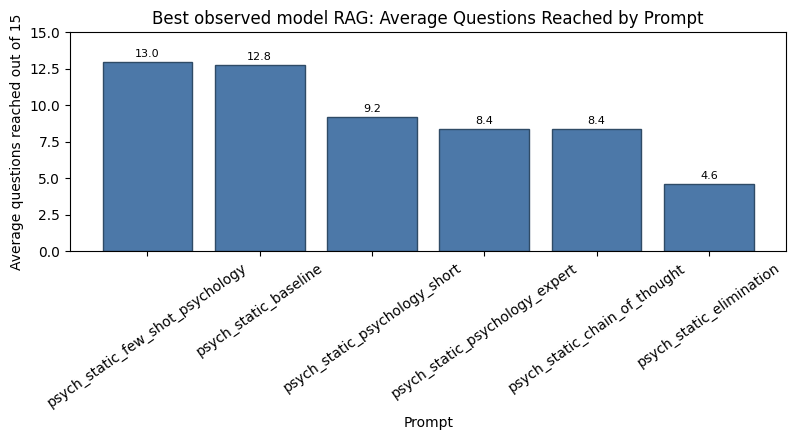

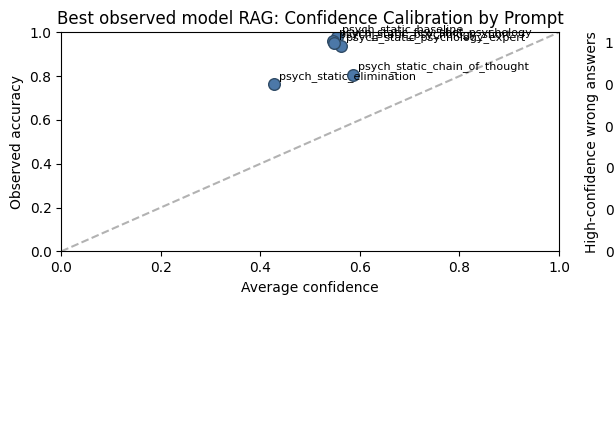

Best observed model RAG: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
3,phi_best_model_psych_static_rag,phi_best_model_psych_static_rag_psych_static_f...,psych_static_few_shot_psychology,5,13.00,15,12.4,62,0.826667,1.0,538000.0,1024000,1.622264,1.938405,1.0,0.826667,rag
0,phi_best_model_psych_static_rag,phi_best_model_psych_static_rag_psych_static_b...,psych_static_baseline,4,12.75,15,12.5,50,0.833333,1.0,768250.0,1024000,1.072650,1.305837,1.0,0.833333,rag
5,phi_best_model_psych_static_rag,phi_best_model_psych_static_rag_psych_static_p...,psych_static_psychology_short,5,9.20,15,8.6,43,0.573333,1.0,412880.0,1024000,1.114842,1.363834,1.0,0.573333,rag
4,phi_best_model_psych_static_rag,phi_best_model_psych_static_rag_psych_static_p...,psych_static_psychology_expert,5,8.40,15,7.6,38,0.506667,1.0,256860.0,1024000,1.202138,1.453095,1.0,0.506667,rag
1,phi_best_model_psych_static_rag,phi_best_model_psych_static_rag_psych_static_c...,psych_static_chain_of_thought,5,8.40,15,7.6,38,0.506667,1.0,217960.0,1024000,1.264109,1.495483,1.0,0.506667,rag
2,phi_best_model_psych_static_rag,phi_best_model_psych_static_rag_psych_static_e...,psych_static_elimination,5,4.60,7,3.6,18,0.240000,0.4,680.0,2000,1.119349,1.362198,1.0,0.240000,rag


Best observed model RAG: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
5,phi_best_model_psych_static_rag,psych_static_baseline,Other philosophy/psychology,23,23,0,1.000000,8.043478,4,0.383333
2,phi_best_model_psych_static_rag,psych_static_baseline,Ethics & political philosophy,10,10,0,1.000000,7.000000,4,0.166667
4,phi_best_model_psych_static_rag,psych_static_baseline,"Logic, knowledge & metaphysics",5,5,0,1.000000,5.800000,2,0.166667
1,phi_best_model_psych_static_rag,psych_static_baseline,Cognitive psychology & memory,4,4,0,1.000000,7.000000,4,0.066667
7,phi_best_model_psych_static_rag,psych_static_baseline,Social psychology,4,4,0,1.000000,8.250000,3,0.088889
6,phi_best_model_psych_static_rag,psych_static_baseline,Philosophers & history of ideas,2,2,0,1.000000,10.000000,2,0.066667
0,phi_best_model_psych_static_rag,psych_static_baseline,Clinical psychology & mental health,1,1,0,1.000000,5.000000,1,0.066667
3,phi_best_model_psych_static_rag,psych_static_baseline,Learning & behavior,2,1,1,0.500000,5.500000,2,0.033333
14,phi_best_model_psych_static_rag,psych_static_chain_of_thought,Other philosophy/psychology,18,18,0,1.000000,4.277778,5,0.240000
10,phi_best_model_psych_static_rag,psych_static_chain_of_thought,Ethics & political philosophy,6,6,0,1.000000,6.000000,3,0.133333


,model_label,prompt_type,error_type,count
0,phi_best_model_psych_static_rag,psych_static_baseline,Correct,50
1,phi_best_model_psych_static_rag,psych_static_baseline,Plausible but incorrect answer,1
2,phi_best_model_psych_static_rag,psych_static_chain_of_thought,Correct,38
3,phi_best_model_psych_static_rag,psych_static_chain_of_thought,High-confidence wrong answer,1
4,phi_best_model_psych_static_rag,psych_static_chain_of_thought,Plausible but incorrect answer,3
5,phi_best_model_psych_static_rag,psych_static_elimination,Correct,18
6,phi_best_model_psych_static_rag,psych_static_elimination,Plausible but incorrect answer,5
7,phi_best_model_psych_static_rag,psych_static_few_shot_psychology,Correct,62
8,phi_best_model_psych_static_rag,psych_static_few_shot_psychology,Plausible but incorrect answer,3
9,phi_best_model_psych_static_rag,psych_static_psychology_expert,Correct,38


...

,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate
0,phi_best_model_psych_static_rag,psych_static_baseline,51,51,1.0
1,phi_best_model_psych_static_rag,psych_static_chain_of_thought,42,42,1.0
2,phi_best_model_psych_static_rag,psych_static_elimination,23,23,1.0
3,phi_best_model_psych_static_rag,psych_static_few_shot_psychology,65,65,1.0
4,phi_best_model_psych_static_rag,psych_static_psychology_expert,42,42,1.0
5,phi_best_model_psych_static_rag,psych_static_psychology_short,46,46,1.0


Best observed model RAG: confidence and overconfidence


,model_label,prompt_type,confidence_bucket,questions,observed_accuracy,average_confidence,average_margin,overconfident_errors
0,phi_best_model_psych_static_rag,psych_static_baseline,low (<= 0.40),15,0.933333,0.364075,0.097947,0
1,phi_best_model_psych_static_rag,psych_static_baseline,medium (0.40-0.70),31,1.000000,0.508025,0.289142,0
2,phi_best_model_psych_static_rag,psych_static_baseline,high (>= 0.70),5,1.000000,0.788374,0.664872,0
3,phi_best_model_psych_static_rag,psych_static_chain_of_thought,low (<= 0.40),6,0.500000,0.368764,0.070273,0
4,phi_best_model_psych_static_rag,psych_static_chain_of_thought,medium (0.40-0.70),24,1.000000,0.563322,0.370487,0
5,phi_best_model_psych_static_rag,psych_static_chain_of_thought,high (>= 0.70),12,0.916667,0.824718,0.737279,1
6,phi_best_model_psych_static_rag,psych_static_elimination,low (<= 0.40),9,0.666667,0.355329,0.096337,0
7,phi_best_model_psych_static_rag,psych_static_elimination,medium (0.40-0.70),14,0.857143,0.497665,0.280652,0
8,phi_best_model_psych_static_rag,psych_static_elimination,high (>= 0.70),0,NaN,NaN,NaN,0
9,phi_best_model_psych_static_rag,psych_static_few_shot_psychology,low (<= 0.40),26,0.884615,0.351579,0.086026,0


,model_label,prompt_type,system_name,run_id,level_before_answer,topic,question_text,selected_option_text,raw_response,confidence_score,confidence_margin,option_confidences,correct
231,phi_best_model_psych_static_rag,psych_static_chain_of_thought,phi_best_model_psych_static_rag_psych_static_c...,1,4,Learning & behavior,Which term describes the mental recreation of ...,Distal Stimulus,"{""rag_mode"": ""psych_static"", ""retrieved_docs"":...",0.779799,0.665642,"{""0"": -4.83695125579834, ""1"": -2.6331894397735...",False


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
3,phi_best_model_psych_static_rag,phi_best_model_psych_static_rag_psych_static_f...,psych_static_few_shot_psychology,5,13.0,15,12.4,62,0.826667,1.0,538000.0,1024000,1.622264,1.938405,1.0,0.826667,rag
0,phi_best_model_psych_static_rag,phi_best_model_psych_static_rag_psych_static_b...,psych_static_baseline,5,10.4,15,10.0,50,0.666667,1.0,614600.0,1024000,1.076137,1.305837,1.0,0.666667,rag
5,phi_best_model_psych_static_rag,phi_best_model_psych_static_rag_psych_static_p...,psych_static_psychology_short,5,9.2,15,8.6,43,0.573333,1.0,412880.0,1024000,1.114842,1.363834,1.0,0.573333,rag
4,phi_best_model_psych_static_rag,phi_best_model_psych_static_rag_psych_static_p...,psych_static_psychology_expert,5,8.4,15,7.6,38,0.506667,1.0,256860.0,1024000,1.202138,1.453095,1.0,0.506667,rag
1,phi_best_model_psych_static_rag,phi_best_model_psych_static_rag_psych_static_c...,psych_static_chain_of_thought,5,8.4,15,7.6,38,0.506667,1.0,217960.0,1024000,1.264109,1.495483,1.0,0.506667,rag
2,phi_best_model_psych_static_rag,phi_best_model_psych_static_rag_psych_static_e...,psych_static_elimination,5,4.6,7,3.6,18,0.24,0.4,680.0,2000,1.119349,1.362198,1.0,0.24,rag


In [ ]:
RUN_BEST_MODEL_RAG = True
BEST_MODEL_RAG_RUNS = 5
BEST_MODEL_RAG_PROMPT_TYPES = PROMPT_TYPES
BEST_MODEL_RAG_MODES = ["psych_static"] + (["hybrid", "web_live"] if RUN_LIVE_WEB_RAG else [])

best_model_rag_candidate, best_model_rag_selection_table = select_best_base_model_for_rag()

best_model_rag_selection_display = pd.DataFrame([best_model_rag_candidate])
best_model_rag_display_columns = [
    "family",
    "source_model_label",
    "prompt_type",
    "observed_average_questions_reached",
    "observed_best_questions_reached",
    "observed_valid_output_rate",
]
display(
    best_model_rag_selection_display[
        [column for column in best_model_rag_display_columns if column in best_model_rag_selection_display.columns]
    ]
)

if RUN_BEST_MODEL_RAG:
    best_model_rag_results = []

    for rag_mode in BEST_MODEL_RAG_MODES:
        for base_prompt_type in BEST_MODEL_RAG_PROMPT_TYPES:
            combined_prompt_type = f"{rag_mode}_{base_prompt_type}"
            df_rag_prompt = benchmark_answer_fn(
                answer_fn=generate_answer_best_model_rag,
                model_label=f"{best_model_rag_candidate['family']}_best_model_{rag_mode}_rag",
                prompt_type=combined_prompt_type,
                n_runs=BEST_MODEL_RAG_RUNS,
                delay_seconds=1.5,
            )
            best_model_rag_results.append(df_rag_prompt)

    df_best_model_rag = pd.concat(best_model_rag_results, ignore_index=True)
    best_model_rag_summary = make_survival_summary(df_best_model_rag, model_type="rag")
    best_model_rag_summary_sorted = sort_survival_summary(best_model_rag_summary)

    # Keep these legacy names so later notebook sections still include the RAG experiment.
    df_phi_rag = df_best_model_rag
    phi_rag_summary_sorted = best_model_rag_summary_sorted

    df_best_model_rag.to_csv("philosophy_psychology_best_model_rag_results.csv", index=False)
    best_model_rag_summary_sorted.to_csv("philosophy_psychology_best_model_rag_summary.csv", index=False)

    best_model_rag_analysis = analyse_model_runs(
        df_best_model_rag,
        model_tag="Best observed model RAG",
        output_prefix="philosophy_psychology_best_model_rag",
        model_type="rag",
    )
    phi_rag_analysis = best_model_rag_analysis

    display(best_model_rag_summary_sorted)
else:
    df_best_model_rag = pd.DataFrame()
    best_model_rag_summary_sorted = pd.DataFrame()
    best_model_rag_analysis = {}
    df_phi_rag = pd.DataFrame()
    phi_rag_summary_sorted = pd.DataFrame()
    phi_rag_analysis = {}
    print("Best-model RAG is disabled. Set RUN_BEST_MODEL_RAG = True when you are ready.")


### RAG interpretation

The RAG experiment used the best observed base model and added retrieved Philosophy & Psychology context before answering. The main reproducible setting is `psych_static`, which uses a curated static corpus inside the notebook. This is preferred for the report because the retrieved passages do not change between runs. `web_live` and `hybrid` are optional extensions because live web content can change.

RAG produced strong results but did not beat the best non-RAG Phi system. The best RAG setup was `psych_static_few_shot_psychology`, with **13.0 average questions**, a best run of **15**, and **62 / 75 = 0.827 game accuracy**. `psych_static_baseline` was also strong, with **12.75 average questions** and **50 / 60 = 0.833 game accuracy**.

The RAG results show that retrieved context can support factual recall, especially for broad **Other philosophy/psychology**, **ethics**, **social psychology**, and **logic** questions. However, adding context also increased response time and sometimes introduced extra noise. Therefore, RAG is useful and reproducible, but the best final system remains `phi_3_5_mini_fixed_generation_psychology_short` because it achieved higher survival and accuracy without retrieval.

## Topic-level error analysis

This section groups questions into Psychology and Philosophy topic areas. It is used to understand *where* models fail, not only which model has the highest overall score.

The topic labels are rule-based, so they should be interpreted as an analysis aid rather than a perfect taxonomy. They are still useful for comparing whether a model is stronger on cognitive psychology, social psychology, ethics, logic, philosopher/history questions, or broader mixed-topic questions.

/tmp/ipykernel_1418/2843988671.py:47: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined = pd.concat(logs, ignore_index=True, sort=False)


,topic,questions
0,Other philosophy/psychology,813
1,Ethics & political philosophy,164
2,"Logic, knowledge & metaphysics",160
3,Social psychology,141
4,Cognitive psychology & memory,109
5,Philosophers & history of ideas,68
6,Learning & behavior,49
7,Clinical psychology & mental health,31
8,Developmental psychology,29
9,Neuroscience & perception,23


,topic,questions,correct_answers,observed_topic_accuracy,errors
8,Philosophers & history of ideas,68,54,0.794118,14
4,Learning & behavior,49,39,0.795918,10
3,Ethics & political philosophy,164,139,0.847561,25
7,Other philosophy/psychology,813,716,0.880689,97
9,Social psychology,141,125,0.886525,16
1,Cognitive psychology & memory,109,97,0.889908,12
5,"Logic, knowledge & metaphysics",160,143,0.893750,17
6,Neuroscience & perception,23,21,0.913043,2
0,Clinical psychology & mental health,31,29,0.935484,2
2,Developmental psychology,29,28,0.965517,1


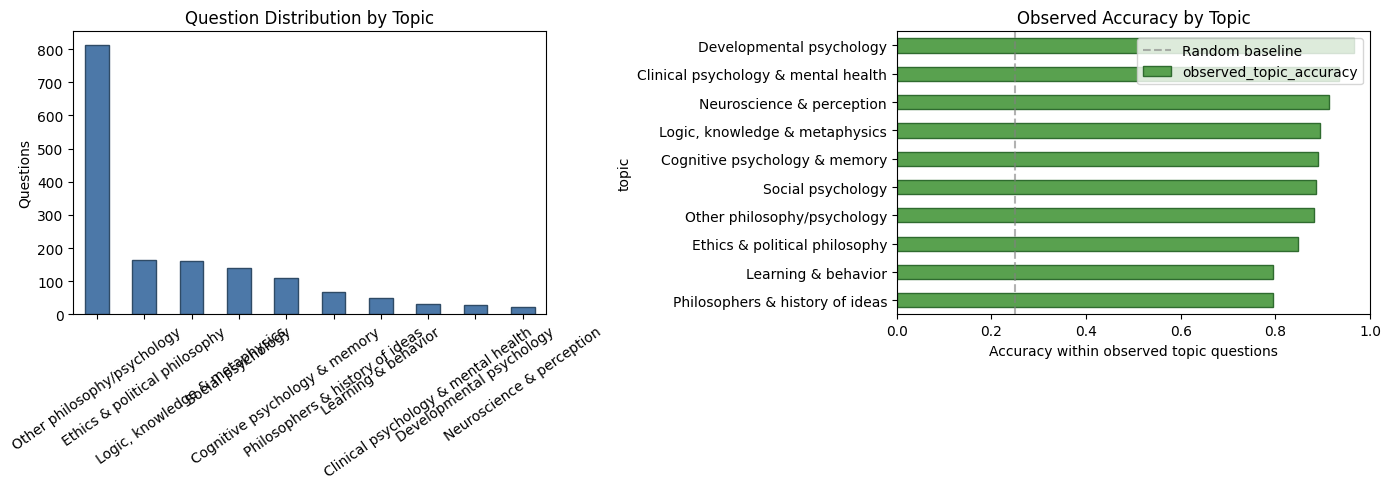

In [ ]:
def collect_available_question_logs():
    # Use canonical question-level logs only. Alias tables such as df_ensemble can duplicate df_phi_ensemble.
    log_names = [
        "df_all_prompts",
        "df_current_model_prompts",
        "df_phi_fixed_generation",
        "df_phi_forced_choice",
        "df_phi_ensemble",
        "df_qwen3b_prompts",
        "df_final_model",
        "df_deepseek_all_prompts",
        "df_gemma_prompts",
        "df_llama_prompts",
        "df_top3_model_ensemble",
        "df_phi_rag",
        "df_best_model_rag",
        "df_controlled_final",
    ]

    logs = []

    for log_name in log_names:
        if log_name not in globals() or not isinstance(globals()[log_name], pd.DataFrame):
            continue

        df_log = globals()[log_name].copy()

        if "question_text" not in df_log.columns or "correct" not in df_log.columns:
            continue

        df_log["source_table"] = log_name

        if "model_label" not in df_log.columns:
            df_log["model_label"] = log_name.replace("df_", "")

        if "prompt_type" not in df_log.columns:
            df_log["prompt_type"] = "unknown"

        if "run_id" not in df_log.columns:
            df_log["run_id"] = 1

        logs.append(df_log)

    if not logs:
        return pd.DataFrame()

    combined = pd.concat(logs, ignore_index=True, sort=False)
    combined = prepare_question_level_analysis(combined)

    dedupe_columns = [
        column for column in [
            "model_label",
            "system_name",
            "prompt_type",
            "run_id",
            "question_id",
            "selected_option_id",
            "raw_response",
        ]
        if column in combined.columns
    ]
    combined = combined.drop_duplicates(subset=dedupe_columns, keep="first")

    combined["run_key"] = (
        combined["model_label"].astype(str)
        + "|"
        + combined["system_name"].astype(str)
        + "|"
        + combined["prompt_type"].astype(str)
        + "|"
        + combined["run_id"].astype(str)
    )

    return combined


df_topic_analysis = collect_available_question_logs()

if df_topic_analysis.empty:
    print("No question-level logs are available yet. Run the model benchmark cells first, then rerun this cell.")
else:
    topic_distribution = df_topic_analysis["topic"].value_counts().rename_axis("topic").reset_index(name="questions")
    topic_accuracy = df_topic_analysis.groupby("topic").agg(
        questions=("question_id", "count"),
        correct_answers=("correct", "sum"),
        observed_topic_accuracy=("correct", "mean"),
        errors=("correct", lambda values: (~values).sum()),
    ).reset_index().sort_values("observed_topic_accuracy")

    topic_distribution.to_csv("philosophy_psychology_topic_distribution.csv", index=False)
    topic_accuracy.to_csv("philosophy_psychology_topic_accuracy.csv", index=False)

    display(topic_distribution)
    display(topic_accuracy)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    topic_distribution.plot(
        kind="bar",
        x="topic",
        y="questions",
        ax=axes[0],
        color="#4C78A8",
        edgecolor="#2F4B66",
        legend=False,
    )
    axes[0].set_title("Question Distribution by Topic")
    axes[0].set_xlabel("")
    axes[0].set_ylabel("Questions")
    axes[0].tick_params(axis="x", rotation=35)

    topic_accuracy.plot(
        kind="barh",
        x="topic",
        y="observed_topic_accuracy",
        ax=axes[1],
        color="#59A14F",
        edgecolor="#2F6B2F",
        legend=False,
    )
    axes[1].set_title("Observed Accuracy by Topic")
    axes[1].set_xlabel("Accuracy within observed topic questions")
    axes[1].set_xlim(0, 1)
    axes[1].axvline(0.25, linestyle="--", color="gray", alpha=0.6, label="Random baseline")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig("philosophy_psychology_topic_overview.png", dpi=150, bbox_inches="tight")
    plt.show()


### Topic-level conclusion

Across all saved runs, broad **Other philosophy/psychology** questions were the largest group and also produced many errors. More specific areas such as **cognitive psychology**, **learning and behavior**, **ethics**, and **logic** were often handled well by the strongest Phi, Qwen, Llama, or RAG configurations.

The best topic-level table shows that no single model dominated every area. Phi was strongest in several areas, including cognitive psychology and philosopher/history questions. Qwen 3B performed especially well on some clinical and social psychology questions. Static RAG was useful for broad mixed-topic questions and ethics.

In [ ]:
if df_topic_analysis.empty:
    print("Run the topic analysis collection cell first.")
else:
    model_topic_summary = df_topic_analysis.groupby(["model_label", "topic"]).agg(
        questions=("question_id", "count"),
        correct_answers=("correct", "sum"),
        errors=("correct", lambda values: (~values).sum()),
        observed_topic_accuracy=("correct", "mean"),
        average_level_seen=("level_before_answer", "mean"),
        mean_response_time=("response_time", "mean"),
        runs=("run_key", "nunique"),
    ).reset_index()
    model_topic_summary["game_accuracy_contribution"] = (
        model_topic_summary["correct_answers"] / (model_topic_summary["runs"].clip(lower=1) * MAX_GAME_QUESTIONS)
    )

    prompt_topic_summary = df_topic_analysis.groupby(["model_label", "prompt_type", "topic"]).agg(
        questions=("question_id", "count"),
        correct_answers=("correct", "sum"),
        errors=("correct", lambda values: (~values).sum()),
        observed_topic_accuracy=("correct", "mean"),
        average_level_seen=("level_before_answer", "mean"),
        runs=("run_key", "nunique"),
    ).reset_index()
    prompt_topic_summary["game_accuracy_contribution"] = (
        prompt_topic_summary["correct_answers"] / (prompt_topic_summary["runs"].clip(lower=1) * MAX_GAME_QUESTIONS)
    )

    min_questions_for_heatmap = 2
    topic_winners = (
        model_topic_summary[model_topic_summary["questions"] >= min_questions_for_heatmap]
        .sort_values(
            ["topic", "observed_topic_accuracy", "correct_answers", "questions", "mean_response_time"],
            ascending=[True, False, False, False, True],
        )
        .groupby("topic")
        .head(1)
        .reset_index(drop=True)
        .rename(
            columns={
                "model_label": "best_model",
                "observed_topic_accuracy": "mean_answer_accuracy",
                "average_level_seen": "mean_level_seen",
                "mean_response_time": "mean_time_seconds",
            }
        )
    )
    topic_winner_columns = [
        "topic",
        "best_model",
        "questions",
        "correct_answers",
        "mean_answer_accuracy",
        "mean_level_seen",
        "mean_time_seconds",
        "runs",
    ]
    topic_winners = topic_winners[
        [column for column in topic_winner_columns if column in topic_winners.columns]
    ]

    model_error_type_summary = df_topic_analysis.groupby(["model_label", "error_type"]).size().reset_index(name="count")
    prompt_error_type_summary = df_topic_analysis.groupby(["model_label", "prompt_type", "error_type"]).size().reset_index(name="count")

    model_topic_summary.to_csv("philosophy_psychology_model_topic_summary.csv", index=False)
    prompt_topic_summary.to_csv("philosophy_psychology_prompt_topic_summary.csv", index=False)
    topic_winners.to_csv("philosophy_psychology_best_model_by_topic.csv", index=False)
    model_error_type_summary.to_csv("philosophy_psychology_model_error_type_summary.csv", index=False)
    prompt_error_type_summary.to_csv("philosophy_psychology_prompt_error_type_summary.csv", index=False)

    print("Error types by model:")
    display(model_error_type_summary)
    print("Best observed model by topic:")
    display(topic_winners)
    display(prompt_topic_summary.sort_values(["topic", "observed_topic_accuracy"], ascending=[True, False]).head(30))


Error types by model:


,model_label,error_type,count
0,deepseek_r1_1_5b,Correct,25
1,deepseek_r1_1_5b,Invalid or unparseable output,5
2,deepseek_r1_1_5b,Plausible but incorrect answer,25
3,gemma_2_2b_it,Correct,192
4,gemma_2_2b_it,High-confidence wrong answer,24
5,gemma_2_2b_it,Plausible but incorrect answer,4
6,llama_3_8b_forced_choice,Correct,127
7,llama_3_8b_forced_choice,Plausible but incorrect answer,21
8,phi_3_5_mini_final_forced_choice,Correct,96
9,phi_3_5_mini_final_forced_choice,Plausible but incorrect answer,7


Best observed model by topic:


,topic,best_model,questions,correct_answers,mean_answer_accuracy,mean_level_seen,mean_time_seconds,runs
0,Clinical psychology & mental health,phi_best_model_psych_static_rag,8,8,1.000000,6.375000,1.418002,5
1,Cognitive psychology & memory,phi_3_5_mini_fixed_generation,9,9,1.000000,6.777778,0.406194,4
2,Developmental psychology,llama_3_8b_forced_choice,7,7,1.000000,7.142857,1.178971,5
3,Ethics & political philosophy,llama_3_8b_forced_choice,16,16,1.000000,6.812500,1.315099,9
4,Learning & behavior,qwen_1_5b,8,8,1.000000,6.000000,0.147673,5
5,"Logic, knowledge & metaphysics",phi_3_mini,23,23,1.000000,5.000000,0.455057,17
6,Neuroscience & perception,qwen_3b,6,6,1.000000,4.000000,0.208611,6
7,Other philosophy/psychology,phi_3_5_mini_prompt_ensemble,24,23,0.958333,5.708333,2.541357,4
8,Philosophers & history of ideas,phi_3_5_mini_fixed_generation,7,7,1.000000,10.000000,0.404434,4
9,Social psychology,phi_3_5_mini_fixed_generation,5,5,1.000000,11.200000,0.566044,3


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
39,gemma_2_2b_it,elimination,Clinical psychology & mental health,1,1,0,1.0,2.000000,1,0.066667
54,gemma_2_2b_it,psychology_expert,Clinical psychology & mental health,2,2,0,1.0,8.000000,2,0.066667
63,gemma_2_2b_it,psychology_short,Clinical psychology & mental health,1,1,0,1.0,4.000000,1,0.066667
84,llama_3_8b_forced_choice,few_shot_psychology,Clinical psychology & mental health,1,1,0,1.0,5.000000,1,0.066667
108,phi_3_5_mini_final_forced_choice,psychology_short,Clinical psychology & mental health,1,1,0,1.0,7.000000,1,0.066667
132,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,Clinical psychology & mental health,2,2,0,1.0,6.000000,1,0.133333
139,phi_3_mini,baseline,Clinical psychology & mental health,3,3,0,1.0,7.666667,2,0.100000
151,phi_3_mini,elimination,Clinical psychology & mental health,1,1,0,1.0,11.000000,1,0.066667
158,phi_3_mini,few_shot_psychology,Clinical psychology & mental health,1,1,0,1.0,1.000000,1,0.066667
184,phi_best_model_psych_static_rag,psych_static_baseline,Clinical psychology & mental health,1,1,0,1.0,5.000000,1,0.066667


# Final result story and controlled comparison

The final comparison shows that the strongest observed system is **Phi-3.5-mini with corrected fixed generation and the `psychology_short` prompt**. It reached **14.2 average questions**, a best run of **15**, **69 / 75 = 0.920 game accuracy**, valid-output rate **1.0**, and fast average response time around **0.44 seconds**.


In [ ]:
def collect_available_survival_summaries():
    summary_names = [
        "survival_summary_qwen_1_5b",
        "qwen_comparison_summary_sorted",
        "survival_summary_qwen3b",
        "survival_summary_best_qwen3b",
        "final_survival_summary",
        "survival_summary_current_model",
        "phi_fixed_generation_summary",
        "phi_forced_choice_summary",
        "phi_fixed_comparison",
        "phi_ensemble_summary_sorted",
        "survival_summary_ensemble",
        "survival_summary_deepseek_sorted",
        "gemma_survival_summary_sorted",
        "llama_survival_summary_sorted",
        "top3_model_ensemble_summary_sorted",
        "phi_rag_summary_sorted",
        "best_model_rag_summary_sorted",
        "controlled_final_summary",
    ]

    summaries = []

    for summary_name in summary_names:
        if summary_name in globals() and isinstance(globals()[summary_name], pd.DataFrame):
            summary = globals()[summary_name].copy()
            summary["summary_source"] = summary_name
            summaries.append(summary)

    if len(summaries) == 0:
        return pd.DataFrame()

    final_table = pd.concat(summaries, ignore_index=True, sort=False)

    if "model_label" not in final_table.columns:
        final_table["model_label"] = final_table["system_name"].str.replace(r"_[^_]+$", "", regex=True)

    final_table = final_table.drop_duplicates(
        subset=["model_label", "system_name", "prompt_type"],
        keep="first",
    )

    sort_columns = [
        column for column in [
            "average_questions_reached",
            "best_questions_reached",
            "average_final_earned_amount",
            "valid_output_rate",
        ]
        if column in final_table.columns
    ]

    if sort_columns:
        final_table = final_table.sort_values(by=sort_columns, ascending=False)

    preferred_columns = [
        "summary_source",
        "model_label",
        "model_type",
        "system_name",
        "prompt_type",
        "runs",
        "average_questions_reached",
        "best_questions_reached",
        "average_correct_answers",
        "total_correct_answers",
        "accuracy",
        "average_accuracy",
        "best_accuracy",
        "average_final_earned_amount",
        "best_final_earned_amount",
        "average_response_time",
        "max_response_time",
        "valid_output_rate",
    ]

    available_columns = [column for column in preferred_columns if column in final_table.columns]

    return final_table[available_columns]


final_result_story_table = collect_available_survival_summaries()
final_result_story_table.to_csv(
    "philosophy_psychology_final_result_story_table.csv",
    index=False,
)

final_result_story_table.head(30)


,summary_source,model_label,model_type,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,accuracy,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate
31,phi_fixed_generation_summary,phi_3_5_mini_fixed_generation,non-thinking,phi_3_5_mini_fixed_generation_psychology_short,psychology_short,5,14.2,15,13.8,69,0.92,0.92,1.0,665600.0,1024000,0.435922,0.809280,1.000000
59,phi_rag_summary_sorted,phi_best_model_psych_static_rag,rag,phi_best_model_psych_static_rag_psych_static_f...,psych_static_few_shot_psychology,5,13.0,15,12.4,62,0.826667,0.826667,1.0,538000.0,1024000,1.622264,1.938405,1.000000
25,survival_summary_current_model,phi_3_mini,NaN,phi_3_mini_baseline,baseline,5,12.6,15,12.0,60,0.8,0.8,1.0,525000.0,1024000,0.404949,0.893696,1.000000
29,survival_summary_current_model,phi_3_mini,NaN,phi_3_mini_psychology_expert,psychology_expert,5,11.4,15,11.0,55,0.733333,0.733333,1.0,615260.0,1024000,0.487452,1.198305,1.000000
60,phi_rag_summary_sorted,phi_best_model_psych_static_rag,rag,phi_best_model_psych_static_rag_psych_static_b...,psych_static_baseline,5,10.4,15,10.0,50,0.666667,0.666667,1.0,614600.0,1024000,1.076137,1.305837,1.000000
27,survival_summary_current_model,phi_3_mini,NaN,phi_3_mini_elimination,elimination,5,10.4,15,9.6,48,0.64,0.64,1.0,281860.0,1024000,0.416466,0.507190,1.000000
24,final_survival_summary,phi_3_5_mini_final_forced_choice,non-thinking,phi_3_5_mini_final_forced_choice_psychology_short,psychology_short,10,10.3,15,9.6,96,0.64,0.64,1.0,368930.0,1024000,0.393419,0.527117,1.000000
6,qwen_comparison_summary_sorted,qwen_3b,non-thinking,qwen_3b_few_shot_psychology,few_shot_psychology,5,10.2,15,9.6,48,0.64,0.64,1.0,422560.0,1024000,0.274265,0.315287,1.000000
54,llama_survival_summary_sorted,llama_3_8b_forced_choice,non-thinking,llama_3_8b_forced_choice_psychology_short,psychology_short,5,10.0,15,9.2,46,0.613333,0.613333,1.0,231240.0,1024000,1.108579,2.883907,1.000000
7,qwen_comparison_summary_sorted,qwen_3b,non-thinking,qwen_3b_baseline,baseline,5,10.0,15,9.2,46,0.613333,0.613333,1.0,216100.0,1024000,0.188246,0.402841,1.000000


In [ ]:
if len(final_result_story_table) > 0:
    winner = final_result_story_table.iloc[0]
    print("Best observed system:")
    print("System:", winner.get("system_name"))
    print("Prompt:", winner.get("prompt_type"))
    print("Average questions reached:", winner.get("average_questions_reached"))
    print("Best questions reached:", winner.get("best_questions_reached"))
    print("Average final earned amount:", winner.get("average_final_earned_amount"))
    print("Valid output rate:", winner.get("valid_output_rate"))
else:
    print("No summary tables are available yet. Run the benchmark sections first.")


Best observed system:
System: phi_3_5_mini_fixed_generation_psychology_short
Prompt: psychology_short
Average questions reached: 14.2
Best questions reached: 15
Average final earned amount: 665600.0
Valid output rate: 1.0


# Best-three model ensemble

This ensemble tests whether combining the strongest model families improves performance beyond the best single model. The selected candidates were based on the previous survival tables, while avoiding multiple variants of the same architecture.

In this runtime, the ensemble was exploratory rather than final. It only completed one logged question in the saved output, so it should not be used as the main result. The final report should focus on the stronger and more stable individual systems, especially the fixed-generation Phi model and the best static RAG comparison.

In [ ]:
TOP3_MODEL_CANDIDATE_POOL = [
    {
        "family": "phi",
        "model_key": "phi_3_5_mini",
        "summary_pattern": "phi_3_5_mini",
        "model_id": "microsoft/Phi-3.5-mini-instruct",
        "model_label": "phi_3_5_mini_top3_forced_choice",
        "prompt_type": "psychology_short",
        "loader": "phi",
        "answer_fn": generate_answer_phi_scored,
    },
    {
        "family": "qwen_1_5b",
        "model_key": "qwen_1_5b",
        "summary_pattern": "qwen_1_5b",
        "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
        "model_label": "qwen_1_5b_top3",
        "prompt_type": "psychology_short",
        "use_4bit": False,
        "answer_fn": generate_answer_chat_template,
    },
    {
        "family": "qwen_3b",
        "model_key": "qwen_3b",
        "summary_pattern": "qwen_3b",
        "model_id": "Qwen/Qwen2.5-3B-Instruct",
        "model_label": "qwen_3b_top3",
        "prompt_type": "psychology_expert",
        "use_4bit": False,
        "answer_fn": generate_answer_chat_template_with_confidence,
    },
    {
        "family": "deepseek",
        "model_key": "deepseek_r1_1_5b",
        "summary_pattern": "deepseek",
        "model_id": "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
        "model_label": "deepseek_r1_1_5b_top3",
        "prompt_type": "psychology_short",
        "loader": "deepseek",
        "answer_fn": generate_answer_thinking,
    },
    {
        "family": "gemma",
        "model_key": "gemma_2_2b_it",
        "summary_pattern": "gemma",
        "model_id": "google/gemma-2-2b-it",
        "model_label": "gemma_2_2b_top3",
        "prompt_type": "psychology_short",
        "use_4bit": False,
        "answer_fn": generate_answer_chat_template,
    },
    {
        "family": "llama",
        "model_key": "llama_3_8b",
        "summary_pattern": "llama",
        "model_id": "meta-llama/Meta-Llama-3-8B",
        "model_label": "llama_3_8b_top3",
        "prompt_type": "psychology_short",
        "use_4bit": True,
        "answer_fn": generate_answer_scored_options,
    },
]


def load_deepseek_distill_model():
    global model, tokenizer, generator, model_name, current_model_label

    clear_loaded_model()
    model_name = "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B"
    current_model_label = "deepseek_r1_1_5b_top3"

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        device_map="auto",
        torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    )
    generator = make_text_generation_wrapper(model, tokenizer)

    if hasattr(model, "generation_config"):
        model.generation_config.max_length = None

    print("Loaded top-three DeepSeek model:", model_name)


def is_base_architecture_candidate_row(row):
    row_text = " ".join(
        str(row.get(column, ""))
        for column in ["summary_source", "model_label", "system_name", "prompt_type"]
    ).lower()
    return not any(blocked in row_text for blocked in ["ensemble", "rag", "top3", "controlled"])


def supported_candidate_from_summary_row(row):
    model_label = str(row.get("model_label", ""))
    prompt_type = str(row.get("prompt_type", "psychology_short"))
    score = row.get("average_questions_reached")
    best_score = row.get("best_questions_reached")
    valid_rate = row.get("valid_output_rate")
    row_text = " ".join(
        str(row.get(column, ""))
        for column in ["summary_source", "model_label", "system_name", "prompt_type"]
    ).lower()

    if not is_base_architecture_candidate_row(row):
        return None

    if "phi_3_5" in row_text:
        return {
            "family": "phi",
            "model_key": "phi_3_5_mini",
            "model_id": "microsoft/Phi-3.5-mini-instruct",
            "model_label": f"phi_3_5_mini_top3_{prompt_type}",
            "prompt_type": prompt_type,
            "loader": "phi",
            "answer_fn": generate_answer_phi_scored,
            "observed_average_questions_reached": score,
            "observed_best_questions_reached": best_score,
            "observed_valid_output_rate": valid_rate,
        }

    if "qwen_1_5b" in row_text or "qwen2.5-1.5b" in row_text:
        return {
            "family": "qwen_1_5b",
            "model_key": "qwen_1_5b",
            "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
            "model_label": f"qwen_1_5b_top3_{prompt_type}",
            "prompt_type": prompt_type,
            "use_4bit": False,
            "answer_fn": generate_answer_chat_template,
            "observed_average_questions_reached": score,
            "observed_best_questions_reached": best_score,
            "observed_valid_output_rate": valid_rate,
        }

    if "qwen_3b" in row_text or "qwen_3_b" in row_text or "qwen2.5-3b" in row_text:
        return {
            "family": "qwen_3b",
            "model_key": "qwen_3b",
            "model_id": "Qwen/Qwen2.5-3B-Instruct",
            "model_label": f"qwen_3b_top3_{prompt_type}",
            "prompt_type": prompt_type,
            "use_4bit": False,
            "answer_fn": generate_answer_chat_template_with_confidence,
            "observed_average_questions_reached": score,
            "observed_best_questions_reached": best_score,
            "observed_valid_output_rate": valid_rate,
        }

    if "deepseek" in row_text:
        return {
            "family": "deepseek",
            "model_key": "deepseek_r1_1_5b",
            "model_id": "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
            "model_label": f"deepseek_r1_1_5b_top3_{prompt_type}",
            "prompt_type": prompt_type,
            "loader": "deepseek",
            "answer_fn": generate_answer_thinking,
            "observed_average_questions_reached": score,
            "observed_best_questions_reached": best_score,
            "observed_valid_output_rate": valid_rate,
        }

    if "gemma" in row_text and not globals().get("RUN_GEMMA", False):
        return None

    if "gemma" in row_text:
        return {
            "family": "gemma",
            "model_key": "gemma_2_2b_it",
            "model_id": "google/gemma-2-2b-it",
            "model_label": f"gemma_2_2b_top3_{prompt_type}",
            "prompt_type": prompt_type,
            "use_4bit": False,
            "answer_fn": generate_answer_chat_template,
            "observed_average_questions_reached": score,
            "observed_best_questions_reached": best_score,
            "observed_valid_output_rate": valid_rate,
        }

    if "llama" in row_text:
        return {
            "family": "llama",
            "model_key": "llama_3_8b",
            "model_id": "meta-llama/Meta-Llama-3-8B",
            "model_label": f"llama_3_8b_top3_{prompt_type}",
            "prompt_type": prompt_type,
            "use_4bit": True,
            "answer_fn": generate_answer_scored_options,
            "observed_average_questions_reached": score,
            "observed_best_questions_reached": best_score,
            "observed_valid_output_rate": valid_rate,
        }

    return None


def select_best_three_model_candidates(summary_table=None):
    if summary_table is None or summary_table.empty:
        summary_table = collect_available_survival_summaries() if "collect_available_survival_summaries" in globals() else pd.DataFrame()

    observed_candidates = []

    if summary_table is not None and not summary_table.empty:
        table = summary_table.copy()
        for column in ["average_questions_reached", "best_questions_reached", "valid_output_rate"]:
            if column not in table.columns:
                table[column] = 0
            table[column] = pd.to_numeric(table[column], errors="coerce").fillna(0)

        ranked_rows = table.sort_values(
            ["average_questions_reached", "best_questions_reached", "valid_output_rate"],
            ascending=False,
        )

        for _, row in ranked_rows.iterrows():
            candidate = supported_candidate_from_summary_row(row)
            if candidate is not None:
                observed_candidates.append(candidate)

    selected = []
    used_families = set()

    for candidate in observed_candidates:
        if candidate["family"] in used_families:
            continue
        selected.append(candidate)
        used_families.add(candidate["family"])
        if len(selected) == 3:
            return selected

    for candidate in TOP3_MODEL_CANDIDATE_POOL:
        if candidate["family"] == "gemma" and not globals().get("RUN_GEMMA", False):
            continue
        if candidate["family"] in used_families:
            continue
        candidate_copy = candidate.copy()
        candidate_copy["observed_average_questions_reached"] = candidate_copy.get("observed_average_questions_reached", -1)
        candidate_copy["observed_best_questions_reached"] = candidate_copy.get("observed_best_questions_reached", -1)
        candidate_copy["observed_valid_output_rate"] = candidate_copy.get("observed_valid_output_rate", -1)
        selected.append(candidate_copy)
        used_families.add(candidate["family"])
        if len(selected) == 3:
            break

    return selected


active_top3_model_key = None


def load_top3_candidate(candidate):
    global active_top3_model_key

    if active_top3_model_key == candidate["model_key"]:
        return

    if candidate.get("loader") == "phi":
        load_phi_model()
    elif candidate.get("loader") == "deepseek":
        load_deepseek_distill_model()
    else:
        load_chat_model(
            model_id=candidate["model_id"],
            model_label=candidate["model_label"],
            use_4bit=candidate.get("use_4bit", False),
        )

    active_top3_model_key = candidate["model_key"]


TOP3_ENSEMBLE_CONFIDENCE_GATE = 0.62
TOP3_ENSEMBLE_SOFT_SUPPORT_WEIGHT = 0.35


def candidate_observed_weight(candidate):
    """Weight stronger observed model configurations more heavily."""
    observed_average = pd.to_numeric(candidate.get("observed_average_questions_reached"), errors="coerce")
    valid_rate = pd.to_numeric(candidate.get("observed_valid_output_rate"), errors="coerce")

    if pd.isna(observed_average):
        observed_average = 3.0
    if pd.isna(valid_rate) or valid_rate <= 0:
        valid_rate = 1.0

    return float(np.clip(0.50 + observed_average / 5.0, 0.50, 3.50) * np.clip(valid_rate, 0.25, 1.0))


def prediction_confidence_for_ensemble(prediction):
    confidence = pd.to_numeric(prediction.get("confidence_score"), errors="coerce")
    if pd.notna(confidence):
        return float(np.clip(confidence, 0.0, 1.0))

    option_scores = parse_option_score_payload(prediction.get("option_confidences"))
    probabilities = scores_to_probabilities(option_scores)
    if probabilities:
        return float(max(probabilities.values()))

    return 0.50


def prediction_scores_for_ensemble(prediction, candidate, valid_option_ids):
    """Create calibrated ensemble support from a model prediction.

    The earlier ensemble added raw probability distributions directly. That can
    be unstable because each model's confidence scale is different. This version
    uses mostly a weighted vote for the predicted option and only a smaller soft
    support term from probabilities.
    """
    candidate_weight = candidate_observed_weight(candidate)
    predicted_id = prediction.get("predicted_id")
    option_scores = parse_option_score_payload(prediction.get("option_confidences"))
    probabilities = scores_to_probabilities(option_scores)

    support = {int(option_id): 0.0 for option_id in valid_option_ids}

    if predicted_id is None and probabilities:
        predicted_id = max(probabilities, key=probabilities.get)

    if probabilities:
        for option_id, probability in probabilities.items():
            if int(option_id) in support:
                support[int(option_id)] += TOP3_ENSEMBLE_SOFT_SUPPORT_WEIGHT * candidate_weight * float(probability)

    if predicted_id is not None and int(predicted_id) in support:
        confidence = prediction_confidence_for_ensemble(prediction)
        support[int(predicted_id)] += candidate_weight * (0.65 + 0.35 * confidence)

    return support


def format_ensemble_prediction(candidate, prediction):
    return {
        "model_label": candidate["model_label"],
        "prompt_type": candidate["prompt_type"],
        "predicted_id": prediction.get("predicted_id"),
        "confidence_score": prediction_confidence_for_ensemble(prediction),
        "candidate_weight": candidate_observed_weight(candidate),
        "raw_response": prediction.get("raw_response"),
        "observed_average_questions_reached": candidate.get("observed_average_questions_reached"),
    }


def generate_answer_top3_model_ensemble(question, prompt_type="top3_model_ensemble"):
    candidates = globals().get("top3_model_ensemble_candidates")

    if not candidates:
        candidates = select_best_three_model_candidates()

    valid_option_ids = [int(option.id) for option in question.options]
    predictions = []
    combined_scores = {option_id: 0.0 for option_id in valid_option_ids}
    total_response_time = 0.0
    decision_mode = "weighted_vote"

    primary_candidate = candidates[0]
    load_top3_candidate(primary_candidate)
    primary_prediction = primary_candidate["answer_fn"](question, prompt_type=primary_candidate["prompt_type"])
    total_response_time += primary_prediction["response_time"]
    predictions.append(format_ensemble_prediction(primary_candidate, primary_prediction))

    primary_confidence = prediction_confidence_for_ensemble(primary_prediction)
    primary_predicted_id = primary_prediction.get("predicted_id")

    if primary_predicted_id is not None and primary_confidence >= TOP3_ENSEMBLE_CONFIDENCE_GATE:
        predicted_id = int(primary_predicted_id)
        combined_scores[predicted_id] = 1.0
        confidence_score = primary_confidence
        confidence_margin = primary_confidence
        decision_mode = "primary_high_confidence"
    else:
        for option_id, score in prediction_scores_for_ensemble(primary_prediction, primary_candidate, valid_option_ids).items():
            combined_scores[int(option_id)] = combined_scores.get(int(option_id), 0.0) + float(score)

        for candidate in candidates[1:]:
            load_top3_candidate(candidate)
            prediction = candidate["answer_fn"](question, prompt_type=candidate["prompt_type"])
            total_response_time += prediction["response_time"]
            predictions.append(format_ensemble_prediction(candidate, prediction))

            for option_id, score in prediction_scores_for_ensemble(prediction, candidate, valid_option_ids).items():
                combined_scores[int(option_id)] = combined_scores.get(int(option_id), 0.0) + float(score)

        predicted_id = max(combined_scores, key=combined_scores.get) if combined_scores else None
        confidence_score, confidence_margin = confidence_margin_from_scores(combined_scores, predicted_id)

    return {
        "prompt_type": prompt_type,
        "prompt": "Adaptive top-three ensemble: high-confidence primary answer, otherwise weighted cross-model vote.",
        "raw_response": json.dumps(
            {
                "decision_mode": decision_mode,
                "confidence_gate": TOP3_ENSEMBLE_CONFIDENCE_GATE,
                "selected_candidates": [
                    {
                        "model_label": candidate["model_label"],
                        "prompt_type": candidate["prompt_type"],
                        "observed_average_questions_reached": candidate.get("observed_average_questions_reached"),
                        "observed_best_questions_reached": candidate.get("observed_best_questions_reached"),
                        "candidate_weight": candidate_observed_weight(candidate),
                    }
                    for candidate in candidates
                ],
                "predictions": predictions,
                "combined_scores": combined_scores,
            },
            ensure_ascii=False,
        ),
        "predicted_id": predicted_id,
        "response_time": total_response_time,
        "option_confidences": combined_scores,
        "confidence_score": confidence_score,
        "confidence_margin": confidence_margin,
    }


,family,model_label,prompt_type,observed_average_questions_reached,observed_best_questions_reached,observed_valid_output_rate
0,phi,phi_3_5_mini_top3_psychology_short,psychology_short,14.2,15,1.0
1,qwen_3b,qwen_3b_top3_few_shot_psychology,few_shot_psychology,10.2,15,1.0
2,llama,llama_3_8b_top3_psychology_short,psychology_short,10.0,15,1.0



Running model=top3_model_ensemble, prompt=top3_model_ensemble, run 1/5
Started game session: 241702
System: top3_model_ensemble_top3_model_ensemble


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded fixed Phi model: microsoft/Phi-3.5-mini-instruct


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

...

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded model: Qwen/Qwen2.5-3B-Instruct
Model label: qwen_3b_top3_few_shot_psychology
4-bit loading: False
dtype: torch.float16


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Loaded model: meta-llama/Meta-Llama-3-8B
Model label: llama_3_8b_top3_psychology_short
4-bit loading: True
dtype: torch.float16

Level 1
Question: Which of the following best describes the phenomenon of synesthesia?
Raw response: {"decision_mode": "weighted_vote", "confidence_gate": 0.62, "selected_candidates": [{"model_label": "phi_3_5_mini_top3_psychology_short", "prompt_type": "psychology_short", "observed_average_questions_reached": 14.2, "observed_best_questions_reached": 15, "candidate_weight": 3.34}, {"model_label": "qwen_3b_top3_few_shot_psychology", "prompt_type": "few_shot_psychology", "observed_average_questions_reached": 10.2, "observed_best_questions_reached": 15, "candidate_weight": 2.54}, {"model_label": "llama_3_8b_top3_psychology_short", "prompt_type": "psychology_short", "observed_average_questions_reached": 10.0, "observed_best_questions_reached": 15, "candidate_weight": 2.5}], "predictions": [{"model_label": "phi_3_5_mini_top3_psychology_short", "prompt_type": "psyc

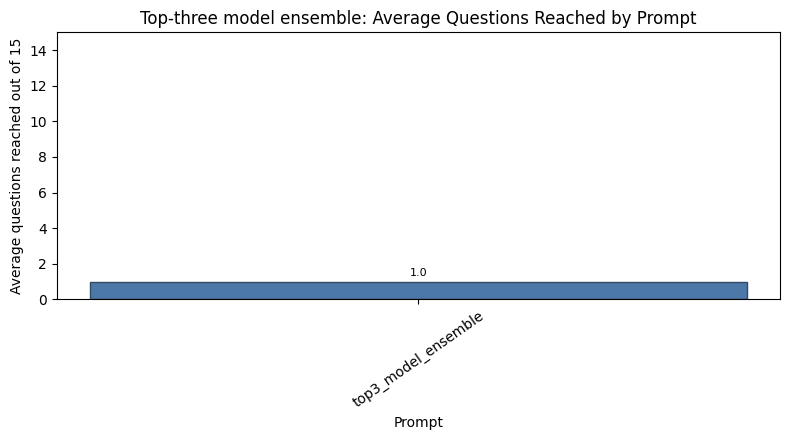

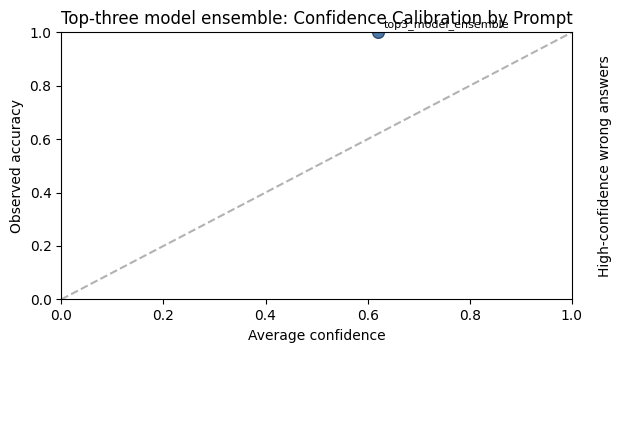

Top-three model ensemble: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,top3_model_ensemble,top3_model_ensemble_top3_model_ensemble,top3_model_ensemble,1,1.0,1,1.0,1,0.066667,0.066667,100.0,100,0.338394,0.338394,1.0,0.066667,ensemble


Top-three model ensemble: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
0,top3_model_ensemble,top3_model_ensemble,Other philosophy/psychology,1,1,0,1.0,1.0,1,0.066667


,model_label,prompt_type,error_type,count
0,top3_model_ensemble,top3_model_ensemble,Correct,1


...

,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate
0,top3_model_ensemble,top3_model_ensemble,1,1,1.0


Top-three model ensemble: confidence and overconfidence


,model_label,prompt_type,confidence_bucket,questions,observed_accuracy,average_confidence,average_margin,overconfident_errors
0,top3_model_ensemble,top3_model_ensemble,low (<= 0.40),0,NaN,NaN,NaN,0
1,top3_model_ensemble,top3_model_ensemble,medium (0.40-0.70),1,1.0,0.62101,0.62101,0
2,top3_model_ensemble,top3_model_ensemble,high (>= 0.70),0,NaN,NaN,NaN,0


,model_label,prompt_type,system_name,run_id,level_before_answer,topic,question_text,selected_option_text,raw_response,confidence_score,confidence_margin,option_confidences,correct


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,top3_model_ensemble,top3_model_ensemble_top3_model_ensemble,top3_model_ensemble,5,1.2,2,0.2,1,0.013333,0.066667,20.0,100,1.419718,1.906278,1.0,0.013333,ensemble


In [ ]:
RUN_TOP3_MODEL_ENSEMBLE = True
TOP3_MODEL_ENSEMBLE_RUNS = 5

final_result_story_table = collect_available_survival_summaries()
top3_model_ensemble_candidates = select_best_three_model_candidates(final_result_story_table)
top3_candidate_table = pd.DataFrame(top3_model_ensemble_candidates)

display_columns = [
    "family",
    "model_label",
    "prompt_type",
    "observed_average_questions_reached",
    "observed_best_questions_reached",
    "observed_valid_output_rate",
]
display(top3_candidate_table[[column for column in display_columns if column in top3_candidate_table.columns]])

if RUN_TOP3_MODEL_ENSEMBLE:
    df_top3_model_ensemble = benchmark_answer_fn(
        answer_fn=generate_answer_top3_model_ensemble,
        model_label="top3_model_ensemble",
        prompt_type="top3_model_ensemble",
        n_runs=TOP3_MODEL_ENSEMBLE_RUNS,
        delay_seconds=1.5,
    )

    top3_model_ensemble_summary = make_survival_summary(df_top3_model_ensemble, model_type="ensemble")
    top3_model_ensemble_summary_sorted = sort_survival_summary(top3_model_ensemble_summary)

    df_top3_model_ensemble.to_csv("philosophy_psychology_top3_model_ensemble_results.csv", index=False)
    top3_model_ensemble_summary_sorted.to_csv("philosophy_psychology_top3_model_ensemble_summary.csv", index=False)

    top3_model_ensemble_analysis = analyse_model_runs(
        df_top3_model_ensemble,
        model_tag="Top-three model ensemble",
        output_prefix="philosophy_psychology_top3_model_ensemble",
        model_type="ensemble",
    )

    final_result_story_table = collect_available_survival_summaries()
    display(top3_model_ensemble_summary_sorted)
else:
    print("Top-three model ensemble is disabled. Set RUN_TOP3_MODEL_ENSEMBLE = True when you are ready.")


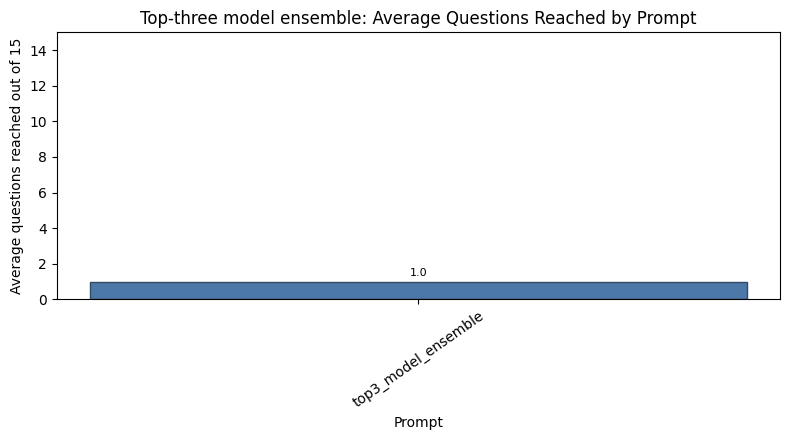

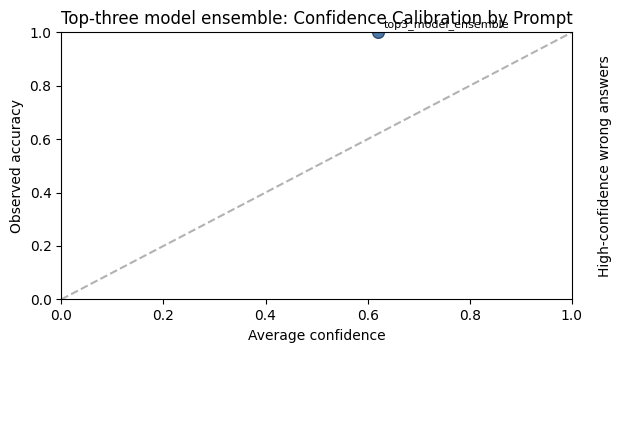

Top-three model ensemble: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,top3_model_ensemble,top3_model_ensemble_top3_model_ensemble,top3_model_ensemble,1,1.0,1,1.0,1,0.066667,0.066667,100.0,100,0.338394,0.338394,1.0,0.066667,ensemble


Top-three model ensemble: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
0,top3_model_ensemble,top3_model_ensemble,Other philosophy/psychology,1,1,0,1.0,1.0,1,0.066667


,model_label,prompt_type,error_type,count
0,top3_model_ensemble,top3_model_ensemble,Correct,1


...

,model_label,prompt_type,error_type,count
1,deepseek_r1_1_5b,baseline,Plausible but incorrect answer,5
0,deepseek_r1_1_5b,baseline,Correct,1
4,deepseek_r1_1_5b,chain_of_thought,Plausible but incorrect answer,4
2,deepseek_r1_1_5b,chain_of_thought,Correct,2
3,deepseek_r1_1_5b,chain_of_thought,Invalid or unparseable output,1
...,...,...,...,...
102,qwen_3b,psychology_expert,Plausible but incorrect answer,1
103,qwen_3b,psychology_short,Correct,36
104,qwen_3b,psychology_short,High-confidence wrong answer,4
105,qwen_3b,psychology_short,Plausible but incorrect answer,1


Topic performance for every model and prompt


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,mean_answer_correct,mean_response_time,max_response_time,runs,game_accuracy_contribution
39,gemma_2_2b_it,elimination,Clinical psychology & mental health,1,1,0,1.000000,2.000000,1.000000,0.449577,0.449577,1,0.066667
54,gemma_2_2b_it,psychology_expert,Clinical psychology & mental health,2,2,0,1.000000,8.000000,1.000000,0.322056,0.329141,2,0.066667
63,gemma_2_2b_it,psychology_short,Clinical psychology & mental health,1,1,0,1.000000,4.000000,1.000000,0.334850,0.334850,1,0.066667
84,llama_3_8b_forced_choice,few_shot_psychology,Clinical psychology & mental health,1,1,0,1.000000,5.000000,1.000000,1.724790,1.724790,1,0.066667
108,phi_3_5_mini_final_forced_choice,psychology_short,Clinical psychology & mental health,1,1,0,1.000000,7.000000,1.000000,0.428345,0.428345,1,0.066667
...,...,...,...,...,...,...,...,...,...,...,...,...,...
131,phi_3_5_mini_forced_choice,psychology_short,Social psychology,3,2,1,0.666667,3.333333,0.666667,0.449008,0.514781,2,0.066667
264,qwen_1_5b,psychology_expert,Social psychology,3,2,1,0.666667,2.000000,0.666667,0.145708,0.163799,3,0.044444
138,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,Social psychology,4,2,2,0.500000,7.000000,0.500000,2.470950,2.699924,3,0.044444
247,qwen_1_5b,elimination,Social psychology,2,1,1,0.500000,3.500000,0.500000,0.168863,0.182856,2,0.033333


Best observed model/prompt by topic


,topic,best_model,best_prompt,questions,correct_answers,mean_answer_accuracy,mean_level_seen,mean_time_seconds,runs,game_accuracy_contribution
0,Clinical psychology & mental health,qwen_3b,few_shot_psychology,3,3,1.0,6.666667,0.275901,2,0.100000
1,Cognitive psychology & memory,phi_3_5_mini_fixed_generation,psychology_short,9,9,1.0,6.777778,0.406194,4,0.150000
2,Developmental psychology,phi_3_mini,psychology_expert,4,4,1.0,8.500000,0.480163,3,0.088889
3,Ethics & political philosophy,phi_best_model_psych_static_rag,psych_static_baseline,10,10,1.0,7.000000,1.136827,4,0.166667
4,Learning & behavior,phi_3_5_mini_final_forced_choice,psychology_short,4,4,1.0,3.750000,0.398975,4,0.066667
5,"Logic, knowledge & metaphysics",phi_3_5_mini_final_forced_choice,psychology_short,12,12,1.0,7.666667,0.419597,6,0.133333
6,Neuroscience & perception,phi_best_model_psych_static_rag,psych_static_chain_of_thought,3,3,1.0,10.333333,1.221528,2,0.100000
7,Other philosophy/psychology,phi_best_model_psych_static_rag,psych_static_few_shot_psychology,27,27,1.0,6.851852,1.524674,5,0.360000
8,Philosophers & history of ideas,phi_3_5_mini_fixed_generation,psychology_short,7,7,1.0,10.000000,0.404434,4,0.116667
9,Social psychology,qwen_3b,few_shot_psychology,6,6,1.0,8.666667,0.273589,3,0.133333


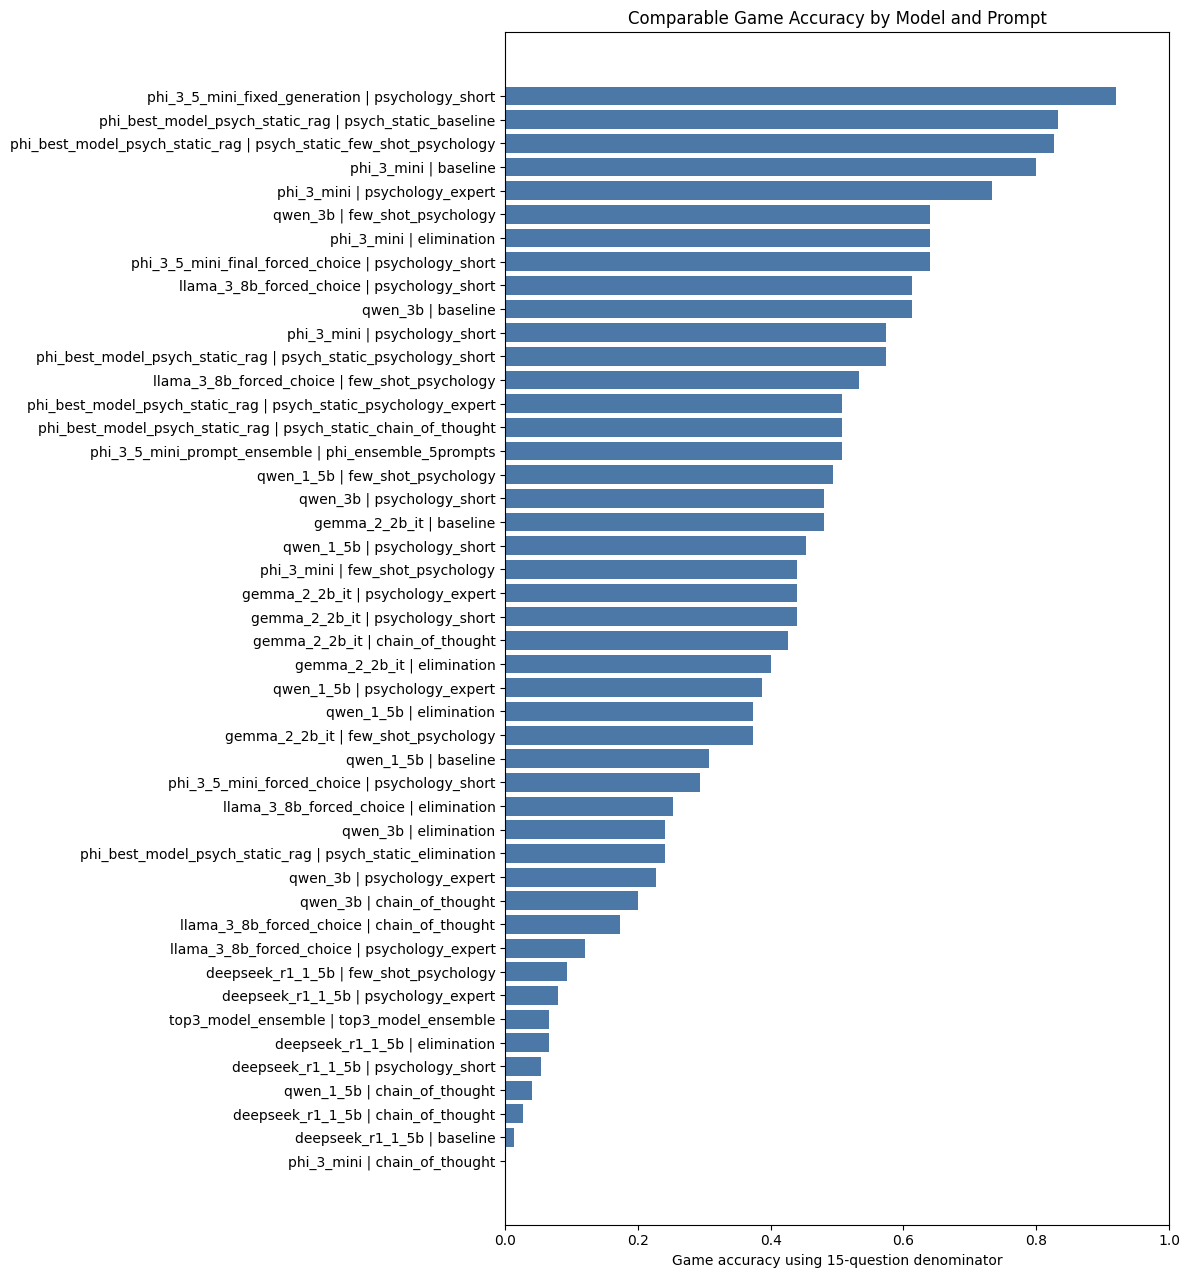

In [ ]:
if "df_top3_model_ensemble" in globals() and isinstance(df_top3_model_ensemble, pd.DataFrame) and not df_top3_model_ensemble.empty:
    top3_model_ensemble_analysis = analyse_model_runs(
        df_top3_model_ensemble,
        model_tag="Top-three model ensemble",
        output_prefix="philosophy_psychology_top3_model_ensemble",
        model_type="ensemble",
    )

df_topic_analysis = collect_available_question_logs()

if df_topic_analysis.empty:
    print("No logs available yet. Run the model benchmark cells first, then rerun this cell.")
else:
    df_topic_analysis["model_prompt"] = (
        df_topic_analysis["model_label"].astype(str)
        + " | "
        + df_topic_analysis["prompt_type"].astype(str)
    )
    df_topic_analysis["correct"] = df_topic_analysis["correct"].astype(bool)

    run_counts = df_topic_analysis.groupby(["model_label", "prompt_type"])["run_key"].nunique().reset_index(name="runs")

    all_model_prompt_question_summary = df_topic_analysis.groupby(["model_label", "prompt_type"]).agg(
        questions_seen=("question_id", "count"),
        correct_answers=("correct", "sum"),
        errors=("correct", lambda values: (~values).sum()),
        valid_output_rate=("valid_output", "mean"),
        average_response_time=("response_time", "mean"),
        max_response_time=("response_time", "max"),
        average_confidence=("confidence_score", "mean") if "confidence_score" in df_topic_analysis.columns else ("correct", "mean"),
    ).reset_index()

    all_model_prompt_question_summary = all_model_prompt_question_summary.merge(
        run_counts,
        on=["model_label", "prompt_type"],
        how="left",
    )
    all_model_prompt_question_summary["accuracy_denominator"] = (
        all_model_prompt_question_summary["runs"].clip(lower=1) * MAX_GAME_QUESTIONS
    )
    all_model_prompt_question_summary["accuracy"] = (
        all_model_prompt_question_summary["correct_answers"]
        / all_model_prompt_question_summary["accuracy_denominator"]
    )
    all_model_prompt_question_summary["game_accuracy_out_of_15"] = all_model_prompt_question_summary["accuracy"]

    if "confidence_score" in df_topic_analysis.columns:
        confidence_by_correctness = df_topic_analysis.groupby(["model_label", "prompt_type", "correct"])["confidence_score"].mean().reset_index()
        confidence_pivot = confidence_by_correctness.pivot_table(
            index=["model_label", "prompt_type"],
            columns="correct",
            values="confidence_score",
        ).reset_index().rename(columns={False: "average_confidence_when_wrong", True: "average_confidence_when_correct"})
        all_model_prompt_question_summary = all_model_prompt_question_summary.merge(
            confidence_pivot,
            on=["model_label", "prompt_type"],
            how="left",
        )
        overconfident_wrong = df_topic_analysis.assign(
            overconfident_wrong=(~df_topic_analysis["correct"]) & (pd.to_numeric(df_topic_analysis["confidence_score"], errors="coerce") >= 0.60)
        ).groupby(["model_label", "prompt_type"])["overconfident_wrong"].sum().reset_index(name="overconfident_wrong_count")
        all_model_prompt_question_summary = all_model_prompt_question_summary.merge(
            overconfident_wrong,
            on=["model_label", "prompt_type"],
            how="left",
        )
    else:
        all_model_prompt_question_summary["average_confidence_when_wrong"] = np.nan
        all_model_prompt_question_summary["average_confidence_when_correct"] = np.nan
        all_model_prompt_question_summary["overconfident_wrong_count"] = np.nan

    all_model_prompt_survival = make_survival_summary(df_topic_analysis)
    survival_columns = [
        "model_label",
        "prompt_type",
        "average_questions_reached",
        "best_questions_reached",
        "average_final_earned_amount",
        "best_final_earned_amount",
    ]
    all_model_prompt_question_summary = all_model_prompt_question_summary.merge(
        all_model_prompt_survival[[column for column in survival_columns if column in all_model_prompt_survival.columns]],
        on=["model_label", "prompt_type"],
        how="left",
    )

    all_model_prompt_question_summary = all_model_prompt_question_summary.sort_values(
        by=["average_questions_reached", "game_accuracy_out_of_15", "valid_output_rate"],
        ascending=False,
    ).reset_index(drop=True)
    all_model_prompt_question_summary.insert(0, "rank", range(1, len(all_model_prompt_question_summary) + 1))

    all_model_error_type_summary = df_topic_analysis.groupby(["model_label", "prompt_type", "error_type"]).size().reset_index(name="count")
    all_model_topic_summary = df_topic_analysis.groupby(["model_label", "prompt_type", "topic"]).agg(
        questions=("question_id", "count"),
        correct_answers=("correct", "sum"),
        errors=("correct", lambda values: (~values).sum()),
        observed_topic_accuracy=("correct", "mean"),
        average_level_seen=("level_before_answer", "mean"),
        mean_answer_correct=("correct", "mean"),
        mean_response_time=("response_time", "mean"),
        max_response_time=("response_time", "max"),
        runs=("run_key", "nunique"),
    ).reset_index()
    all_model_topic_summary["game_accuracy_contribution"] = (
        all_model_topic_summary["correct_answers"]
        / (all_model_topic_summary["runs"].clip(lower=1) * MAX_GAME_QUESTIONS)
    )

    MIN_TOPIC_QUESTIONS_FOR_WINNER = 2
    best_model_by_topic = (
        all_model_topic_summary[all_model_topic_summary["questions"] >= MIN_TOPIC_QUESTIONS_FOR_WINNER]
        .sort_values(
            ["topic", "observed_topic_accuracy", "correct_answers", "questions", "mean_response_time"],
            ascending=[True, False, False, False, True],
        )
        .groupby("topic")
        .head(1)
        .reset_index(drop=True)
    )
    best_model_by_topic = best_model_by_topic.rename(
        columns={
            "model_label": "best_model",
            "prompt_type": "best_prompt",
            "observed_topic_accuracy": "mean_answer_accuracy",
            "average_level_seen": "mean_level_seen",
            "mean_response_time": "mean_time_seconds",
        }
    )
    topic_table_columns = [
        "topic",
        "best_model",
        "best_prompt",
        "questions",
        "correct_answers",
        "mean_answer_accuracy",
        "mean_level_seen",
        "mean_time_seconds",
        "runs",
        "game_accuracy_contribution",
    ]
    best_model_by_topic = best_model_by_topic[
        [column for column in topic_table_columns if column in best_model_by_topic.columns]
    ]

    all_model_prompt_question_summary.to_csv("philosophy_psychology_all_model_prompt_summary.csv", index=False)
    all_model_error_type_summary.to_csv("philosophy_psychology_all_model_error_type_summary.csv", index=False)
    all_model_topic_summary.to_csv("philosophy_psychology_all_model_topic_summary.csv", index=False)
    best_model_by_topic.to_csv("philosophy_psychology_best_model_by_topic.csv", index=False)

    print("Clear model/prompt performance table")
    display(all_model_prompt_question_summary)

    print("Error type counts for every model and prompt")
    display(all_model_error_type_summary.sort_values(["model_label", "prompt_type", "count"], ascending=[True, True, False]))

    print("Topic performance for every model and prompt")
    display(all_model_topic_summary.sort_values(["topic", "observed_topic_accuracy"], ascending=[True, False]))

    print("Best observed model/prompt by topic")
    display(best_model_by_topic)

    plt.figure(figsize=(12, max(4, 0.28 * len(all_model_prompt_question_summary))))
    plot_data = all_model_prompt_question_summary.sort_values("game_accuracy_out_of_15")
    labels = plot_data["model_label"].astype(str) + " | " + plot_data["prompt_type"].astype(str)
    plt.barh(labels, plot_data["game_accuracy_out_of_15"], color="#4C78A8")
    plt.xlabel("Game accuracy using 15-question denominator")
    plt.title("Comparable Game Accuracy by Model and Prompt")
    plt.xlim(0, 1)
    plt.tight_layout()
    plt.savefig("philosophy_psychology_all_model_game_accuracy.png", dpi=150, bbox_inches="tight")
    plt.show()


# Model size and performance analysis

This section compares the best observed configuration for each model family against approximate model size. It is included to check whether larger parameter count directly predicts better quiz performance.

,summary_source,model_label,model_type,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,accuracy,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,parameter_count_b
0,survival_summary_deepseek_sorted,deepseek_r1_1_5b,thinking,deepseek_r1_1_5b_few_shot_psychology,few_shot_psychology,5,2.4,4,1.4,7,0.093333,0.093333,0.2,140.0,300,3.330119,5.405875,1.0,1.5
1,gemma_survival_summary_sorted,gemma_2_2b_it,non-thinking,gemma_2_2b_it_baseline,baseline,5,8.2,12,7.2,36,0.48,0.48,0.733333,16460.0,64000,0.357408,0.670946,1.0,2.6
2,llama_survival_summary_sorted,llama_3_8b_forced_choice,non-thinking,llama_3_8b_forced_choice_psychology_short,psychology_short,5,10.0,15,9.2,46,0.613333,0.613333,1.0,231240.0,1024000,1.108579,2.883907,1.0,8.0
3,final_survival_summary,phi_3_5_mini_final_forced_choice,non-thinking,phi_3_5_mini_final_forced_choice_psychology_short,psychology_short,10,10.3,15,9.6,96,0.64,0.64,1.0,368930.0,1024000,0.393419,0.527117,1.0,3.8
4,phi_fixed_generation_summary,phi_3_5_mini_fixed_generation,non-thinking,phi_3_5_mini_fixed_generation_psychology_short,psychology_short,5,14.2,15,13.8,69,0.92,0.92,1.0,665600.0,1024000,0.435922,0.809280,1.0,3.8
5,phi_forced_choice_summary,phi_3_5_mini_forced_choice,non-thinking,phi_3_5_mini_forced_choice_psychology_short,psychology_short,5,5.4,10,4.4,22,0.293333,0.293333,0.6,4120.0,16000,0.389205,0.514781,1.0,3.8
6,phi_ensemble_summary_sorted,phi_3_5_mini_prompt_ensemble,non-thinking,phi_3_5_mini_prompt_ensemble_phi_ensemble_5pro...,phi_ensemble_5prompts,5,8.6,11,7.6,38,0.506667,0.506667,0.666667,19200.0,32000,2.501335,2.852247,1.0,3.8
7,survival_summary_current_model,phi_3_mini,NaN,phi_3_mini_baseline,baseline,5,12.6,15,12.0,60,0.8,0.8,1.0,525000.0,1024000,0.404949,0.893696,1.0,3.8
8,survival_summary_qwen_1_5b,qwen_1_5b,NaN,qwen_1_5b_few_shot_psychology,few_shot_psychology,5,8.4,12,7.4,37,0.493333,0.493333,0.733333,17660.0,64000,0.168136,0.238302,1.0,1.5
9,qwen_comparison_summary_sorted,qwen_3b,non-thinking,qwen_3b_few_shot_psychology,few_shot_psychology,5,10.2,15,9.6,48,0.64,0.64,1.0,422560.0,1024000,0.274265,0.315287,1.0,3.0


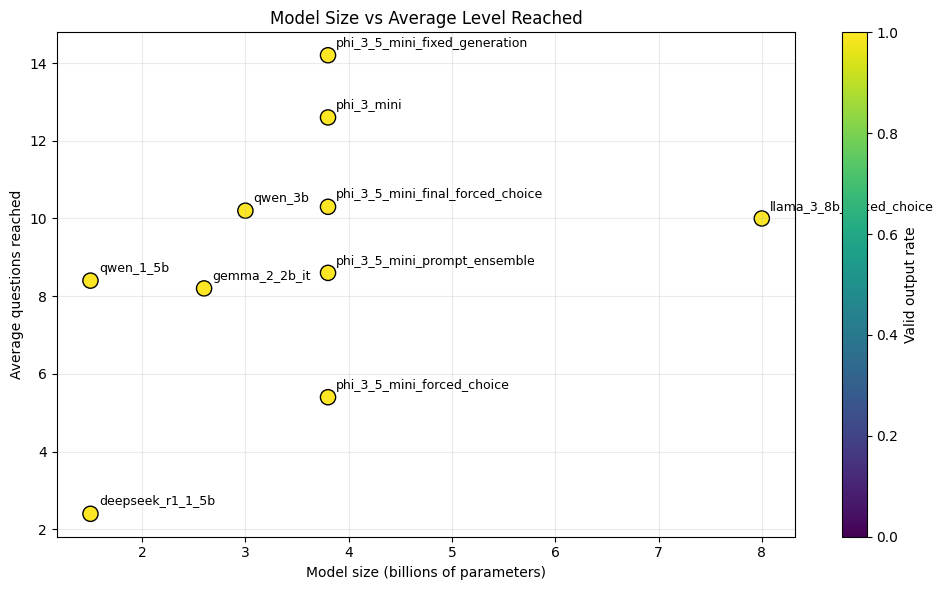

In [ ]:
MODEL_SIZE_BILLIONS = {
    "qwen_1_5b": 1.5,
    "qwen_3b": 3.0,
    "qwen_3b_final": 3.0,
    "qwen_3b_confidence": 3.0,
    "phi_3_mini": 3.8,
    "phi_3_5_mini_fixed_generation": 3.8,
    "phi_3_5_mini_forced_choice": 3.8,
    "phi_3_5_mini_prompt_ensemble": 3.8,
    "deepseek_r1_1_5b": 1.5,
    "deepseek_r1_1_5b_fixed": 1.5,
    "gemma_2_2b_it": 2.6,
    "llama_3_8b_forced_choice": 8.0,
}


def infer_model_size_billion(model_label):
    label = str(model_label)

    if label in MODEL_SIZE_BILLIONS:
        return MODEL_SIZE_BILLIONS[label]
    if "1_5b" in label or "1.5b" in label:
        return 1.5
    if "2_2b" in label or "2b" in label:
        return 2.6
    if "3b" in label or "3_b" in label:
        return 3.0
    if "phi_3" in label or "phi_3_5" in label:
        return 3.8
    if "8b" in label:
        return 8.0

    return None


if final_result_story_table.empty:
    print("Run the comparison summary cell first.")
else:
    model_size_performance_table = final_result_story_table.copy()
    model_size_performance_table["parameter_count_b"] = model_size_performance_table["model_label"].apply(infer_model_size_billion)
    model_size_performance_table = model_size_performance_table.dropna(subset=["parameter_count_b", "average_questions_reached"])

    best_prompt_per_model_size = (
        model_size_performance_table
        .sort_values(["model_label", "average_questions_reached", "best_questions_reached"], ascending=[True, False, False])
        .groupby("model_label")
        .head(1)
        .reset_index(drop=True)
    )

    model_size_performance_table.to_csv("philosophy_psychology_model_size_performance_all_configs.csv", index=False)
    best_prompt_per_model_size.to_csv("philosophy_psychology_model_size_performance_best_per_model.csv", index=False)

    display(best_prompt_per_model_size)

    fig, ax = plt.subplots(figsize=(10, 6))
    scatter = ax.scatter(
        best_prompt_per_model_size["parameter_count_b"],
        best_prompt_per_model_size["average_questions_reached"],
        s=120,
        c=best_prompt_per_model_size.get("valid_output_rate", pd.Series([1] * len(best_prompt_per_model_size))),
        cmap="viridis",
        vmin=0,
        vmax=1,
        edgecolor="black",
    )

    for _, row in best_prompt_per_model_size.iterrows():
        ax.annotate(
            row["model_label"],
            (row["parameter_count_b"], row["average_questions_reached"]),
            textcoords="offset points",
            xytext=(6, 6),
            fontsize=9,
        )

    ax.set_title("Model Size vs Average Level Reached")
    ax.set_xlabel("Model size (billions of parameters)")
    ax.set_ylabel("Average questions reached")
    ax.grid(True, alpha=0.25)
    fig.colorbar(scatter, ax=ax, label="Valid output rate")
    plt.tight_layout()
    plt.savefig("philosophy_psychology_model_size_vs_performance.png", dpi=150, bbox_inches="tight")
    plt.show()


### Model size conclusion

The model-size analysis shows that larger size alone did not guarantee better performance. Llama 3 8B was competitive, but it did not beat Phi-3.5-mini. Qwen 3B improved over Qwen 1.5B, showing that size helped within the Qwen family, but the best overall result came from the corrected Phi setup.

Therefore, the final system choice should be explained using performance, formatting reliability, speed, and confidence behaviour, not parameter count alone.

In [ ]:
# Optional controlled rerun.
# Keep this False until you are ready, because it starts several new game sessions.

RUN_CONTROLLED_FINAL_COMPARISON = False
CONTROLLED_RUNS_PER_SYSTEM = 10

controlled_candidate_specs = [
    {
        "model_id": "microsoft/Phi-3.5-mini-instruct",
        "model_label": "phi_3_5_mini_controlled_forced_choice",
        "prompt_type": "psychology_short",
        "loader": "phi",
        "answer_fn": generate_answer_phi_scored,
    },
    {
        "model_id": "microsoft/Phi-3.5-mini-instruct",
        "model_label": "phi_3_5_mini_controlled_chain_of_thought",
        "prompt_type": "chain_of_thought",
        "loader": "phi",
        "answer_fn": generate_answer_phi_scored,
    },
    {
        "model_id": "microsoft/Phi-3.5-mini-instruct",
        "model_label": "phi_3_5_mini_controlled_ensemble",
        "prompt_type": "phi_ensemble_5prompts",
        "loader": "phi",
        "answer_fn": generate_answer_phi_ensemble,
    },
    {
        "model_id": "Qwen/Qwen2.5-3B-Instruct",
        "model_label": "qwen_3b_controlled_psychology_short",
        "prompt_type": "psychology_short",
        "use_4bit": False,
        "answer_fn": generate_answer_chat_template_with_confidence,
    },
    {
        "model_id": "Qwen/Qwen2.5-3B-Instruct",
        "model_label": "qwen_3b_controlled_elimination",
        "prompt_type": "elimination",
        "use_4bit": False,
        "answer_fn": generate_answer_chat_template_with_confidence,
    },
    {
        "model_id": "Qwen/Qwen2.5-3B-Instruct",
        "model_label": "qwen_3b_controlled_chain_of_thought",
        "prompt_type": "chain_of_thought",
        "use_4bit": False,
        "answer_fn": generate_answer_chat_template_with_confidence,
    },
    {
        "model_id": "google/gemma-2-2b-it",
        "model_label": "gemma_2_2b_controlled_psychology_short",
        "prompt_type": "psychology_short",
        "use_4bit": False,
        "answer_fn": generate_answer_chat_template,
    },
    {
        "model_id": "google/gemma-2-2b-it",
        "model_label": "gemma_2_2b_controlled_chain_of_thought",
        "prompt_type": "chain_of_thought",
        "use_4bit": False,
        "answer_fn": generate_answer_chat_template,
    },
    {
        "model_id": "meta-llama/Meta-Llama-3-8B",
        "model_label": "llama_3_8b_controlled_psychology_short",
        "prompt_type": "psychology_short",
        "use_4bit": True,
        "answer_fn": generate_answer_scored_options,
    },
    {
        "model_id": "meta-llama/Meta-Llama-3-8B",
        "model_label": "llama_3_8b_controlled_chain_of_thought",
        "prompt_type": "chain_of_thought",
        "use_4bit": True,
        "answer_fn": generate_answer_scored_options,
    },
]

if RUN_CONTROLLED_FINAL_COMPARISON:
    controlled_runs = []

    for candidate in controlled_candidate_specs:
        if candidate.get("loader") == "phi":
            load_phi_model()
        else:
            load_chat_model(
                model_id=candidate["model_id"],
                model_label=candidate["model_label"],
                use_4bit=candidate.get("use_4bit", False),
            )

        df_candidate = benchmark_answer_fn(
            answer_fn=candidate["answer_fn"],
            model_label=candidate["model_label"],
            prompt_type=candidate["prompt_type"],
            n_runs=CONTROLLED_RUNS_PER_SYSTEM,
            delay_seconds=1.5,
        )
        controlled_runs.append(df_candidate)

    df_controlled_final = pd.concat(controlled_runs, ignore_index=True)
    controlled_final_summary = make_survival_summary(df_controlled_final).sort_values(
        by=["average_questions_reached", "best_questions_reached", "average_final_earned_amount"],
        ascending=False,
    )

    df_controlled_final.to_csv("philosophy_psychology_controlled_final_question_level_results.csv", index=False)
    controlled_final_summary.to_csv("philosophy_psychology_controlled_final_summary.csv", index=False)

    display(controlled_final_summary)
else:
    print("Controlled final comparison is disabled. Set RUN_CONTROLLED_FINAL_COMPARISON = True when ready.")


Controlled final comparison is disabled. Set RUN_CONTROLLED_FINAL_COMPARISON = True when ready.


### Final report summary

The final practical Philosophy & Psychology system is:

**Phi-3.5-mini fixed generation + `psychology_short` prompt**

This configuration produced the strongest saved result, reaching **14.2 average questions**, a best run of **15**, and **69 / 75 = 0.920 game accuracy**. It also kept a valid-output rate of **1.0** and answered quickly, with an average response time of about **0.44 seconds**.

The results show that performance depended on more than model size. Qwen 3B improved over Qwen 1.5B, but the smaller Phi family still performed best after correcting the generation setup. Llama 8B was competitive but weaker than Phi, while Gemma was a useful middle-range comparison. DeepSeek showed that thinking-style output was not helpful in this timed multiple-choice setting.

RAG was useful but not the final winner. The best static RAG setup, `psych_static_few_shot_psychology`, reached **13.0 average questions** and **62 / 75 = 0.827 game accuracy**. This shows that retrieved context can help factual recall, but in this notebook it did not improve over the best non-RAG Phi system.

The error and confidence analyses add reliability detail. The best Phi fixed-generation system made very few errors, while the Phi forced-choice check showed no overconfident errors and confidence increased with correctness. In contrast, Qwen and Gemma sometimes produced high-confidence wrong answers. Therefore, the final choice is based not only on accuracy, but also on valid formatting, speed, survival, and reliability.